# Modelo 5

Nesse notebook, iremos fazer o tratamento restante dos dados, engenharia de features e testar o modelo

In [2]:
from pathlib import Path
import pandas as pd

data_dir = Path.cwd() / "data"

# Se o notebook estiver em uma subpasta, procura a pasta data acima
if not data_dir.exists():
    for pasta in Path.cwd().parents:
        candidato = pasta / "data"
        if candidato.exists():
            data_dir = candidato
            break

# =========================
# Alarmes
# =========================
alarmes = pd.read_excel(
    data_dir / "Alarmes" / "Histórico de alarmes 23-26.xlsx"
)

# =========================
# Corretiva emergencial
# =========================
emergencial = pd.read_excel(
    data_dir
    / "Corretiva Emergencial"
    / "processados"
    / "ZM01_limpa.xlsx"
)

# =========================
# Corretiva programada
# =========================
programada = pd.read_excel(
    data_dir
    / "Corretiva Programada"
    / "processados"
    / "ZM02_limpa.xlsx"
)

# =========================
# Preventiva
# =========================
preventiva = pd.read_csv(
    data_dir
    / "Preventiva"
    / "preventiva_zm03_limpa.csv"
)

# =========================
# Fluxo / Catracas
# =========================
fluxo = pd.read_excel(
    data_dir
    / "Catracas"
    / "Historico L4.xlsx"
)

In [3]:
print("Alarmes:", alarmes.shape)
print("Emergencial:", emergencial.shape)
print("Programada:", programada.shape)
print("Preventiva:", preventiva.shape)
print("Fluxo:", fluxo.shape)

Alarmes: (1039871, 7)
Emergencial: (10543, 27)
Programada: (1163, 27)
Preventiva: (569, 19)
Fluxo: (1312, 32)


In [4]:
print("\nAlarmes:")
print(alarmes.columns.tolist())

print("\nEmergencial:")
print(emergencial.columns.tolist())

print("\nProgramada:")
print(programada.columns.tolist())

print("\nPreventiva:")
print(preventiva.columns.tolist())

print("\nFluxo:")
print(fluxo.columns.tolist())


Alarmes:
['TAG', 'Horário do Alarme', 'Estação', 'Porta', 'Alarme', 'Horário da Normalizacao', 'Tempo de Normalização']

Emergencial:
['linha_origem', 'tipo_de_nota', 'nota', 'ordem', 'perfil_do_catalogo', 'descricao', 'local_de_instalacao', 'centro_de_trabalho_responsavel', 'inicio_avaria_datetime', 'fim_avaria_datetime', 'duracao_avaria_horas', 'analise_datetime', 'encerramento_datetime', 'indisponivel_flag', 'falha_flag', 'analisada_flag', 'ordem_ausente_flag', 'ordem_repetida_flag', 'comentarios_classificacao_engenharia', 'status_do_usuario_da_ordem', 'texto_longo_da_ordem', 'status_do_sistema_da_ordem', 'sintoma', 'objeto', 'defeito', 'causa', 'acao']

Programada:
['linha_origem', 'tipo_de_nota', 'nota', 'ordem', 'perfil_do_catalogo', 'descricao', 'local_de_instalacao', 'centro_de_trabalho_responsavel', 'inicio_avaria_datetime', 'fim_avaria_datetime', 'duracao_avaria_horas', 'encerramento_datetime', 'indisponivel_flag', 'analisada_flag', 'ordem_ausente_flag', 'ordem_repetida_flag

In [5]:
# ==========================================
# PADRONIZAÇÃO DOS NOMES DAS COLUNAS
# ==========================================

# Alarmes PSD
alarmes = alarmes.rename(columns={
    "TAG": "tag_alarme",
    "Horário do Alarme": "horario_alarme",
    "Estação": "estacao",
    "Porta": "porta",
    "Alarme": "tipo_alarme",
    "Horário da Normalizacao": "horario_normalizacao_alarme",
    "Tempo de Normalização": "tempo_normalizacao_alarme"
})


# Corretiva emergencial
emergencial = emergencial.rename(
    columns={
        coluna: f"{coluna}_emergencial"
        for coluna in emergencial.columns
    }
)


# Corretiva programada
programada = programada.rename(
    columns={
        coluna: f"{coluna}_programada"
        for coluna in programada.columns
    }
)


# Preventiva
preventiva = preventiva.rename(columns={
    "Ordem": "ordem_preventiva",
    "Tipo de ordem": "tipo_ordem_preventiva",
    "Centro de trabalho": "centro_trabalho_preventiva",
    "Local de instalação": "local_instalacao_preventiva",
    "Texto breve": "texto_breve_preventiva",
    "Plano de manutenção": "plano_manutencao_preventiva",
    "Status usuário": "status_usuario_preventiva",
    "Status do sistema": "status_sistema_preventiva",
    "Data-base do início": "data_inicio_preventiva",
    "Hr.início programada": "hora_inicio_preventiva",
    "Data-base do fim": "data_fim_preventiva",
    "Fim-base (hora)": "hora_fim_preventiva",
    "DT_Inicio": "inicio_preventiva",
    "DT_Fim": "fim_preventiva",
    "duracao_h": "duracao_h_preventiva",
    "Estacao_Centro": "estacao_centro_preventiva",
    "Estacao_Local": "estacao_local_preventiva",
    "Estacao": "estacao",
    "cancelada": "cancelada_preventiva"
})

In [6]:
fluxo_bruto = pd.read_excel(
    data_dir / "Catracas" / "Historico L4.xlsx",
    header=None
)

pd.set_option("display.max_columns", None)

display(
    fluxo_bruto.head(10)
)

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,Integrações - Contadores,NaN,NaN,NaN,NaN,Estações Bloqueios,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Totais,NaN
3,NaN,NaN,Integração Linha 9 - Pinheiros,NaN,Integração Linha 2 - Paulista,NaN,Integração Linha 3 - República,NaN,Integração Linha 1 - Luz,NaN,Butantã,NaN,Pinheiros,NaN,Faria Lima,NaN,Paulista,NaN,Luz,NaN,Fradique Coutinho,NaN,Higienópolis Mackenzie,NaN,Oscar Freire,NaN,São Paulo Morumbi,NaN,Vila Sônia,NaN,Total,NaN
4,NaN,Data,Entrada,Saída,Entrada,Saída,Entrada,Saída,Entrada,Saída,Entrada,Saída,Entrada,Saída,Entrada,Saída,Entrada,Saída,Entrada,Saída,Entrada,Saída,Entrada,Saída,Entrada,Saída,Entrada,Saída,Entrada,Saída,Total Entradas,Total Saídas
5,NaN,2023-01-01 00:00:00,14810,18420,21100,15491,20938,27570,26137,31636,6187,8084,829,1168,3207,2941,17027,3860,1219,1594,1971,1773,5760,3159,2823,2591,3524,4898,7228,10051,132760,128338
6,NaN,2023-01-02 00:00:00,55014,52915,43654,43776,60603,62160,79708,74912,18813,18418,4688,5216,17558,18249,9805,11225,3810,3857,8320,8288,9100,10092,13050,12222,12169,13107,24383,24280,360675,358717
7,NaN,2023-01-03 00:00:00,68274,66002,55876,55034,74315,77658,94899,90480,22796,21030,6502,6867,23065,23693,11819,13598,4718,4604,11022,10872,11144,12256,16405,14761,14995,15617,29301,28967,445131,441439
8,NaN,2023-01-04 00:00:00,72074,69470,59432,57883,78793,83311,96180,93408,23399,42844,6794,14912,24327,50270,12104,27652,4638,9732,12040,23318,11895,25380,17182,30994,15616,31988,29802,58551,464276,619713
9,NaN,2023-01-05 00:00:00,72248,70032,60647,59758,79757,83282,97243,94560,23681,21122,6984,7527,25337,26178,12612,14423,4831,4931,12534,12493,12435,13397,18135,16246,15977,16489,30610,29864,473031,470302


In [7]:
# ==========================================
# TRATAMENTO DO FLUXO DE PASSAGEIROS
# ==========================================

# Dados começam na linha 5
fluxo_dados = fluxo_bruto.iloc[5:].copy()

# Data está na coluna 1
fluxo_dados["data"] = pd.to_datetime(
    fluxo_dados[1],
    errors="coerce"
)

# Mapeamento das estações:
# coluna de entrada, coluna de saída
estacoes_fluxo = {
    "BUT": (10, 11),   # Butantã
    "PIN": (12, 13),   # Pinheiros
    "FAL": (14, 15),   # Faria Lima
    "PTA": (16, 17),   # Paulista
    "LUZ": (18, 19),   # Luz
    "FRA": (20, 21),   # Fradique Coutinho
    "HIG": (22, 23),   # Higienópolis-Mackenzie
    "FRE": (24, 25),   # Oscar Freire
    "MBI": (26, 27),   # São Paulo-Morumbi
    "VSO": (28, 29)    # Vila Sônia
}

fluxo_lista = []

for estacao, (col_entrada, col_saida) in estacoes_fluxo.items():

    temp = pd.DataFrame({
        "data": fluxo_dados["data"],
        "estacao": estacao,
        "entrada_fluxo": pd.to_numeric(
            fluxo_dados[col_entrada],
            errors="coerce"
        ),
        "saida_fluxo": pd.to_numeric(
            fluxo_dados[col_saida],
            errors="coerce"
        )
    })

    fluxo_lista.append(temp)

fluxo = pd.concat(
    fluxo_lista,
    ignore_index=True
)

# Remover linhas sem data
fluxo = fluxo.dropna(
    subset=["data"]
)

# Fluxo total da estação no dia
fluxo["total_fluxo"] = (
    fluxo["entrada_fluxo"]
    + fluxo["saida_fluxo"]
)

fluxo = fluxo.sort_values(
    ["data", "estacao"]
).reset_index(drop=True)

display(fluxo.head(20))

,data,estacao,entrada_fluxo,saida_fluxo,total_fluxo
0,2023-01-01,BUT,6187,8084,14271
1,2023-01-01,FAL,3207,2941,6148
2,2023-01-01,FRA,1971,1773,3744
3,2023-01-01,FRE,2823,2591,5414
4,2023-01-01,HIG,5760,3159,8919
5,2023-01-01,LUZ,1219,1594,2813
6,2023-01-01,MBI,3524,4898,8422
7,2023-01-01,PIN,829,1168,1997
8,2023-01-01,PTA,17027,3860,20887
9,2023-01-01,VSO,7228,10051,17279


In [8]:
print("Emergencial:")
display(
    emergencial[
        ["local_de_instalacao_emergencial"]
    ]
    .dropna()
    .drop_duplicates()
    .head(30)
)

print("\nProgramada:")
display(
    programada[
        ["local_de_instalacao_programada"]
    ]
    .dropna()
    .drop_duplicates()
    .head(30)
)

Emergencial:


,local_de_instalacao_emergencial
0,SP04-6-PSD-BUT
2,SP04-6-PSD-BUT-P1S1
4,SP04-6-PSD-BUT-P1S1-PSSE1
6,SP04-6-PSD-BUT-P2S1
7,SP04-6-PSD-BUT-P2S1-PSSE2
8,SP04-6-PSD-BUT-PLT1
18,SP04-6-PSD-BUT-PLT1-PP01PDM
34,SP04-6-PSD-BUT-PLT1-PP02PDM
53,SP04-6-PSD-BUT-PLT1-PP03PDM
62,SP04-6-PSD-BUT-PLT1-PP04PDM



Programada:


,local_de_instalacao_programada
0,SP04-6-PSD-BUT
1,SP04-6-PSD-BUT-P1S1
2,SP04-6-PSD-BUT-P2S1-PSSE2
4,SP04-6-PSD-BUT-PLT1
6,SP04-6-PSD-BUT-PLT1-PFP1
7,SP04-6-PSD-BUT-PLT1-PP05PDM
8,SP04-6-PSD-BUT-PLT1-PP06PSE
9,SP04-6-PSD-BUT-PLT1-PP10PDM
10,SP04-6-PSD-BUT-PLT1-PP15PDM
11,SP04-6-PSD-BUT-PLT1-PP15PSE


In [9]:
print("Quantidade de locais distintos - Emergencial:")
print(
    emergencial[
        "local_de_instalacao_emergencial"
    ].nunique()
)

print("\nQuantidade de locais distintos - Programada:")
print(
    programada[
        "local_de_instalacao_programada"
    ].nunique()
)

Quantidade de locais distintos - Emergencial:
691

Quantidade de locais distintos - Programada:
582


In [10]:
# ==========================================
# CHAVES DE LOCALIZAÇÃO - EMERGENCIAL
# ==========================================

local_emergencial = (
    emergencial["local_de_instalacao_emergencial"]
    .astype("string")
    .str.upper()
    .str.strip()
)

# Estação: código logo após PSD-
emergencial["estacao"] = local_emergencial.str.extract(
    r"PSD-([A-Z]{3})(?:-|$)",
    expand=False
)

# Plataforma: somente quando explicitamente aparece PLT1 ou PLT2
emergencial["plataforma"] = local_emergencial.str.extract(
    r"-PLT(\d+)",
    expand=False
)

# Porta: PP01, PP02, PP24 etc.
emergencial["porta"] = local_emergencial.str.extract(
    r"-PP(\d+)",
    expand=False
)


# ==========================================
# CHAVES DE LOCALIZAÇÃO - PROGRAMADA
# ==========================================

local_programada = (
    programada["local_de_instalacao_programada"]
    .astype("string")
    .str.upper()
    .str.strip()
)

programada["estacao"] = local_programada.str.extract(
    r"PSD-([A-Z]{3})(?:-|$)",
    expand=False
)

programada["plataforma"] = local_programada.str.extract(
    r"-PLT(\d+)",
    expand=False
)

programada["porta"] = local_programada.str.extract(
    r"-PP(\d+)",
    expand=False
)

In [11]:
# Plataforma como texto padronizado
emergencial["plataforma"] = (
    emergencial["plataforma"]
    .astype("string")
)

programada["plataforma"] = (
    programada["plataforma"]
    .astype("string")
)

# Porta sempre com dois dígitos
emergencial["porta"] = (
    emergencial["porta"]
    .astype("string")
    .str.zfill(2)
)

programada["porta"] = (
    programada["porta"]
    .astype("string")
    .str.zfill(2)
)

In [12]:
# ==========================================
# GRANULARIDADE DA LOCALIZAÇÃO
# ==========================================

emergencial["granularidade_localizacao"] = "sem_localizacao"

emergencial.loc[
    emergencial["estacao"].notna(),
    "granularidade_localizacao"
] = "estacao"

emergencial.loc[
    emergencial["plataforma"].notna(),
    "granularidade_localizacao"
] = "plataforma"

emergencial.loc[
    emergencial["porta"].notna(),
    "granularidade_localizacao"
] = "porta"


programada["granularidade_localizacao"] = "sem_localizacao"

programada.loc[
    programada["estacao"].notna(),
    "granularidade_localizacao"
] = "estacao"

programada.loc[
    programada["plataforma"].notna(),
    "granularidade_localizacao"
] = "plataforma"

programada.loc[
    programada["porta"].notna(),
    "granularidade_localizacao"
] = "porta"

In [13]:
print("EMERGENCIAL")
print(
    emergencial["granularidade_localizacao"]
    .value_counts(dropna=False)
)

print("\nPROGRAMADA")
print(
    programada["granularidade_localizacao"]
    .value_counts(dropna=False)
)

EMERGENCIAL
granularidade_localizacao
porta         9360
plataforma     940
estacao        243
Name: count, dtype: int64

PROGRAMADA
granularidade_localizacao
porta         1014
estacao         76
plataforma      73
Name: count, dtype: int64


In [14]:
display(
    emergencial[
        [
            "local_de_instalacao_emergencial",
            "estacao",
            "plataforma",
            "porta",
            "granularidade_localizacao"
        ]
    ].head(30)
)

display(
    programada[
        [
            "local_de_instalacao_programada",
            "estacao",
            "plataforma",
            "porta",
            "granularidade_localizacao"
        ]
    ].head(30)
)

,local_de_instalacao_emergencial,estacao,plataforma,porta,granularidade_localizacao
0,SP04-6-PSD-BUT,BUT,<NA>,<NA>,estacao
1,SP04-6-PSD-BUT,BUT,<NA>,<NA>,estacao
2,SP04-6-PSD-BUT-P1S1,BUT,<NA>,<NA>,estacao
3,SP04-6-PSD-BUT-P1S1,BUT,<NA>,<NA>,estacao
4,SP04-6-PSD-BUT-P1S1-PSSE1,BUT,<NA>,<NA>,estacao
5,SP04-6-PSD-BUT-P1S1-PSSE1,BUT,<NA>,<NA>,estacao
6,SP04-6-PSD-BUT-P2S1,BUT,<NA>,<NA>,estacao
7,SP04-6-PSD-BUT-P2S1-PSSE2,BUT,<NA>,<NA>,estacao
8,SP04-6-PSD-BUT-PLT1,BUT,1,<NA>,plataforma
9,SP04-6-PSD-BUT-PLT1,BUT,1,<NA>,plataforma


,local_de_instalacao_programada,estacao,plataforma,porta,granularidade_localizacao
0,SP04-6-PSD-BUT,BUT,<NA>,<NA>,estacao
1,SP04-6-PSD-BUT-P1S1,BUT,<NA>,<NA>,estacao
2,SP04-6-PSD-BUT-P2S1-PSSE2,BUT,<NA>,<NA>,estacao
3,SP04-6-PSD-BUT-P2S1-PSSE2,BUT,<NA>,<NA>,estacao
4,SP04-6-PSD-BUT-PLT1,BUT,1,<NA>,plataforma
5,SP04-6-PSD-BUT-PLT1,BUT,1,<NA>,plataforma
6,SP04-6-PSD-BUT-PLT1-PFP1,BUT,1,<NA>,plataforma
7,SP04-6-PSD-BUT-PLT1-PP05PDM,BUT,1,05,porta
8,SP04-6-PSD-BUT-PLT1-PP06PSE,BUT,1,06,porta
9,SP04-6-PSD-BUT-PLT1-PP10PDM,BUT,1,10,porta


In [15]:
print("EMERGENCIAL")
print(
    emergencial["granularidade_localizacao"]
    .value_counts(dropna=False)
)

print("\nPROGRAMADA")
print(
    programada["granularidade_localizacao"]
    .value_counts(dropna=False)
)

EMERGENCIAL
granularidade_localizacao
porta         9360
plataforma     940
estacao        243
Name: count, dtype: int64

PROGRAMADA
granularidade_localizacao
porta         1014
estacao         76
plataforma      73
Name: count, dtype: int64


In [16]:
print("\nPercentuais - Emergencial")
print(
    emergencial["granularidade_localizacao"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("\nPercentuais - Programada")
print(
    programada["granularidade_localizacao"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)


Percentuais - Emergencial
granularidade_localizacao
porta         88.78
plataforma     8.92
estacao        2.30
Name: proportion, dtype: float64

Percentuais - Programada
granularidade_localizacao
porta         87.19
estacao        6.53
plataforma     6.28
Name: proportion, dtype: float64


In [17]:
# ==========================================
# EVENTOS ELEGÍVEIS PARA O TARGET
# ==========================================

emergencial["elegivel_target"] = (
    emergencial["granularidade_localizacao"] == "porta"
)

print("Total de manutenções emergenciais:")
print(len(emergencial))

print("\nManutenções emergenciais no nível de porta:")
print(emergencial["elegivel_target"].sum())

print("\nPercentual elegível para o target:")
print(
    round(
        emergencial["elegivel_target"].mean() * 100,
        2
    )
)

Total de manutenções emergenciais:
10543

Manutenções emergenciais no nível de porta:
9360

Percentual elegível para o target:
88.78


In [18]:
# Garantir datetime
emergencial["inicio_avaria_datetime_emergencial"] = pd.to_datetime(
    emergencial["inicio_avaria_datetime_emergencial"],
    errors="coerce"
)

programada["inicio_avaria_datetime_programada"] = pd.to_datetime(
    programada["inicio_avaria_datetime_programada"],
    errors="coerce"
)

alarmes["horario_alarme"] = pd.to_datetime(
    alarmes["horario_alarme"],
    errors="coerce"
)

preventiva["inicio_preventiva"] = pd.to_datetime(
    preventiva["inicio_preventiva"],
    errors="coerce"
)

print("ALARMES")
print(alarmes["horario_alarme"].min())
print(alarmes["horario_alarme"].max())

print("\nEMERGENCIAL")
print(emergencial["inicio_avaria_datetime_emergencial"].min())
print(emergencial["inicio_avaria_datetime_emergencial"].max())

print("\nPROGRAMADA")
print(programada["inicio_avaria_datetime_programada"].min())
print(programada["inicio_avaria_datetime_programada"].max())

print("\nPREVENTIVA")
print(preventiva["inicio_preventiva"].min())
print(preventiva["inicio_preventiva"].max())

print("\nFLUXO")
print(fluxo["data"].min())
print(fluxo["data"].max())

ALARMES
2023-02-27 06:26:56.897000
2025-12-31 23:57:02

EMERGENCIAL
2023-01-01 02:39:00
2026-04-01 22:43:00

PROGRAMADA
2023-01-03 03:55:59
2026-03-28 14:15:00

PREVENTIVA
2022-12-26 05:30:00
2026-03-30 21:30:00

FLUXO
2023-01-01 00:00:00
2026-07-31 00:00:00


In [19]:
# ==========================================
# JANELA TEMPORAL DA MODELAGEM
# ==========================================

inicio_modelagem = pd.Timestamp("2023-02-27")
fim_modelagem = pd.Timestamp("2025-12-31 23:59:59")

horizonte_predicao = pd.Timedelta(days=7)

print("Início da modelagem:", inicio_modelagem)
print("Fim da modelagem:", fim_modelagem)

print(
    "Precisamos de registros emergenciais até:",
    fim_modelagem + horizonte_predicao
)

Início da modelagem: 2023-02-27 00:00:00
Fim da modelagem: 2025-12-31 23:59:59
Precisamos de registros emergenciais até: 2026-01-07 23:59:59


In [20]:
# ==========================================
# EXTRAÇÃO GENERALIZADA DA LOCALIZAÇÃO
# DOS ALARMES PSD
# ==========================================

tag = (
    alarmes["tag_alarme"]
    .astype("string")
    .str.upper()
    .str.strip()
)

# ------------------------------------------------
# PADRÃO 1
# Exemplos:
# PSD_FAL_FAL2_PDM09_OBS
# PSD_FAL_FAL2_MDU09_STS
# ------------------------------------------------

padrao_1 = tag.str.extract(
    r"^PSD_([A-Z]{3})_[A-Z]{3}(\d+)_(?:PDM|MDU)(\d+)"
)

# ------------------------------------------------
# PADRÃO 2
# Exemplos:
# PSD_P_FRA2_PDM22_FO
# PSD_P_MBI1_PDM13LSD
# PSD_P_MBI1_MDU22STS
# ------------------------------------------------

padrao_2 = tag.str.extract(
    r"^PSD_P_([A-Z]{3})(\d+)_(?:PDM|MDU)(\d+)"
)

# Combinar os dois padrões
alarmes["estacao_tag"] = (
    padrao_1[0]
    .fillna(padrao_2[0])
)

alarmes["plataforma"] = (
    padrao_1[1]
    .fillna(padrao_2[1])
)

alarmes["porta_tag"] = (
    padrao_1[2]
    .fillna(padrao_2[2])
)

# Padronizar
alarmes["estacao_tag"] = (
    alarmes["estacao_tag"]
    .astype("string")
    .str.upper()
)

alarmes["plataforma"] = (
    alarmes["plataforma"]
    .astype("string")
)

alarmes["porta_tag"] = (
    alarmes["porta_tag"]
    .astype("string")
    .str.zfill(2)
)

alarmes["porta"] = (
    alarmes["porta"]
    .astype("string")
    .str.extract(r"(\d+)", expand=False)
    .str.zfill(2)
)

alarmes["estacao"] = (
    alarmes["estacao"]
    .astype("string")
    .str.upper()
    .str.strip()
)

In [21]:
print("Total de alarmes:")
print(len(alarmes))

print("\nCom plataforma identificada:")
print(alarmes["plataforma"].notna().sum())

print("\nPercentual com localização:")
print(
    round(
        alarmes["plataforma"].notna().mean() * 100,
        2
    ),
    "%"
)

print("\nConcordância da estação:")
mask_estacao = alarmes["estacao_tag"].notna()

print(
    (
        alarmes.loc[mask_estacao, "estacao"]
        ==
        alarmes.loc[mask_estacao, "estacao_tag"]
    ).mean()
)

print("\nConcordância da porta:")
mask_porta = alarmes["porta_tag"].notna()

print(
    (
        alarmes.loc[mask_porta, "porta"]
        ==
        alarmes.loc[mask_porta, "porta_tag"]
    ).mean()
)

Total de alarmes:
1039871

Com plataforma identificada:
1039685

Percentual com localização:
99.98 %

Concordância da estação:
1.0

Concordância da porta:
1.0


In [22]:
restantes = alarmes[
    alarmes["plataforma"].isna()
].copy()

restantes["estrutura_tag"] = (
    restantes["tag_alarme"]
    .astype("string")
    .str.upper()
    .str.replace(r"\d+", "<N>", regex=True)
)

print("\nAlarmes ainda não mapeados:")
print(len(restantes))

print("\nEstruturas restantes mais frequentes:")

print(
    restantes["estrutura_tag"]
    .value_counts()
    .head(30)
)


Alarmes ainda não mapeados:
186

Estruturas restantes mais frequentes:
estrutura_tag
PSD_P_LUZ<N>_CBTC_BIM_FAULT_VALUE    186
Name: count, dtype: Int64


In [23]:
# ==========================================
# CHAVE ÚNICA DE PORTA
# ==========================================

alarmes["chave_porta"] = (
    alarmes["estacao"].astype("string")
    + "_P" + alarmes["plataforma"].astype("string")
    + "_D" + alarmes["porta"].astype("string")
)

emergencial["chave_porta"] = (
    emergencial["estacao"].astype("string")
    + "_P" + emergencial["plataforma"].astype("string")
    + "_D" + emergencial["porta"].astype("string")
)

programada["chave_porta"] = (
    programada["estacao"].astype("string")
    + "_P" + programada["plataforma"].astype("string")
    + "_D" + programada["porta"].astype("string")
)

In [24]:
alarmes.loc[
    alarmes[["estacao", "plataforma", "porta"]].isna().any(axis=1),
    "chave_porta"
] = pd.NA

emergencial.loc[
    emergencial[["estacao", "plataforma", "porta"]].isna().any(axis=1),
    "chave_porta"
] = pd.NA

programada.loc[
    programada[["estacao", "plataforma", "porta"]].isna().any(axis=1),
    "chave_porta"
] = pd.NA

In [25]:
print("Alarmes com chave_porta:")
print(alarmes["chave_porta"].notna().sum())

print("\nEmergenciais com chave_porta:")
print(emergencial["chave_porta"].notna().sum())

print("\nProgramadas com chave_porta:")
print(programada["chave_porta"].notna().sum())

print("\nExemplos:")
display(
    alarmes[
        ["estacao", "plataforma", "porta", "chave_porta"]
    ].dropna().head(10)
)

Alarmes com chave_porta:
1039685

Emergenciais com chave_porta:
9357

Programadas com chave_porta:
1010

Exemplos:


,estacao,plataforma,porta,chave_porta
0,BUT,1,02,BUT_P1_D02
1,BUT,1,02,BUT_P1_D02
2,BUT,1,02,BUT_P1_D02
3,BUT,1,02,BUT_P1_D02
4,BUT,1,02,BUT_P1_D02
5,BUT,1,02,BUT_P1_D02
6,BUT,1,02,BUT_P1_D02
7,BUT,1,02,BUT_P1_D02
8,BUT,1,02,BUT_P1_D02
9,BUT,1,02,BUT_P1_D02


In [26]:
# ==========================================
# LOCALIZAÇÃO - MANUTENÇÃO PREVENTIVA
# ==========================================

local_preventiva = (
    preventiva["local_instalacao_preventiva"]
    .astype("string")
    .str.upper()
    .str.strip()
)

# Estação
preventiva["estacao"] = local_preventiva.str.extract(
    r"PSD-([A-Z]{3})(?:-|$)",
    expand=False
)

# Plataforma
preventiva["plataforma"] = local_preventiva.str.extract(
    r"-PLT(\d+)",
    expand=False
)

# Porta, somente se existir explicitamente PPxx
preventiva["porta"] = local_preventiva.str.extract(
    r"-PP(\d+)",
    expand=False
)

# Padronização
preventiva["plataforma"] = (
    preventiva["plataforma"]
    .astype("string")
)

preventiva["porta"] = (
    preventiva["porta"]
    .astype("string")
    .str.zfill(2)
)

In [27]:
preventiva["granularidade_localizacao"] = "sem_localizacao"

preventiva.loc[
    preventiva["estacao"].notna(),
    "granularidade_localizacao"
] = "estacao"

preventiva.loc[
    preventiva["plataforma"].notna(),
    "granularidade_localizacao"
] = "plataforma"

preventiva.loc[
    preventiva["porta"].notna(),
    "granularidade_localizacao"
] = "porta"

In [28]:
preventiva["chave_porta"] = (
    preventiva["estacao"].astype("string")
    + "_P" + preventiva["plataforma"].astype("string")
    + "_D" + preventiva["porta"].astype("string")
)

preventiva.loc[
    preventiva[
        ["estacao", "plataforma", "porta"]
    ].isna().any(axis=1),
    "chave_porta"
] = pd.NA

In [29]:
print("Granularidade da preventiva:")
print(
    preventiva["granularidade_localizacao"]
    .value_counts(dropna=False)
)

print("\nPercentuais:")
print(
    preventiva["granularidade_localizacao"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("\nPreventivas com chave de porta:")
print(
    preventiva["chave_porta"]
    .notna()
    .sum()
)

Granularidade da preventiva:
granularidade_localizacao
plataforma         313
estacao            173
sem_localizacao     83
Name: count, dtype: int64

Percentuais:
granularidade_localizacao
plataforma         55.01
estacao            30.40
sem_localizacao    14.59
Name: proportion, dtype: float64

Preventivas com chave de porta:
0


In [30]:
display(
    preventiva[
        [
            "local_instalacao_preventiva",
            "estacao",
            "plataforma",
            "porta",
            "granularidade_localizacao",
            "chave_porta"
        ]
    ].head(30)
)

,local_instalacao_preventiva,estacao,plataforma,porta,granularidade_localizacao,chave_porta
0,SP04-6-PSD-PTA,PTA,<NA>,<NA>,estacao,<NA>
1,SP04-6-PSD-FAL,FAL,<NA>,<NA>,estacao,<NA>
2,SP04-6-PSD-PIN,PIN,<NA>,<NA>,estacao,<NA>
3,SP04-6-PSD-BUT,BUT,<NA>,<NA>,estacao,<NA>
4,SP04-6-PSD-VSO-PLT1,VSO,1,<NA>,plataforma,<NA>
5,SP04-6-PSD-PTA,PTA,<NA>,<NA>,estacao,<NA>
6,SP04-6-PSD-FAL,FAL,<NA>,<NA>,estacao,<NA>
7,SP04-6-PSD-PIN,PIN,<NA>,<NA>,estacao,<NA>
8,SP04-6-PSD-BUT,BUT,<NA>,<NA>,estacao,<NA>
9,SP04-6-PSD-MBI-PLT2,MBI,2,<NA>,plataforma,<NA>


In [31]:
# ==========================================
# CHAVES HIERÁRQUICAS DE LOCALIZAÇÃO
# ==========================================

# ---------- ALARMES ----------

alarmes["chave_estacao"] = alarmes["estacao"]

alarmes["chave_plataforma"] = (
    alarmes["estacao"].astype("string")
    + "_P"
    + alarmes["plataforma"].astype("string")
)

alarmes.loc[
    alarmes[["estacao", "plataforma"]].isna().any(axis=1),
    "chave_plataforma"
] = pd.NA


# ---------- EMERGENCIAL ----------

emergencial["chave_estacao"] = emergencial["estacao"]

emergencial["chave_plataforma"] = (
    emergencial["estacao"].astype("string")
    + "_P"
    + emergencial["plataforma"].astype("string")
)

emergencial.loc[
    emergencial[["estacao", "plataforma"]].isna().any(axis=1),
    "chave_plataforma"
] = pd.NA


# ---------- PROGRAMADA ----------

programada["chave_estacao"] = programada["estacao"]

programada["chave_plataforma"] = (
    programada["estacao"].astype("string")
    + "_P"
    + programada["plataforma"].astype("string")
)

programada.loc[
    programada[["estacao", "plataforma"]].isna().any(axis=1),
    "chave_plataforma"
] = pd.NA


# ---------- PREVENTIVA ----------

preventiva["chave_estacao"] = preventiva["estacao"]

preventiva["chave_plataforma"] = (
    preventiva["estacao"].astype("string")
    + "_P"
    + preventiva["plataforma"].astype("string")
)

preventiva.loc[
    preventiva[["estacao", "plataforma"]].isna().any(axis=1),
    "chave_plataforma"
] = pd.NA

In [32]:
print("ALARMES")
print("Estação:", alarmes["chave_estacao"].notna().sum())
print("Plataforma:", alarmes["chave_plataforma"].notna().sum())
print("Porta:", alarmes["chave_porta"].notna().sum())

print("\nEMERGENCIAL")
print("Estação:", emergencial["chave_estacao"].notna().sum())
print("Plataforma:", emergencial["chave_plataforma"].notna().sum())
print("Porta:", emergencial["chave_porta"].notna().sum())

print("\nPROGRAMADA")
print("Estação:", programada["chave_estacao"].notna().sum())
print("Plataforma:", programada["chave_plataforma"].notna().sum())
print("Porta:", programada["chave_porta"].notna().sum())

print("\nPREVENTIVA")
print("Estação:", preventiva["chave_estacao"].notna().sum())
print("Plataforma:", preventiva["chave_plataforma"].notna().sum())
print("Porta:", preventiva["chave_porta"].notna().sum())

ALARMES
Estação: 1039871
Plataforma: 1039685
Porta: 1039685

EMERGENCIAL
Estação: 10543
Plataforma: 10297
Porta: 9357

PROGRAMADA
Estação: 1163
Plataforma: 1083
Porta: 1010

PREVENTIVA
Estação: 486
Plataforma: 313
Porta: 0


In [33]:
# ==========================================
# UNIVERSO DE PORTAS
# ==========================================

portas = (
    alarmes[
        ["estacao", "plataforma", "porta", "chave_porta"]
    ]
    .dropna(subset=["chave_porta"])
    .drop_duplicates()
    .sort_values(
        ["estacao", "plataforma", "porta"]
    )
    .reset_index(drop=True)
)

print("Quantidade de portas distintas:")
print(len(portas))

print("\nPortas por estação:")
print(
    portas["estacao"]
    .value_counts()
    .sort_index()
)

display(portas.head(20))

Quantidade de portas distintas:
518

Portas por estação:
estacao
BUT    48
FAL    48
FRA    48
FRE    38
HIG    48
LUZ    48
MBI    48
PIN    48
PTA    48
REP    48
VSO    48
Name: count, dtype: Int64


,estacao,plataforma,porta,chave_porta
0,BUT,1,01,BUT_P1_D01
1,BUT,1,02,BUT_P1_D02
2,BUT,1,03,BUT_P1_D03
3,BUT,1,04,BUT_P1_D04
4,BUT,1,05,BUT_P1_D05
5,BUT,1,06,BUT_P1_D06
6,BUT,1,07,BUT_P1_D07
7,BUT,1,08,BUT_P1_D08
8,BUT,1,09,BUT_P1_D09
9,BUT,1,10,BUT_P1_D10


In [34]:
datas_modelagem = pd.DataFrame({
    "data": pd.date_range(
        start=inicio_modelagem.normalize(),
        end=fim_modelagem.normalize(),
        freq="D"
    )
})

print("Quantidade de dias:")
print(len(datas_modelagem))

print(
    datas_modelagem["data"].min(),
    "→",
    datas_modelagem["data"].max()
)

Quantidade de dias:
1039
2023-02-27 00:00:00 → 2025-12-31 00:00:00


In [35]:
# ==========================================
# BASE DIÁRIA PORTA × DATA
# ==========================================

portas["join_key"] = 1
datas_modelagem["join_key"] = 1

base_modelo = (
    portas
    .merge(
        datas_modelagem,
        on="join_key"
    )
    .drop(columns="join_key")
)

portas = portas.drop(columns="join_key")
datas_modelagem = datas_modelagem.drop(columns="join_key")

base_modelo = base_modelo[
    [
        "data",
        "estacao",
        "plataforma",
        "porta",
        "chave_porta"
    ]
].sort_values(
    ["chave_porta", "data"]
).reset_index(drop=True)

print("Formato da base:")
print(base_modelo.shape)

display(base_modelo.head(20))

Formato da base:
(538202, 5)


,data,estacao,plataforma,porta,chave_porta
0,2023-02-27,BUT,1,01,BUT_P1_D01
1,2023-02-28,BUT,1,01,BUT_P1_D01
2,2023-03-01,BUT,1,01,BUT_P1_D01
3,2023-03-02,BUT,1,01,BUT_P1_D01
4,2023-03-03,BUT,1,01,BUT_P1_D01
5,2023-03-04,BUT,1,01,BUT_P1_D01
6,2023-03-05,BUT,1,01,BUT_P1_D01
7,2023-03-06,BUT,1,01,BUT_P1_D01
8,2023-03-07,BUT,1,01,BUT_P1_D01
9,2023-03-08,BUT,1,01,BUT_P1_D01


In [36]:
# ==========================================
# EVENTOS EMERGENCIAIS PARA O TARGET
# ==========================================

eventos_emergenciais = (
    emergencial[
        emergencial["elegivel_target"]
        & emergencial["inicio_avaria_datetime_emergencial"].notna()
        & emergencial["chave_porta"].notna()
    ]
    [
        [
            "chave_porta",
            "inicio_avaria_datetime_emergencial"
        ]
    ]
    .drop_duplicates()
    .copy()
)

eventos_emergenciais = eventos_emergenciais.sort_values(
    ["inicio_avaria_datetime_emergencial", "chave_porta"]
).reset_index(drop=True)

print("Eventos emergenciais utilizáveis:")
print(len(eventos_emergenciais))

print("\nPortas diferentes com manutenção emergencial:")
print(eventos_emergenciais["chave_porta"].nunique())

print("\nPeríodo:")
print(eventos_emergenciais["inicio_avaria_datetime_emergencial"].min())
print(eventos_emergenciais["inicio_avaria_datetime_emergencial"].max())

Eventos emergenciais utilizáveis:
9253

Portas diferentes com manutenção emergencial:
524

Período:
2023-01-01 02:39:00
2026-04-01 22:43:00


In [37]:
# ==========================================
# PRÓXIMA MANUTENÇÃO EMERGENCIAL
# ==========================================

base_target = base_modelo.copy()

base_target["data"] = pd.to_datetime(
    base_target["data"]
)

base_target = base_target.sort_values(
    ["data", "chave_porta"]
).reset_index(drop=True)

eventos_emergenciais = eventos_emergenciais.sort_values(
    ["inicio_avaria_datetime_emergencial", "chave_porta"]
).reset_index(drop=True)

base_target = pd.merge_asof(
    base_target,
    eventos_emergenciais,
    left_on="data",
    right_on="inicio_avaria_datetime_emergencial",
    by="chave_porta",
    direction="forward",
    allow_exact_matches=True
)

In [38]:
base_target["dias_ate_emergencial"] = (
    base_target["inicio_avaria_datetime_emergencial"]
    - base_target["data"]
).dt.total_seconds() / 86400

In [39]:
# ==========================================
# TARGET: MANUTENÇÃO EMERGENCIAL EM ATÉ 7 DIAS
# ==========================================

base_target["manutencao_emergencial_7d"] = (
    (base_target["dias_ate_emergencial"] >= 0)
    & (base_target["dias_ate_emergencial"] < 7)
).astype(int)

In [40]:
print("Distribuição do target:")
print(
    base_target["manutencao_emergencial_7d"]
    .value_counts()
)

print("\nPercentual:")
print(
    base_target["manutencao_emergencial_7d"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("\nDias até a emergência nos positivos:")
print(
    base_target.loc[
        base_target["manutencao_emergencial_7d"] == 1,
        "dias_ate_emergencial"
    ].describe()
)

Distribuição do target:
manutencao_emergencial_7d
0    496548
1     41654
Name: count, dtype: int64

Percentual:
manutencao_emergencial_7d
0    92.26
1     7.74
Name: proportion, dtype: float64

Dias até a emergência nos positivos:
count    41654.000000
mean         3.385910
std          2.031515
min          0.000694
25%          1.594022
50%          3.345122
75%          5.234028
max          6.999456
Name: dias_ate_emergencial, dtype: float64


In [41]:
display(
    base_target[
        base_target["manutencao_emergencial_7d"] == 1
    ][
        [
            "data",
            "estacao",
            "plataforma",
            "porta",
            "chave_porta",
            "inicio_avaria_datetime_emergencial",
            "dias_ate_emergencial",
            "manutencao_emergencial_7d"
        ]
    ].head(30)
)

,data,estacao,plataforma,porta,chave_porta,inicio_avaria_datetime_emergencial,dias_ate_emergencial,manutencao_emergencial_7d
24,2023-02-27,BUT,2,01,BUT_P2_D01,2023-03-04 14:34:00,5.606944,1
49,2023-02-27,FAL,1,02,FAL_P1_D02,2023-03-01 13:00:00,2.541667,1
60,2023-02-27,FAL,1,13,FAL_P1_D13,2023-02-27 18:02:00,0.751389,1
93,2023-02-27,FAL,2,22,FAL_P2_D22,2023-03-04 19:31:00,5.813194,1
103,2023-02-27,FRA,1,08,FRA_P1_D08,2023-03-02 14:31:00,3.604861,1
119,2023-02-27,FRA,1,24,FRA_P1_D24,2023-02-28 04:16:00,1.177778,1
135,2023-02-27,FRA,2,16,FRA_P2_D16,2023-03-01 07:28:00,2.311111,1
150,2023-02-27,FRE,1,08,FRE_P1_D08,2023-03-01 21:55:00,2.913194,1
176,2023-02-27,FRE,2,17,FRE_P2_D17,2023-03-05 04:49:00,6.200694,1
196,2023-02-27,HIG,1,15,HIG_P1_D15,2023-03-05 13:25:00,6.559028,1


In [42]:
print("Distribuição de falha_flag na ZM01:")

print(
    emergencial[
        "falha_flag_emergencial"
    ].value_counts(dropna=False)
)

print("\nPercentuais:")

print(
    emergencial[
        "falha_flag_emergencial"
    ]
    .value_counts(
        normalize=True,
        dropna=False
    )
    .mul(100)
    .round(2)
)

Distribuição de falha_flag na ZM01:
falha_flag_emergencial
False    7150
True     3393
Name: count, dtype: int64

Percentuais:
falha_flag_emergencial
False    67.82
True     32.18
Name: proportion, dtype: float64


In [43]:
print("ZM01 no nível de porta:")

print(
    emergencial.loc[
        emergencial["elegivel_target"],
        "falha_flag_emergencial"
    ].value_counts(dropna=False)
)

print("\nPercentuais:")

print(
    emergencial.loc[
        emergencial["elegivel_target"],
        "falha_flag_emergencial"
    ]
    .value_counts(
        normalize=True,
        dropna=False
    )
    .mul(100)
    .round(2)
)

ZM01 no nível de porta:
falha_flag_emergencial
False    6275
True     3085
Name: count, dtype: int64

Percentuais:
falha_flag_emergencial
False    67.04
True     32.96
Name: proportion, dtype: float64


In [44]:
pd.crosstab(
    emergencial["falha_flag_emergencial"],
    emergencial["indisponivel_flag_emergencial"],
    dropna=False,
    margins=True
)

indisponivel_flag_emergencial,False,True,All
falha_flag_emergencial,,,
False,2578,4572,7150
True,993,2400,3393
All,3571,6972,10543


In [45]:
# ==========================================
# EVENTOS DE FALHA PARA O TARGET
# ==========================================

eventos_falha = (
    emergencial[
        (emergencial["elegivel_target"])
        & (emergencial["falha_flag_emergencial"] == True)
        & (emergencial["inicio_avaria_datetime_emergencial"].notna())
        & (emergencial["chave_porta"].notna())
    ]
    [
        [
            "chave_porta",
            "inicio_avaria_datetime_emergencial"
        ]
    ]
    .drop_duplicates()
    .copy()
)

eventos_falha = eventos_falha.sort_values(
    ["inicio_avaria_datetime_emergencial", "chave_porta"]
).reset_index(drop=True)

print("Eventos de falha utilizáveis:")
print(len(eventos_falha))

print("\nPortas que apresentaram pelo menos uma falha:")
print(eventos_falha["chave_porta"].nunique())

print("\nPeríodo:")
print(eventos_falha["inicio_avaria_datetime_emergencial"].min())
print(eventos_falha["inicio_avaria_datetime_emergencial"].max())

Eventos de falha utilizáveis:
3057

Portas que apresentaram pelo menos uma falha:
491

Período:
2023-01-01 02:39:00
2026-04-01 22:43:00


In [46]:
# ==========================================
# ENCONTRAR A PRÓXIMA FALHA DA PORTA
# ==========================================

base_target = base_modelo.copy()

base_target["data"] = pd.to_datetime(
    base_target["data"]
)

base_target = base_target.sort_values(
    ["data", "chave_porta"]
).reset_index(drop=True)

eventos_falha = eventos_falha.sort_values(
    ["inicio_avaria_datetime_emergencial", "chave_porta"]
).reset_index(drop=True)

base_target = pd.merge_asof(
    base_target,
    eventos_falha,
    left_on="data",
    right_on="inicio_avaria_datetime_emergencial",
    by="chave_porta",
    direction="forward",
    allow_exact_matches=True
)

In [47]:
base_target["dias_ate_falha"] = (
    base_target["inicio_avaria_datetime_emergencial"]
    - base_target["data"]
).dt.total_seconds() / 86400

In [48]:
# ==========================================
# TARGET FINAL
# FALHA EMERGENCIAL NOS PRÓXIMOS 7 DIAS
# ==========================================

base_target["falha_emergencial_7d"] = (
    (base_target["dias_ate_falha"] >= 0)
    & (base_target["dias_ate_falha"] < 7)
).astype(int)

In [49]:
print("Distribuição do target:")
print(
    base_target["falha_emergencial_7d"]
    .value_counts()
)

print("\nPercentual:")
print(
    base_target["falha_emergencial_7d"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("\nDias até a falha nos positivos:")
print(
    base_target.loc[
        base_target["falha_emergencial_7d"] == 1,
        "dias_ate_falha"
    ].describe()
)

Distribuição do target:
falha_emergencial_7d
0    522753
1     15449
Name: count, dtype: int64

Percentual:
falha_emergencial_7d
0    97.13
1     2.87
Name: proportion, dtype: float64

Dias até a falha nos positivos:
count    15449.000000
mean         3.458805
std          2.023054
min          0.001389
25%          1.662674
50%          3.409722
75%          5.284722
max          6.999456
Name: dias_ate_falha, dtype: float64


In [50]:
# ==========================================
# FEATURES DE HISTÓRICO DE ALARMES
# ==========================================

# Data do alarme
alarmes["data"] = (
    pd.to_datetime(
        alarmes["horario_alarme"],
        errors="coerce"
    )
    .dt.normalize()
)

# Considerar somente alarmes com porta identificada
alarmes_porta = alarmes[
    alarmes["chave_porta"].notna()
    & alarmes["data"].notna()
].copy()

# Quantidade de alarmes por porta e dia
alarmes_diarios = (
    alarmes_porta
    .groupby(
        ["chave_porta", "data"]
    )
    .agg(
        qtd_alarmes_dia=(
            "tipo_alarme",
            "count"
        )
    )
    .reset_index()
)

display(alarmes_diarios.head())

,chave_porta,data,qtd_alarmes_dia
0,BUT_P1_D01,2024-01-21,583
1,BUT_P1_D01,2024-04-04,4
2,BUT_P1_D01,2024-04-09,2
3,BUT_P1_D01,2024-04-13,520
4,BUT_P1_D01,2024-05-23,460


In [51]:
base_features = base_target.merge(
    alarmes_diarios,
    on=["chave_porta", "data"],
    how="left"
)

# Dias sem alarmes = 0
base_features["qtd_alarmes_dia"] = (
    base_features["qtd_alarmes_dia"]
    .fillna(0)
    .astype(int)
)

base_features = base_features.sort_values(
    ["chave_porta", "data"]
).reset_index(drop=True)

In [52]:
# ==========================================
# JANELAS TEMPORAIS
# ==========================================

base_features["qtd_alarmes_1d"] = (
    base_features
    .groupby("chave_porta")["qtd_alarmes_dia"]
    .transform(
        lambda x: x.shift(1).rolling(
            window=1,
            min_periods=1
        ).sum()
    )
)

base_features["qtd_alarmes_3d"] = (
    base_features
    .groupby("chave_porta")["qtd_alarmes_dia"]
    .transform(
        lambda x: x.shift(1).rolling(
            window=3,
            min_periods=1
        ).sum()
    )
)

base_features["qtd_alarmes_7d"] = (
    base_features
    .groupby("chave_porta")["qtd_alarmes_dia"]
    .transform(
        lambda x: x.shift(1).rolling(
            window=7,
            min_periods=1
        ).sum()
    )
)

base_features["qtd_alarmes_30d"] = (
    base_features
    .groupby("chave_porta")["qtd_alarmes_dia"]
    .transform(
        lambda x: x.shift(1).rolling(
            window=30,
            min_periods=1
        ).sum()
    )
)

In [53]:
display(
    base_features[
        [
            "data",
            "chave_porta",
            "qtd_alarmes_dia",
            "qtd_alarmes_1d",
            "qtd_alarmes_3d",
            "qtd_alarmes_7d",
            "qtd_alarmes_30d",
            "falha_emergencial_7d"
        ]
    ].head(80)
)

,data,chave_porta,qtd_alarmes_dia,qtd_alarmes_1d,qtd_alarmes_3d,qtd_alarmes_7d,qtd_alarmes_30d,falha_emergencial_7d
0,2023-02-27,BUT_P1_D01,0,NaN,NaN,NaN,NaN,0
1,2023-02-28,BUT_P1_D01,0,0.0,0.0,0.0,0.0,0
2,2023-03-01,BUT_P1_D01,0,0.0,0.0,0.0,0.0,0
3,2023-03-02,BUT_P1_D01,0,0.0,0.0,0.0,0.0,0
4,2023-03-03,BUT_P1_D01,0,0.0,0.0,0.0,0.0,0
...,...,...,...,...,...,...,...,...
75,2023-05-13,BUT_P1_D01,0,0.0,0.0,0.0,0.0,0
76,2023-05-14,BUT_P1_D01,0,0.0,0.0,0.0,0.0,0
77,2023-05-15,BUT_P1_D01,0,0.0,0.0,0.0,0.0,0
78,2023-05-16,BUT_P1_D01,0,0.0,0.0,0.0,0.0,0


In [54]:
print(
    base_features[
        [
            "qtd_alarmes_1d",
            "qtd_alarmes_3d",
            "qtd_alarmes_7d",
            "qtd_alarmes_30d"
        ]
    ].describe()
)

       qtd_alarmes_1d  qtd_alarmes_3d  qtd_alarmes_7d  qtd_alarmes_30d
count   537684.000000   537684.000000   537684.000000    537684.000000
mean         1.932377        5.791831       13.489745        57.432228
std         31.641211       56.801406       90.246222       207.890617
min          0.000000        0.000000        0.000000         0.000000
25%          0.000000        0.000000        0.000000         0.000000
50%          0.000000        0.000000        0.000000         0.000000
75%          0.000000        0.000000        2.000000        43.000000
max       5668.000000     5668.000000     5674.000000      5674.000000


In [55]:
# Maiores quantidades de alarmes registrados por uma porta em um dia
top_alarmes_dia = (
    alarmes_diarios
    .sort_values(
        "qtd_alarmes_dia",
        ascending=False
    )
    .head(40)
)

display(top_alarmes_dia)

,chave_porta,data,qtd_alarmes_dia
5711,FRA_P1_D03,2024-05-29,5668
7079,FRA_P1_D19,2024-05-13,4990
7136,FRA_P1_D21,2024-05-09,4890
5768,FRA_P1_D04,2024-08-02,3001
7221,FRA_P1_D22,2024-06-28,2990
7098,FRA_P1_D20,2024-08-17,2958
6478,FRA_P1_D12,2024-08-27,2903
7222,FRA_P1_D22,2024-10-01,2848
5860,FRA_P1_D06,2024-08-03,2739
6975,FRA_P1_D17,2024-09-04,2685


In [56]:
# Estatísticas percentis para entender a cauda da distribuição
print(
    alarmes_diarios["qtd_alarmes_dia"]
    .quantile([
        0.90,
        0.95,
        0.99,
        0.995,
        0.999,
        1.0
    ])
)

0.900      38.000
0.950      78.000
0.990     333.360
0.995     537.840
0.999    1671.472
1.000    5668.000
Name: qtd_alarmes_dia, dtype: float64


In [57]:
top_portas_datas = (
    top_alarmes_dia[
        ["chave_porta", "data"]
    ]
)

detalhes_top = alarmes_porta.merge(
    top_portas_datas,
    on=["chave_porta", "data"],
    how="inner"
)

print(
    detalhes_top[
        [
            "chave_porta",
            "data",
            "tipo_alarme"
        ]
    ]
    .value_counts()
    .head(50)
)

chave_porta  data        tipo_alarme
FRA_P1_D03   2024-05-29  STS            762
                         FO             718
FRA_P1_D19   2024-05-13  CSD            716
                         CA             714
                         OBS            712
                         FC             712
                         FO             712
                         LSD            712
                         OA             712
FRA_P1_D21   2024-05-09  OBS            700
                         FC             700
FRA_P1_D03   2024-05-29  OBS            698
                         CA             698
                         CSD            698
                         FC             698
                         LSD            698
                         OA             698
FRA_P1_D21   2024-05-09  CA             698
                         CSD            698
                         FO             698
                         LSD            698
                         OA            

In [58]:
# ==========================================
# INVESTIGAÇÃO DO MAIOR PICO DE ALARMES
# ==========================================

caso_extremo = alarmes_porta[
    (alarmes_porta["chave_porta"] == "FRA_P1_D03")
    & (alarmes_porta["data"] == pd.Timestamp("2024-05-29"))
].copy()

caso_extremo = caso_extremo.sort_values(
    "horario_alarme"
)

print("Total de registros:")
print(len(caso_extremo))

print("\nTipos de alarme:")
print(
    caso_extremo["tipo_alarme"]
    .value_counts()
)

print("\nPrimeiros registros:")
display(
    caso_extremo[
        [
            "horario_alarme",
            "tipo_alarme",
            "horario_normalizacao_alarme",
            "tag_alarme"
        ]
    ].head(30)
)

Total de registros:
5668

Tipos de alarme:
tipo_alarme
STS    762
FO     718
CA     698
OBS    698
CSD    698
LSD    698
OA     698
FC     698
Name: count, dtype: int64

Primeiros registros:


,horario_alarme,tipo_alarme,horario_normalizacao_alarme,tag_alarme
318810,2024-05-29 09:58:06.187,STS,2024-05-29 09:58:21.187,PSD_P_FRA1_MDU03_STS
220173,2024-05-29 09:58:06.187,STS,2024-05-29 09:58:21.187,PSD_P_FRA1_MDU03_STS
223826,2024-05-29 09:58:06.187,FO,2024-05-29 09:58:21.187,PSD_P_FRA1_PDM03_FO
323753,2024-05-29 09:58:06.187,FO,2024-05-29 09:58:21.187,PSD_P_FRA1_PDM03_FO
318811,2024-05-29 09:58:26.187,STS,2024-05-29 09:58:41.187,PSD_P_FRA1_MDU03_STS
323754,2024-05-29 09:58:26.187,FO,2024-05-29 09:58:41.187,PSD_P_FRA1_PDM03_FO
220174,2024-05-29 09:58:26.187,STS,2024-05-29 09:58:41.187,PSD_P_FRA1_MDU03_STS
223827,2024-05-29 09:58:26.187,FO,2024-05-29 09:58:41.187,PSD_P_FRA1_PDM03_FO
223828,2024-05-29 09:58:51.187,FO,2024-05-29 09:58:56.203,PSD_P_FRA1_PDM03_FO
220175,2024-05-29 09:58:51.187,STS,2024-05-29 09:58:56.203,PSD_P_FRA1_MDU03_STS


In [59]:
duplicados_exatos = caso_extremo.duplicated(
    subset=[
        "chave_porta",
        "horario_alarme",
        "tipo_alarme"
    ],
    keep=False
)

print("Registros envolvidos em duplicatas exatas:")
print(duplicados_exatos.sum())

print("\nPercentual:")
print(
    round(
        duplicados_exatos.mean() * 100,
        2
    ),
    "%"
)

Registros envolvidos em duplicatas exatas:
5668

Percentual:
100.0 %


In [60]:
caso_extremo["segundos_desde_alarme_anterior"] = (
    caso_extremo["horario_alarme"]
    .diff()
    .dt.total_seconds()
)

print(
    caso_extremo[
        "segundos_desde_alarme_anterior"
    ].describe(
        percentiles=[
            0.01,
            0.05,
            0.10,
            0.25,
            0.50,
            0.75,
            0.90,
            0.99
        ]
    )
)

count    5667.000000
mean        0.103230
std         4.147504
min         0.000000
1%          0.000000
5%          0.000000
10%         0.000000
25%         0.000000
50%         0.000000
75%         0.000000
90%         0.000000
99%         0.000000
max       280.000000
Name: segundos_desde_alarme_anterior, dtype: float64


In [61]:
# ==========================================
# VERIFICAÇÃO GLOBAL DE DUPLICATAS
# ==========================================

colunas_evento = [
    "tag_alarme",
    "horario_alarme",
    "tipo_alarme",
    "horario_normalizacao_alarme"
]

duplicados = alarmes.duplicated(
    subset=colunas_evento,
    keep=False
)

print("Total de registros:")
print(len(alarmes))

print("\nRegistros envolvidos em duplicatas:")
print(duplicados.sum())

print("\nPercentual envolvido em duplicatas:")
print(
    round(
        duplicados.mean() * 100,
        2
    ),
    "%"
)

print("\nQuantidade de linhas redundantes:")
print(
    alarmes.duplicated(
        subset=colunas_evento,
        keep="first"
    ).sum()
)

Total de registros:
1039871

Registros envolvidos em duplicatas:
262898

Percentual envolvido em duplicatas:
25.28 %

Quantidade de linhas redundantes:
131449


In [62]:
alarmes_limpos = (
    alarmes
    .drop_duplicates(
        subset=colunas_evento,
        keep="first"
    )
    .copy()
)

print("Antes:", len(alarmes))
print("Depois:", len(alarmes_limpos))
print("Removidos:", len(alarmes) - len(alarmes_limpos))

Antes: 1039871
Depois: 908422
Removidos: 131449


In [63]:
caso_extremo_limpo = alarmes_limpos[
    (alarmes_limpos["chave_porta"] == "FRA_P1_D03")
    & (alarmes_limpos["data"] == pd.Timestamp("2024-05-29"))
]

print(
    caso_extremo_limpo["tipo_alarme"]
    .value_counts()
)

print("\nTotal:")
print(len(caso_extremo_limpo))

tipo_alarme
STS    381
FO     359
OBS    349
CA     349
CSD    349
FC     349
LSD    349
OA     349
Name: count, dtype: int64

Total:
2834


In [64]:
alarmes_porta = alarmes_limpos[
    alarmes_limpos["chave_porta"].notna()
    & alarmes_limpos["data"].notna()
].copy()

alarmes_diarios = (
    alarmes_porta
    .groupby(
        ["chave_porta", "data"]
    )
    .agg(
        qtd_alarmes_dia=(
            "tipo_alarme",
            "count"
        )
    )
    .reset_index()
)

In [65]:
caso_extremo_limpo = (
    caso_extremo_limpo
    .sort_values("horario_alarme")
    .copy()
)

caso_extremo_limpo["segundos_desde_alarme_anterior"] = (
    caso_extremo_limpo["horario_alarme"]
    .diff()
    .dt.total_seconds()
)

print(
    caso_extremo_limpo[
        "segundos_desde_alarme_anterior"
    ].describe(
        percentiles=[
            0.01,
            0.05,
            0.10,
            0.25,
            0.50,
            0.75,
            0.90,
            0.95,
            0.99
        ]
    )
)

count    2833.000000
mean        0.206497
std         5.864673
min         0.000000
1%          0.000000
5%          0.000000
10%         0.000000
25%         0.000000
50%         0.000000
75%         0.000000
90%         0.000000
95%         0.000000
99%         0.000000
max       280.000000
Name: segundos_desde_alarme_anterior, dtype: float64


In [66]:
print("Total de alarmes limpos:")
print(len(caso_extremo_limpo))

print("\nHorários de disparo distintos:")
print(
    caso_extremo_limpo[
        "horario_alarme"
    ].nunique()
)

print("\nQuantidade média de alarmes por instante:")
print(
    len(caso_extremo_limpo)
    /
    caso_extremo_limpo["horario_alarme"].nunique()
)

Total de alarmes limpos:
2834

Horários de disparo distintos:
10

Quantidade média de alarmes por instante:
283.4


In [67]:
# Verificar quantos eventos realmente distintos existem
# considerando TAG + horário de disparo

print("Combinações únicas TAG + horário:")
print(
    caso_extremo_limpo[
        ["tag_alarme", "horario_alarme"]
    ]
    .drop_duplicates()
    .shape[0]
)

print("\nQuantidade de registros por TAG + horário:")
print(
    caso_extremo_limpo
    .groupby(
        ["tag_alarme", "horario_alarme"]
    )
    .size()
    .sort_values(ascending=False)
    .head(30)
)

Combinações únicas TAG + horário:
26

Quantidade de registros por TAG + horário:
tag_alarme              horario_alarme         
PSD_P_FRA1_MDU03_STS    2024-05-29 10:07:51.193    372
PSD_P_FRA1_PDM03_FO     2024-05-29 10:07:51.193    350
PSD_P_FRA1_PDM03_CA     2024-05-29 10:07:51.193    349
PSD_P_FRA1_PDM03_FC     2024-05-29 10:07:51.193    349
PSD_P_FRA1_PDM03_OA     2024-05-29 10:07:51.193    349
PSD_P_FRA1_PDM03_LSD    2024-05-29 10:07:51.193    349
PSD_FRA_FRA1_PDM03_OBS  2024-05-29 10:07:51.193    349
PSD_P_FRA1_PDM03_CSD    2024-05-29 10:07:51.193    349
PSD_P_FRA1_MDU03_STS    2024-05-29 09:58:26.187      1
                        2024-05-29 09:58:06.187      1
                        2024-05-29 10:06:06.190      1
                        2024-05-29 10:05:41.190      1
                        2024-05-29 10:05:06.190      1
                        2024-05-29 10:03:56.190      1
                        2024-05-29 09:59:16.190      1
                        2024-05-29 09:59:01.18

In [68]:
normalizacoes_por_evento = (
    caso_extremo_limpo
    .groupby(
        ["tag_alarme", "horario_alarme"]
    )
    ["horario_normalizacao_alarme"]
    .nunique()
    .sort_values(ascending=False)
)

print(
    normalizacoes_por_evento.head(30)
)

print("\nEventos com mais de uma normalização:")
print(
    (normalizacoes_por_evento > 1).sum()
)

tag_alarme              horario_alarme         
PSD_P_FRA1_MDU03_STS    2024-05-29 10:07:51.193    372
PSD_P_FRA1_PDM03_FO     2024-05-29 10:07:51.193    350
PSD_P_FRA1_PDM03_CA     2024-05-29 10:07:51.193    349
PSD_P_FRA1_PDM03_FC     2024-05-29 10:07:51.193    349
PSD_P_FRA1_PDM03_OA     2024-05-29 10:07:51.193    349
PSD_P_FRA1_PDM03_LSD    2024-05-29 10:07:51.193    349
PSD_FRA_FRA1_PDM03_OBS  2024-05-29 10:07:51.193    349
PSD_P_FRA1_PDM03_CSD    2024-05-29 10:07:51.193    349
PSD_P_FRA1_MDU03_STS    2024-05-29 09:58:26.187      1
                        2024-05-29 09:58:06.187      1
                        2024-05-29 10:06:06.190      1
                        2024-05-29 10:05:41.190      1
                        2024-05-29 10:05:06.190      1
                        2024-05-29 10:03:56.190      1
                        2024-05-29 09:59:16.190      1
                        2024-05-29 09:59:01.187      1
                        2024-05-29 09:58:51.187      1
PSD_P_FRA1_PDM03_

In [69]:
# ==========================================
# BASE DE EVENTOS ÚNICOS DE ALARME
# ==========================================

alarmes_eventos = (
    alarmes
    .sort_values("horario_alarme")
    .drop_duplicates(
        subset=[
            "tag_alarme",
            "horario_alarme"
        ],
        keep="first"
    )
    .copy()
)

print("Registros originais:")
print(len(alarmes))

print("\nEventos únicos:")
print(len(alarmes_eventos))

print("\nRegistros redundantes removidos:")
print(
    len(alarmes)
    - len(alarmes_eventos)
)

print("\nPercentual de redução:")
print(
    round(
        (1 - len(alarmes_eventos) / len(alarmes)) * 100,
        2
    ),
    "%"
)

Registros originais:
1039871

Eventos únicos:
345454

Registros redundantes removidos:
694417

Percentual de redução:
66.78 %


In [70]:
caso_extremo_eventos = alarmes_eventos[
    (alarmes_eventos["chave_porta"] == "FRA_P1_D03")
    & (
        alarmes_eventos["data"]
        == pd.Timestamp("2024-05-29")
    )
]

print("Eventos únicos no dia:")
print(len(caso_extremo_eventos))

print("\nPor tipo:")
print(
    caso_extremo_eventos[
        "tipo_alarme"
    ].value_counts()
)

Eventos únicos no dia:
26

Por tipo:
tipo_alarme
FO     10
STS    10
CA      1
FC      1
OA      1
LSD     1
OBS     1
CSD     1
Name: count, dtype: int64


In [71]:
alarmes_porta = alarmes_eventos[
    alarmes_eventos["chave_porta"].notna()
    & alarmes_eventos["data"].notna()
].copy()

alarmes_diarios = (
    alarmes_porta
    .groupby(
        ["chave_porta", "data"]
    )
    .agg(
        qtd_alarmes_dia=(
            "tipo_alarme",
            "count"
        )
    )
    .reset_index()
)

In [72]:
display(
    alarmes_diarios
    .sort_values(
        "qtd_alarmes_dia",
        ascending=False
    )
    .head(30)
)

,chave_porta,data,qtd_alarmes_dia
32454,PTA_P1_D03,2024-04-24,694
28265,PIN_P1_D24,2025-02-17,622
13447,HIG_P2_D10,2024-11-27,612
24948,MBI_P2_D09,2025-05-15,516
43577,VSO_P1_D01,2025-02-12,500
209,BUT_P1_D07,2025-12-09,474
27495,PIN_P1_D14,2024-09-24,466
27494,PIN_P1_D14,2024-09-23,458
43582,VSO_P1_D01,2025-02-17,454
25957,MBI_P2_D24,2025-12-27,439


In [73]:
# ==========================================
# RECONSTRUÇÃO DAS FEATURES DE ALARMES
# USANDO EVENTOS ÚNICOS
# ==========================================

alarmes_porta = alarmes_eventos[
    alarmes_eventos["chave_porta"].notna()
    & alarmes_eventos["data"].notna()
].copy()

# Quantidade de eventos únicos por porta e dia
alarmes_diarios = (
    alarmes_porta
    .groupby(["chave_porta", "data"])
    .agg(
        qtd_alarmes_dia=("tipo_alarme", "count")
    )
    .reset_index()
)

# Recomeçar a base de features a partir do target
base_features = base_target.merge(
    alarmes_diarios,
    on=["chave_porta", "data"],
    how="left"
)

base_features["qtd_alarmes_dia"] = (
    base_features["qtd_alarmes_dia"]
    .fillna(0)
    .astype(int)
)

base_features = base_features.sort_values(
    ["chave_porta", "data"]
).reset_index(drop=True)

In [74]:
base_features["qtd_alarmes_1d"] = (
    base_features
    .groupby("chave_porta")["qtd_alarmes_dia"]
    .transform(
        lambda x: x.shift(1).rolling(1, min_periods=1).sum()
    )
)

base_features["qtd_alarmes_3d"] = (
    base_features
    .groupby("chave_porta")["qtd_alarmes_dia"]
    .transform(
        lambda x: x.shift(1).rolling(3, min_periods=1).sum()
    )
)

base_features["qtd_alarmes_7d"] = (
    base_features
    .groupby("chave_porta")["qtd_alarmes_dia"]
    .transform(
        lambda x: x.shift(1).rolling(7, min_periods=1).sum()
    )
)

base_features["qtd_alarmes_30d"] = (
    base_features
    .groupby("chave_porta")["qtd_alarmes_dia"]
    .transform(
        lambda x: x.shift(1).rolling(30, min_periods=1).sum()
    )
)

In [75]:
data_inicio_modelo_efetivo = (
    inicio_modelagem.normalize()
    + pd.Timedelta(days=30)
)

base_features = base_features[
    base_features["data"] >= data_inicio_modelo_efetivo
].copy()

base_features = base_features.reset_index(drop=True)

In [76]:
print(
    base_features[
        [
            "qtd_alarmes_1d",
            "qtd_alarmes_3d",
            "qtd_alarmes_7d",
            "qtd_alarmes_30d"
        ]
    ].describe()
)

print("\nValores ausentes:")
print(
    base_features[
        [
            "qtd_alarmes_1d",
            "qtd_alarmes_3d",
            "qtd_alarmes_7d",
            "qtd_alarmes_30d"
        ]
    ].isna().sum()
)

       qtd_alarmes_1d  qtd_alarmes_3d  qtd_alarmes_7d  qtd_alarmes_30d
count   522662.000000   522662.000000   522662.000000    522662.000000
mean         0.659357        1.973700        4.582221        19.284861
std          6.011014       14.472107       27.896997        80.835201
min          0.000000        0.000000        0.000000         0.000000
25%          0.000000        0.000000        0.000000         0.000000
50%          0.000000        0.000000        0.000000         0.000000
75%          0.000000        0.000000        2.000000        16.000000
max        694.000000     1260.000000     1982.000000      4113.000000

Valores ausentes:
qtd_alarmes_1d     0
qtd_alarmes_3d     0
qtd_alarmes_7d     0
qtd_alarmes_30d    0
dtype: int64


In [77]:
print(
    alarmes_eventos["tipo_alarme"]
    .value_counts()
)

tipo_alarme
LSD      65151
FC       55928
FO       55389
OBS      52079
STS      45074
OA       38480
CA       16445
CSD      13500
RCE       3275
VALUE      133
Name: count, dtype: int64


In [78]:
# ==========================================
# QUANTIDADE DIÁRIA POR TIPO DE ALARME
# ==========================================

alarmes_tipo_dia = (
    alarmes_porta
    .groupby(
        [
            "chave_porta",
            "data",
            "tipo_alarme"
        ]
    )
    .size()
    .unstack(fill_value=0)
    .reset_index()
)

display(alarmes_tipo_dia.head())

tipo_alarme,chave_porta,data,CA,CSD,FC,FO,LSD,OA,OBS,RCE,STS
0,BUT_P1_D01,2024-01-21,1,1,1,1,1,1,1,0,0
1,BUT_P1_D01,2024-04-04,0,0,1,0,0,0,1,0,0
2,BUT_P1_D01,2024-04-09,0,0,0,0,0,1,0,0,0
3,BUT_P1_D01,2024-04-13,1,1,1,1,1,1,1,0,0
4,BUT_P1_D01,2024-05-23,1,1,1,1,1,1,1,0,1


In [79]:
colunas_tipos = [
    coluna
    for coluna in alarmes_tipo_dia.columns
    if coluna not in ["chave_porta", "data"]
]

alarmes_tipo_dia = alarmes_tipo_dia.rename(
    columns={
        coluna: f"qtd_{coluna.lower()}_dia"
        for coluna in colunas_tipos
    }
)

display(alarmes_tipo_dia.head())

tipo_alarme,chave_porta,data,qtd_ca_dia,qtd_csd_dia,qtd_fc_dia,qtd_fo_dia,qtd_lsd_dia,qtd_oa_dia,qtd_obs_dia,qtd_rce_dia,qtd_sts_dia
0,BUT_P1_D01,2024-01-21,1,1,1,1,1,1,1,0,0
1,BUT_P1_D01,2024-04-04,0,0,1,0,0,0,1,0,0
2,BUT_P1_D01,2024-04-09,0,0,0,0,0,1,0,0,0
3,BUT_P1_D01,2024-04-13,1,1,1,1,1,1,1,0,0
4,BUT_P1_D01,2024-05-23,1,1,1,1,1,1,1,0,1


In [80]:
base_features = base_features.merge(
    alarmes_tipo_dia,
    on=["chave_porta", "data"],
    how="left"
)

colunas_tipo_dia = [
    coluna
    for coluna in base_features.columns
    if coluna.startswith("qtd_")
    and coluna.endswith("_dia")
    and coluna != "qtd_alarmes_dia"
]

base_features[colunas_tipo_dia] = (
    base_features[colunas_tipo_dia]
    .fillna(0)
)

In [81]:
for coluna in colunas_tipo_dia:

    nome_tipo = (
        coluna
        .replace("qtd_", "")
        .replace("_dia", "")
    )

    base_features[f"qtd_{nome_tipo}_7d"] = (
        base_features
        .groupby("chave_porta")[coluna]
        .transform(
            lambda x: x.shift(1)
            .rolling(
                7,
                min_periods=1
            )
            .sum()
        )
    )

    base_features[f"qtd_{nome_tipo}_30d"] = (
        base_features
        .groupby("chave_porta")[coluna]
        .transform(
            lambda x: x.shift(1)
            .rolling(
                30,
                min_periods=1
            )
            .sum()
        )
    )

In [82]:
colunas_features_tipo = [
    coluna
    for coluna in base_features.columns
    if (
        coluna.endswith("_7d")
        or coluna.endswith("_30d")
    )
    and coluna.startswith("qtd_")
]

print(
    base_features[
        colunas_features_tipo
    ].describe().T
)

                    count       mean        std  min  25%  50%   75%     max
qtd_alarmes_7d   522662.0   4.582221  27.896997  0.0  0.0  0.0   2.0  1982.0
qtd_alarmes_30d  522662.0  19.284861  80.835201  0.0  0.0  0.0  16.0  4113.0
qtd_ca_7d        522144.0   0.219570   0.695614  0.0  0.0  0.0   0.0    40.0
qtd_ca_30d       522144.0   0.930992   1.831848  0.0  0.0  0.0   1.0    49.0
qtd_csd_7d       522144.0   0.180299   0.605166  0.0  0.0  0.0   0.0    40.0
qtd_csd_30d      522144.0   0.766187   1.627270  0.0  0.0  0.0   1.0    48.0
qtd_fc_7d        522144.0   0.746890   2.580135  0.0  0.0  0.0   0.0   308.0
qtd_fc_30d       522144.0   3.173852   8.871761  0.0  0.0  0.0   2.0   475.0
qtd_fo_7d        522144.0   0.732294  10.942552  0.0  0.0  0.0   0.0   988.0
qtd_fo_30d       522144.0   3.050501  30.272670  0.0  0.0  0.0   1.0  1578.0
qtd_lsd_7d       522144.0   0.860113  13.798228  0.0  0.0  0.0   0.0  1936.0
qtd_lsd_30d      522144.0   3.595951  42.792865  0.0  0.0  0.0   1.0  4097.0

In [83]:
# ==========================================
# RECONSTRUIR FEATURES POR TIPO DE ALARME
# ANTES DO CORTE DE AQUECIMENTO
# ==========================================

base_features = base_target.merge(
    alarmes_diarios,
    on=["chave_porta", "data"],
    how="left"
)

base_features["qtd_alarmes_dia"] = (
    base_features["qtd_alarmes_dia"]
    .fillna(0)
    .astype(int)
)

base_features = base_features.merge(
    alarmes_tipo_dia,
    on=["chave_porta", "data"],
    how="left"
)

base_features = base_features.sort_values(
    ["chave_porta", "data"]
).reset_index(drop=True)

# Colunas referentes aos tipos de alarme no próprio dia
colunas_tipo_dia = [
    coluna
    for coluna in base_features.columns
    if coluna.startswith("qtd_")
    and coluna.endswith("_dia")
    and coluna != "qtd_alarmes_dia"
]

base_features[colunas_tipo_dia] = (
    base_features[colunas_tipo_dia]
    .fillna(0)
)

In [84]:
for janela in [1, 3, 7, 30]:

    base_features[f"qtd_alarmes_{janela}d"] = (
        base_features
        .groupby("chave_porta")["qtd_alarmes_dia"]
        .transform(
            lambda x: x.shift(1)
            .rolling(
                janela,
                min_periods=1
            )
            .sum()
        )
    )

In [85]:
for coluna in colunas_tipo_dia:

    tipo = (
        coluna
        .replace("qtd_", "")
        .replace("_dia", "")
    )

    for janela in [7, 30]:

        base_features[f"qtd_{tipo}_{janela}d"] = (
            base_features
            .groupby("chave_porta")[coluna]
            .transform(
                lambda x: x.shift(1)
                .rolling(
                    janela,
                    min_periods=1
                )
                .sum()
            )
        )

In [86]:
data_inicio_modelo_efetivo = (
    inicio_modelagem.normalize()
    + pd.Timedelta(days=30)
)

base_features = base_features[
    base_features["data"] >= data_inicio_modelo_efetivo
].copy()

base_features = base_features.reset_index(drop=True)

In [87]:
colunas_historicas = [
    coluna
    for coluna in base_features.columns
    if (
        coluna.startswith("qtd_")
        and (
            coluna.endswith("_1d")
            or coluna.endswith("_3d")
            or coluna.endswith("_7d")
            or coluna.endswith("_30d")
        )
    )
]

print(
    base_features[
        colunas_historicas
    ].isna().sum()
)

qtd_alarmes_1d     0
qtd_alarmes_3d     0
qtd_alarmes_7d     0
qtd_alarmes_30d    0
qtd_ca_7d          0
qtd_ca_30d         0
qtd_csd_7d         0
qtd_csd_30d        0
qtd_fc_7d          0
qtd_fc_30d         0
qtd_fo_7d          0
qtd_fo_30d         0
qtd_lsd_7d         0
qtd_lsd_30d        0
qtd_oa_7d          0
qtd_oa_30d         0
qtd_obs_7d         0
qtd_obs_30d        0
qtd_rce_7d         0
qtd_rce_30d        0
qtd_sts_7d         0
qtd_sts_30d        0
dtype: int64


In [88]:
# ==========================================
# DIAS COM ALGUM ALARME
# ==========================================

base_features["teve_alarme_dia"] = (
    base_features["qtd_alarmes_dia"] > 0
).astype(int)

In [89]:
for janela in [7, 30]:

    base_features[f"dias_com_alarme_{janela}d"] = (
        base_features
        .groupby("chave_porta")["teve_alarme_dia"]
        .transform(
            lambda x: x.shift(1)
            .rolling(
                janela,
                min_periods=1
            )
            .sum()
        )
    )

In [90]:
tipos_alarme = [
    coluna
    .replace("qtd_", "")
    .replace("_dia", "")
    for coluna in colunas_tipo_dia
]

tipos_alarme

['ca', 'csd', 'fc', 'fo', 'lsd', 'oa', 'obs', 'rce', 'sts']

In [91]:
colunas_tipos_7d = [
    f"qtd_{tipo}_7d"
    for tipo in tipos_alarme
]

colunas_tipos_30d = [
    f"qtd_{tipo}_30d"
    for tipo in tipos_alarme
]

In [92]:
base_features["tipos_alarme_7d"] = (
    base_features[colunas_tipos_7d]
    .gt(0)
    .sum(axis=1)
)

base_features["tipos_alarme_30d"] = (
    base_features[colunas_tipos_30d]
    .gt(0)
    .sum(axis=1)
)

In [93]:
base_features["alarmes_por_dia_ativo_7d"] = (
    base_features["qtd_alarmes_7d"]
    /
    base_features["dias_com_alarme_7d"].replace(0, pd.NA)
)

base_features["alarmes_por_dia_ativo_30d"] = (
    base_features["qtd_alarmes_30d"]
    /
    base_features["dias_com_alarme_30d"].replace(0, pd.NA)
)

In [94]:
base_features[
    [
        "alarmes_por_dia_ativo_7d",
        "alarmes_por_dia_ativo_30d"
    ]
] = (
    base_features[
        [
            "alarmes_por_dia_ativo_7d",
            "alarmes_por_dia_ativo_30d"
        ]
    ]
    .fillna(0)
    .astype(float)
)

In [95]:
base_features["media_alarmes_7d"] = (
    base_features["qtd_alarmes_7d"] / 7
)

base_features["media_alarmes_30d"] = (
    base_features["qtd_alarmes_30d"] / 30
)

In [96]:
base_features["aceleracao_alarmes_7d_30d"] = (
    base_features["media_alarmes_7d"]
    /
    (base_features["media_alarmes_30d"] + 1)
)

In [97]:
novas_features = [
    "dias_com_alarme_7d",
    "dias_com_alarme_30d",
    "tipos_alarme_7d",
    "tipos_alarme_30d",
    "alarmes_por_dia_ativo_7d",
    "alarmes_por_dia_ativo_30d",
    "media_alarmes_7d",
    "media_alarmes_30d",
    "aceleracao_alarmes_7d_30d"
]

print(
    base_features[
        novas_features
    ].describe().T
)

print("\nValores ausentes:")
print(
    base_features[
        novas_features
    ].isna().sum()
)

                              count      mean       std  min  25%  50%  \
dias_com_alarme_7d         522144.0  0.609330  1.257335  0.0  0.0  0.0   
dias_com_alarme_30d        522144.0  2.583077  4.558168  0.0  0.0  0.0   
tipos_alarme_7d            522662.0  1.286346  2.448457  0.0  0.0  0.0   
tipos_alarme_30d           522662.0  3.073455  3.408391  0.0  0.0  0.0   
alarmes_por_dia_ativo_7d   522662.0  1.867516  7.051463  0.0  0.0  0.0   
alarmes_por_dia_ativo_30d  522662.0  3.451101  7.767893  0.0  0.0  0.0   
media_alarmes_7d           522662.0  0.654603  3.985285  0.0  0.0  0.0   
media_alarmes_30d          522662.0  0.642829  2.694507  0.0  0.0  0.0   
aceleracao_alarmes_7d_30d  522662.0  0.199922  0.423693  0.0  0.0  0.0   

                                75%         max  
dias_com_alarme_7d         1.000000    7.000000  
dias_com_alarme_30d        3.000000   30.000000  
tipos_alarme_7d            2.000000    8.000000  
tipos_alarme_30d           7.000000    8.000000  
alarmes_p

In [98]:
# ==========================================
# CORRIGIR DIAS COM ALARME
# ==========================================

historico_dias_alarme = base_target[
    ["chave_porta", "data"]
].copy()

historico_dias_alarme = historico_dias_alarme.merge(
    alarmes_diarios,
    on=["chave_porta", "data"],
    how="left"
)

historico_dias_alarme["qtd_alarmes_dia"] = (
    historico_dias_alarme["qtd_alarmes_dia"]
    .fillna(0)
)

historico_dias_alarme["teve_alarme_dia"] = (
    historico_dias_alarme["qtd_alarmes_dia"] > 0
).astype(int)

historico_dias_alarme = historico_dias_alarme.sort_values(
    ["chave_porta", "data"]
).reset_index(drop=True)

In [99]:
for janela in [7, 30]:

    historico_dias_alarme[
        f"dias_com_alarme_{janela}d"
    ] = (
        historico_dias_alarme
        .groupby("chave_porta")["teve_alarme_dia"]
        .transform(
            lambda x: x.shift(1)
            .rolling(
                janela,
                min_periods=1
            )
            .sum()
        )
    )

In [100]:
historico_dias_alarme = (
    historico_dias_alarme[
        historico_dias_alarme["data"]
        >= data_inicio_modelo_efetivo
    ][
        [
            "chave_porta",
            "data",
            "dias_com_alarme_7d",
            "dias_com_alarme_30d"
        ]
    ]
    .copy()
)

In [101]:
base_features = base_features.drop(
    columns=[
        "dias_com_alarme_7d",
        "dias_com_alarme_30d"
    ],
    errors="ignore"
)

base_features = base_features.merge(
    historico_dias_alarme,
    on=["chave_porta", "data"],
    how="left"
)

In [102]:
base_features["alarmes_por_dia_ativo_7d"] = (
    base_features["qtd_alarmes_7d"]
    /
    base_features["dias_com_alarme_7d"].replace(0, pd.NA)
)

base_features["alarmes_por_dia_ativo_30d"] = (
    base_features["qtd_alarmes_30d"]
    /
    base_features["dias_com_alarme_30d"].replace(0, pd.NA)
)

base_features[
    [
        "alarmes_por_dia_ativo_7d",
        "alarmes_por_dia_ativo_30d"
    ]
] = (
    base_features[
        [
            "alarmes_por_dia_ativo_7d",
            "alarmes_por_dia_ativo_30d"
        ]
    ]
    .fillna(0)
    .astype(float)
)

In [103]:
print(
    base_features[
        [
            "dias_com_alarme_7d",
            "dias_com_alarme_30d",
            "alarmes_por_dia_ativo_7d",
            "alarmes_por_dia_ativo_30d"
        ]
    ].isna().sum()
)

dias_com_alarme_7d           0
dias_com_alarme_30d          0
alarmes_por_dia_ativo_7d     0
alarmes_por_dia_ativo_30d    0
dtype: int64


In [104]:
# ==========================================
# TEMPO DESDE O ÚLTIMO ALARME
# ==========================================

historico_recencia = base_target[
    ["chave_porta", "data"]
].copy()

historico_recencia = historico_recencia.merge(
    alarmes_diarios,
    on=["chave_porta", "data"],
    how="left"
)

historico_recencia["qtd_alarmes_dia"] = (
    historico_recencia["qtd_alarmes_dia"]
    .fillna(0)
)

historico_recencia = historico_recencia.sort_values(
    ["chave_porta", "data"]
).reset_index(drop=True)

In [105]:
historico_recencia["data_com_alarme"] = (
    historico_recencia["data"]
    .where(
        historico_recencia["qtd_alarmes_dia"] > 0
    )
)

In [106]:
historico_recencia["data_ultimo_alarme"] = (
    historico_recencia
    .groupby("chave_porta")["data_com_alarme"]
    .transform(
        lambda x: x.shift(1).ffill()
    )
)

In [107]:
historico_recencia["dias_desde_ultimo_alarme"] = (
    historico_recencia["data"]
    - historico_recencia["data_ultimo_alarme"]
).dt.days

In [108]:
historico_recencia["sem_alarme_anterior"] = (
    historico_recencia["data_ultimo_alarme"]
    .isna()
    .astype(int)
)

In [109]:
historico_recencia = historico_recencia[
    historico_recencia["data"] >= data_inicio_modelo_efetivo
][
    [
        "chave_porta",
        "data",
        "dias_desde_ultimo_alarme",
        "sem_alarme_anterior"
    ]
].copy()

In [110]:
base_features = base_features.merge(
    historico_recencia,
    on=["chave_porta", "data"],
    how="left"
)

In [111]:
print(
    base_features[
        [
            "dias_desde_ultimo_alarme",
            "sem_alarme_anterior"
        ]
    ].describe()
)

print("\nSem alarme anterior:")
print(
    base_features["sem_alarme_anterior"]
    .value_counts()
)

print("\nValores ausentes:")
print(
    base_features[
        [
            "dias_desde_ultimo_alarme",
            "sem_alarme_anterior"
        ]
    ].isna().sum()
)

       dias_desde_ultimo_alarme  sem_alarme_anterior
count             378731.000000        522662.000000
mean                  62.713876             0.275381
std                  149.174391             0.446706
min                    1.000000             0.000000
25%                    4.000000             0.000000
50%                   13.000000             0.000000
75%                   43.000000             1.000000
max                 1036.000000             1.000000

Sem alarme anterior:
sem_alarme_anterior
0    378731
1    143931
Name: count, dtype: int64

Valores ausentes:
dias_desde_ultimo_alarme    143931
sem_alarme_anterior              0
dtype: int64


In [112]:
# ==========================================
# HISTÓRICO DE FALHAS ZM01 DA PORTA
# ==========================================

falhas_historicas = (
    eventos_falha[
        [
            "chave_porta",
            "inicio_avaria_datetime_emergencial"
        ]
    ]
    .copy()
)

falhas_historicas["data_falha"] = (
    pd.to_datetime(
        falhas_historicas["inicio_avaria_datetime_emergencial"]
    )
    .dt.normalize()
)

falhas_historicas = (
    falhas_historicas
    .drop_duplicates(
        subset=[
            "chave_porta",
            "inicio_avaria_datetime_emergencial"
        ]
    )
    .sort_values(
        [
            "chave_porta",
            "inicio_avaria_datetime_emergencial"
        ]
    )
    .reset_index(drop=True)
)

print("Eventos históricos de falha:")
print(len(falhas_historicas))

display(falhas_historicas.head())

Eventos históricos de falha:
3057


,chave_porta,inicio_avaria_datetime_emergencial,data_falha
0,BUT_P1_D01,2023-02-12 10:35:00,2023-02-12
1,BUT_P1_D01,2024-01-21 12:22:00,2024-01-21
2,BUT_P1_D01,2024-06-17 05:45:00,2024-06-17
3,BUT_P1_D01,2024-09-01 16:16:00,2024-09-01
4,BUT_P1_D01,2024-11-27 20:04:00,2024-11-27


In [113]:
print("\nIntervalo temporal:")
print(
    falhas_historicas[
        "inicio_avaria_datetime_emergencial"
    ].min()
)

print(
    falhas_historicas[
        "inicio_avaria_datetime_emergencial"
    ].max()
)

print("\nFalhas por porta:")
print(
    falhas_historicas
    .groupby("chave_porta")
    .size()
    .describe()
)

print("\nPortas com pelo menos uma falha:")
print(
    falhas_historicas[
        "chave_porta"
    ].nunique()
)


Intervalo temporal:
2023-01-01 02:39:00
2026-04-01 22:43:00

Falhas por porta:
count    491.000000
mean       6.226069
std        3.845991
min        1.000000
25%        3.000000
50%        6.000000
75%        8.000000
max       23.000000
dtype: float64

Portas com pelo menos uma falha:
491


In [114]:
# ==========================================
# FALHAS HISTÓRICAS POR PORTA E DIA
# ==========================================

falhas_dia = (
    falhas_historicas
    .groupby(
        ["chave_porta", "data_falha"]
    )
    .size()
    .reset_index(
        name="qtd_falhas_dia"
    )
)

falhas_dia = falhas_dia.rename(
    columns={
        "data_falha": "data"
    }
)

display(falhas_dia.head())

,chave_porta,data,qtd_falhas_dia
0,BUT_P1_D01,2023-02-12,1
1,BUT_P1_D01,2024-01-21,1
2,BUT_P1_D01,2024-06-17,1
3,BUT_P1_D01,2024-09-01,1
4,BUT_P1_D01,2024-11-27,1


In [115]:
historico_falhas = base_target[
    ["chave_porta", "data"]
].copy()

historico_falhas = historico_falhas.merge(
    falhas_dia,
    on=["chave_porta", "data"],
    how="left"
)

historico_falhas["qtd_falhas_dia"] = (
    historico_falhas["qtd_falhas_dia"]
    .fillna(0)
)

historico_falhas = historico_falhas.sort_values(
    ["chave_porta", "data"]
).reset_index(drop=True)

In [116]:
historico_falhas["qtd_falhas_30d"] = (
    historico_falhas
    .groupby("chave_porta")["qtd_falhas_dia"]
    .transform(
        lambda x: x.shift(1)
        .rolling(
            30,
            min_periods=1
        )
        .sum()
    )
)

historico_falhas["qtd_falhas_90d"] = (
    historico_falhas
    .groupby("chave_porta")["qtd_falhas_dia"]
    .transform(
        lambda x: x.shift(1)
        .rolling(
            90,
            min_periods=1
        )
        .sum()
    )
)

In [117]:
historico_falhas["qtd_falhas_anteriores"] = (
    historico_falhas
    .groupby("chave_porta")["qtd_falhas_dia"]
    .transform(
        lambda x: x.shift(1)
        .fillna(0)
        .cumsum()
    )
)

In [118]:
historico_falhas["data_com_falha"] = (
    historico_falhas["data"]
    .where(
        historico_falhas["qtd_falhas_dia"] > 0
    )
)

historico_falhas["data_ultima_falha"] = (
    historico_falhas
    .groupby("chave_porta")["data_com_falha"]
    .transform(
        lambda x: x.shift(1).ffill()
    )
)

historico_falhas["dias_desde_ultima_falha"] = (
    historico_falhas["data"]
    - historico_falhas["data_ultima_falha"]
).dt.days

historico_falhas["sem_falha_anterior"] = (
    historico_falhas["data_ultima_falha"]
    .isna()
    .astype(int)
)

In [119]:
historico_falhas = historico_falhas[
    historico_falhas["data"]
    >= data_inicio_modelo_efetivo
][
    [
        "chave_porta",
        "data",
        "qtd_falhas_30d",
        "qtd_falhas_90d",
        "qtd_falhas_anteriores",
        "dias_desde_ultima_falha",
        "sem_falha_anterior"
    ]
].copy()

base_features = base_features.merge(
    historico_falhas,
    on=["chave_porta", "data"],
    how="left"
)

In [120]:
colunas_falha_historica = [
    "qtd_falhas_30d",
    "qtd_falhas_90d",
    "qtd_falhas_anteriores",
    "dias_desde_ultima_falha",
    "sem_falha_anterior"
]

print(
    base_features[
        colunas_falha_historica
    ].describe().T
)

print("\nValores ausentes:")
print(
    base_features[
        colunas_falha_historica
    ].isna().sum()
)

print("\nSem falha anterior:")
print(
    base_features[
        "sem_falha_anterior"
    ].value_counts()
)

                            count        mean         std  min   25%    50%  \
qtd_falhas_30d           522662.0    0.140033    0.458867  0.0   0.0    0.0   
qtd_falhas_90d           522662.0    0.411830    0.830865  0.0   0.0    0.0   
qtd_falhas_anteriores    522662.0    2.614870    2.789658  0.0   0.0    2.0   
dias_desde_ultima_falha  388167.0  191.209041  185.989361  1.0  53.0  130.0   
sem_falha_anterior       522662.0    0.257327    0.437161  0.0   0.0    0.0   

                           75%     max  
qtd_falhas_30d             0.0    15.0  
qtd_falhas_90d             1.0    16.0  
qtd_falhas_anteriores      4.0    23.0  
dias_desde_ultima_falha  272.0  1038.0  
sem_falha_anterior         1.0     1.0  

Valores ausentes:
qtd_falhas_30d                  0
qtd_falhas_90d                  0
qtd_falhas_anteriores           0
dias_desde_ultima_falha    134495
sem_falha_anterior              0
dtype: int64

Sem falha anterior:
sem_falha_anterior
0    388167
1    134495
Name: count, 

In [121]:
# ==========================================
# PREPARAÇÃO DO HISTÓRICO ZM02
# CORRETIVAS PROGRAMADAS
# ==========================================

eventos_programada = programada[
    programada["chave_porta"].notna()
    & programada["inicio_avaria_datetime_programada"].notna()
].copy()

eventos_programada["data_programada"] = (
    pd.to_datetime(
        eventos_programada["inicio_avaria_datetime_programada"],
        errors="coerce"
    )
    .dt.normalize()
)

eventos_programada = (
    eventos_programada
    .drop_duplicates(
        subset=[
            "chave_porta",
            "inicio_avaria_datetime_programada"
        ]
    )
    .sort_values(
        [
            "chave_porta",
            "inicio_avaria_datetime_programada"
        ]
    )
    .reset_index(drop=True)
)

print("Eventos ZM02 em nível de porta:")
print(len(eventos_programada))

print("\nPortas com pelo menos uma ZM02:")
print(
    eventos_programada["chave_porta"].nunique()
)

print("\nPeríodo:")
print(
    eventos_programada[
        "inicio_avaria_datetime_programada"
    ].min()
)
print(
    eventos_programada[
        "inicio_avaria_datetime_programada"
    ].max()
)

print("\nQuantidade de ZM02 por porta:")
print(
    eventos_programada
    .groupby("chave_porta")
    .size()
    .describe()
)

Eventos ZM02 em nível de porta:
996

Portas com pelo menos uma ZM02:
390

Período:
2023-01-03 03:55:59
2026-03-28 14:15:00

Quantidade de ZM02 por porta:
count    390.000000
mean       2.553846
std        1.763941
min        1.000000
25%        1.000000
50%        2.000000
75%        3.000000
max       10.000000
dtype: float64


In [122]:
colunas_modelo = [
    # Contexto da porta
    "estacao",
    "plataforma",

    # Volume histórico de alarmes
    "qtd_alarmes_1d",
    "qtd_alarmes_3d",
    "qtd_alarmes_7d",
    "qtd_alarmes_30d",

    # Tipos de alarmes recentes
    "qtd_ca_7d",
    "qtd_csd_7d",
    "qtd_fc_7d",
    "qtd_fo_7d",
    "qtd_lsd_7d",
    "qtd_oa_7d",
    "qtd_obs_7d",
    "qtd_rce_7d",
    "qtd_sts_7d",

    # Comportamento recente
    "dias_com_alarme_7d",
    "tipos_alarme_7d",

    # Histórico de falhas
    "qtd_falhas_30d",
    "qtd_falhas_90d",
    "qtd_falhas_anteriores",
    "sem_falha_anterior",

    # Data será usada para o split temporal
    "data",

    # Target
    "falha_emergencial_7d"
]

dataset_modelo = base_features[
    colunas_modelo
].copy()

In [123]:
print("Shape:")
print(dataset_modelo.shape)

print("\nTipos:")
print(dataset_modelo.dtypes)

print("\nValores ausentes:")
print(dataset_modelo.isna().sum())

print("\nTarget:")
print(
    dataset_modelo["falha_emergencial_7d"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Shape:
(522662, 23)

Tipos:
estacao                          string
plataforma                       string
qtd_alarmes_1d                  float64
qtd_alarmes_3d                  float64
qtd_alarmes_7d                  float64
qtd_alarmes_30d                 float64
qtd_ca_7d                       float64
qtd_csd_7d                      float64
qtd_fc_7d                       float64
qtd_fo_7d                       float64
qtd_lsd_7d                      float64
qtd_oa_7d                       float64
qtd_obs_7d                      float64
qtd_rce_7d                      float64
qtd_sts_7d                      float64
dias_com_alarme_7d              float64
tipos_alarme_7d                   int64
qtd_falhas_30d                  float64
qtd_falhas_90d                  float64
qtd_falhas_anteriores           float64
sem_falha_anterior                int64
data                     datetime64[us]
falha_emergencial_7d              int64
dtype: object

Valores ausentes:
estacao            

In [124]:
data_corte = pd.Timestamp("2025-07-01")

treino = dataset_modelo[
    dataset_modelo["data"] < data_corte
].copy()

teste = dataset_modelo[
    dataset_modelo["data"] >= data_corte
].copy()

print("TREINO")
print("Período:", treino["data"].min(), "até", treino["data"].max())
print("Linhas:", len(treino))
print("Falhas:", treino["falha_emergencial_7d"].sum())
print(
    "Percentual positivo:",
    round(treino["falha_emergencial_7d"].mean() * 100, 2),
    "%"
)

print("\nTESTE")
print("Período:", teste["data"].min(), "até", teste["data"].max())
print("Linhas:", len(teste))
print("Falhas:", teste["falha_emergencial_7d"].sum())
print(
    "Percentual positivo:",
    round(teste["falha_emergencial_7d"].mean() * 100, 2),
    "%"
)

TREINO
Período: 2023-03-29 00:00:00 até 2025-06-30 00:00:00
Linhas: 427350
Falhas: 11454
Percentual positivo: 2.68 %

TESTE
Período: 2025-07-01 00:00:00 até 2025-12-31 00:00:00
Linhas: 95312
Falhas: 3343
Percentual positivo: 3.51 %


In [125]:
data_inicio_teste = pd.Timestamp("2025-07-01")
data_fim_treino = data_inicio_teste - pd.Timedelta(days=7)

treino = dataset_modelo[
    dataset_modelo["data"] <= data_fim_treino
].copy()

teste = dataset_modelo[
    dataset_modelo["data"] >= data_inicio_teste
].copy()

gap = dataset_modelo[
    (dataset_modelo["data"] > data_fim_treino)
    & (dataset_modelo["data"] < data_inicio_teste)
].copy()

print("TREINO")
print(treino["data"].min(), "até", treino["data"].max())
print("Linhas:", len(treino))
print("Positivos:", treino["falha_emergencial_7d"].sum())
print("Taxa:", round(treino["falha_emergencial_7d"].mean() * 100, 2), "%")

print("\nGAP")
print(gap["data"].min(), "até", gap["data"].max())
print("Linhas descartadas:", len(gap))

print("\nTESTE")
print(teste["data"].min(), "até", teste["data"].max())
print("Linhas:", len(teste))
print("Positivos:", teste["falha_emergencial_7d"].sum())
print("Taxa:", round(teste["falha_emergencial_7d"].mean() * 100, 2), "%")

TREINO
2023-03-29 00:00:00 até 2025-06-24 00:00:00
Linhas: 424242
Positivos: 11319
Taxa: 2.67 %

GAP
2025-06-25 00:00:00 até 2025-06-30 00:00:00
Linhas descartadas: 3108

TESTE
2025-07-01 00:00:00 até 2025-12-31 00:00:00
Linhas: 95312
Positivos: 3343
Taxa: 3.51 %


In [126]:
inicio_validacao = pd.Timestamp("2025-04-01")
fim_treino_selecao = inicio_validacao - pd.Timedelta(days=7)

fim_validacao = pd.Timestamp("2025-06-24")

treino_selecao = dataset_modelo[
    dataset_modelo["data"] <= fim_treino_selecao
].copy()

validacao = dataset_modelo[
    (dataset_modelo["data"] >= inicio_validacao)
    & (dataset_modelo["data"] <= fim_validacao)
].copy()

teste = dataset_modelo[
    dataset_modelo["data"] >= pd.Timestamp("2025-07-01")
].copy()

for nome, df in [
    ("TREINO", treino_selecao),
    ("VALIDAÇÃO", validacao),
    ("TESTE", teste)
]:
    print(f"\n{nome}")
    print("Período:", df["data"].min(), "até", df["data"].max())
    print("Linhas:", len(df))
    print("Falhas:", df["falha_emergencial_7d"].sum())
    print(
        "Positivos:",
        round(df["falha_emergencial_7d"].mean() * 100, 2),
        "%"
    )


TREINO
Período: 2023-03-29 00:00:00 até 2025-03-25 00:00:00
Linhas: 377104
Falhas: 10230
Positivos: 2.71 %

VALIDAÇÃO
Período: 2025-04-01 00:00:00 até 2025-06-24 00:00:00
Linhas: 44030
Falhas: 1020
Positivos: 2.32 %

TESTE
Período: 2025-07-01 00:00:00 até 2025-12-31 00:00:00
Linhas: 95312
Falhas: 3343
Positivos: 3.51 %


In [127]:
target = "falha_emergencial_7d"

X_treino = treino_selecao.drop(
    columns=["data", target]
)

y_treino = treino_selecao[target]

X_validacao = validacao.drop(
    columns=["data", target]
)

y_validacao = validacao[target]

X_teste = teste.drop(
    columns=["data", target]
)

y_teste = teste[target]

In [128]:
print("Treino:", X_treino.shape, y_treino.shape)
print("Validação:", X_validacao.shape, y_validacao.shape)
print("Teste:", X_teste.shape, y_teste.shape)

print("\nFeatures:")
print(X_treino.columns.tolist())

Treino: (377104, 21) (377104,)
Validação: (44030, 21) (44030,)
Teste: (95312, 21) (95312,)

Features:
['estacao', 'plataforma', 'qtd_alarmes_1d', 'qtd_alarmes_3d', 'qtd_alarmes_7d', 'qtd_alarmes_30d', 'qtd_ca_7d', 'qtd_csd_7d', 'qtd_fc_7d', 'qtd_fo_7d', 'qtd_lsd_7d', 'qtd_oa_7d', 'qtd_obs_7d', 'qtd_rce_7d', 'qtd_sts_7d', 'dias_com_alarme_7d', 'tipos_alarme_7d', 'qtd_falhas_30d', 'qtd_falhas_90d', 'qtd_falhas_anteriores', 'sem_falha_anterior']


In [129]:
import flaml
from flaml import AutoML
# Cópias para o FLAML
X_treino_flaml = X_treino.copy()
X_validacao_flaml = X_validacao.copy()
X_teste_flaml = X_teste.copy()

# Variáveis categóricas
categoricas = ["estacao", "plataforma"]

for coluna in categoricas:
    X_treino_flaml[coluna] = X_treino_flaml[coluna].astype("category")

    categorias_treino = X_treino_flaml[coluna].cat.categories

    X_validacao_flaml[coluna] = pd.Categorical(
        X_validacao_flaml[coluna],
        categories=categorias_treino
    )

    X_teste_flaml[coluna] = pd.Categorical(
        X_teste_flaml[coluna],
        categories=categorias_treino
    )

In [130]:
automl = AutoML()

automl.fit(
    X_train=X_treino_flaml,
    y_train=y_treino,

    X_val=X_validacao_flaml,
    y_val=y_validacao,

    task="classification",
    metric="f1",

    time_budget=300,

    eval_method="holdout",
    retrain_full=False,

    seed=42,
    n_jobs=-1,
    verbose=3
)

[flaml.automl.logger: 08-27 19:16:34] {2375} INFO - task = classification
[flaml.automl.logger: 08-27 19:16:34] {2383} INFO - Data split method: stratified
[flaml.automl.logger: 08-27 19:16:34] {2386} INFO - Evaluation method: holdout
[flaml.automl.logger: 08-27 19:16:34] {2489} INFO - Minimizing error metric: 1-f1
[flaml.automl.logger: 08-27 19:16:34] {2606} INFO - List of ML learners in AutoML Run: ['lgbm', 'rf', 'xgboost', 'extra_tree', 'xgb_limitdepth', 'sgd', 'lrl1']
[flaml.automl.logger: 08-27 19:16:34] {2911} INFO - iteration 0, current learner lgbm
[flaml.automl.logger: 08-27 19:16:34] {3046} INFO - Estimated sufficient time budget=16827s. Estimated necessary time budget=390s.
[flaml.automl.logger: 08-27 19:16:34] {3097} INFO -  at 0.6s,	estimator lgbm's best error=1.0000e+00,	best estimator lgbm's best error=1.0000e+00
[flaml.automl.logger: 08-27 19:16:34] {2911} INFO - iteration 1, current learner lgbm
[flaml.automl.logger: 08-27 19:16:34] {3097} INFO -  at 0.7s,	estimator lg

/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1429: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1457: FutureWarning: 'n_jobs' has no effec

[flaml.automl.logger: 08-27 19:17:58] {3097} INFO -  at 84.3s,	estimator lrl1's best error=1.0000e+00,	best estimator extra_tree's best error=9.7774e-01
[flaml.automl.logger: 08-27 19:17:58] {2911} INFO - iteration 224, current learner lrl1


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1429: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1457: FutureWarning: 'n_jobs' has no effec

[flaml.automl.logger: 08-27 19:17:58] {3097} INFO -  at 84.5s,	estimator lrl1's best error=1.0000e+00,	best estimator extra_tree's best error=9.7774e-01
[flaml.automl.logger: 08-27 19:17:58] {2911} INFO - iteration 225, current learner lrl1


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1429: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1457: FutureWarning: 'n_jobs' has no effec

[flaml.automl.logger: 08-27 19:17:58] {3097} INFO -  at 84.7s,	estimator lrl1's best error=1.0000e+00,	best estimator extra_tree's best error=9.7774e-01
[flaml.automl.logger: 08-27 19:17:58] {2911} INFO - iteration 226, current learner lgbm
[flaml.automl.logger: 08-27 19:17:58] {3097} INFO -  at 84.9s,	estimator lgbm's best error=1.0000e+00,	best estimator extra_tree's best error=9.7774e-01
[flaml.automl.logger: 08-27 19:17:58] {2911} INFO - iteration 227, current learner lrl1


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1429: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1457: FutureWarning: 'n_jobs' has no effec

[flaml.automl.logger: 08-27 19:17:59] {3097} INFO -  at 85.7s,	estimator lrl1's best error=9.9417e-01,	best estimator extra_tree's best error=9.7774e-01
[flaml.automl.logger: 08-27 19:17:59] {2911} INFO - iteration 228, current learner rf
[flaml.automl.logger: 08-27 19:18:00] {3097} INFO -  at 86.8s,	estimator rf's best error=1.0000e+00,	best estimator extra_tree's best error=9.7774e-01
[flaml.automl.logger: 08-27 19:18:00] {2911} INFO - iteration 229, current learner lgbm
[flaml.automl.logger: 08-27 19:18:00] {3097} INFO -  at 87.1s,	estimator lgbm's best error=1.0000e+00,	best estimator extra_tree's best error=9.7774e-01
[flaml.automl.logger: 08-27 19:18:00] {2911} INFO - iteration 230, current learner lrl1


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1429: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1457: FutureWarning: 'n_jobs' has no effec

[flaml.automl.logger: 08-27 19:18:01] {3097} INFO -  at 87.9s,	estimator lrl1's best error=9.9417e-01,	best estimator extra_tree's best error=9.7774e-01
[flaml.automl.logger: 08-27 19:18:01] {2911} INFO - iteration 231, current learner rf
[flaml.automl.logger: 08-27 19:18:03] {3097} INFO -  at 89.4s,	estimator rf's best error=1.0000e+00,	best estimator extra_tree's best error=9.7774e-01
[flaml.automl.logger: 08-27 19:18:03] {2911} INFO - iteration 232, current learner lrl1


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1429: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1457: FutureWarning: 'n_jobs' has no effec

[flaml.automl.logger: 08-27 19:18:04] {3097} INFO -  at 90.2s,	estimator lrl1's best error=9.9417e-01,	best estimator extra_tree's best error=9.7774e-01
[flaml.automl.logger: 08-27 19:18:04] {2911} INFO - iteration 233, current learner extra_tree
[flaml.automl.logger: 08-27 19:18:05] {3097} INFO -  at 91.3s,	estimator extra_tree's best error=9.7774e-01,	best estimator extra_tree's best error=9.7774e-01
[flaml.automl.logger: 08-27 19:18:05] {2911} INFO - iteration 234, current learner lrl1


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1429: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1457: FutureWarning: 'n_jobs' has no effec

[flaml.automl.logger: 08-27 19:18:21] {3097} INFO -  at 108.0s,	estimator lrl1's best error=9.9417e-01,	best estimator extra_tree's best error=9.7774e-01
[flaml.automl.logger: 08-27 19:18:21] {2911} INFO - iteration 235, current learner extra_tree
[flaml.automl.logger: 08-27 19:18:22] {3097} INFO -  at 108.5s,	estimator extra_tree's best error=9.7774e-01,	best estimator extra_tree's best error=9.7774e-01
[flaml.automl.logger: 08-27 19:18:22] {2911} INFO - iteration 236, current learner sgd
[flaml.automl.logger: 08-27 19:18:23] {3097} INFO -  at 109.5s,	estimator sgd's best error=1.0000e+00,	best estimator extra_tree's best error=9.7774e-01
[flaml.automl.logger: 08-27 19:18:23] {2911} INFO - iteration 237, current learner rf
[flaml.automl.logger: 08-27 19:18:24] {3097} INFO -  at 110.8s,	estimator rf's best error=1.0000e+00,	best estimator extra_tree's best error=9.7774e-01
[flaml.automl.logger: 08-27 19:18:24] {2911} INFO - iteration 238, current learner xgboost
[flaml.automl.logger: 0

/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:18:28] {3097} INFO -  at 114.7s,	estimator rf's best error=1.0000e+00,	best estimator extra_tree's best error=9.7774e-01
[flaml.automl.logger: 08-27 19:18:28] {2911} INFO - iteration 246, current learner extra_tree


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:18:29] {3097} INFO -  at 115.2s,	estimator extra_tree's best error=9.7774e-01,	best estimator extra_tree's best error=9.7774e-01
[flaml.automl.logger: 08-27 19:18:29] {2911} INFO - iteration 247, current learner lgbm
[flaml.automl.logger: 08-27 19:18:29] {3097} INFO -  at 115.4s,	estimator lgbm's best error=1.0000e+00,	best estimator extra_tree's best error=9.7774e-01
[flaml.automl.logger: 08-27 19:18:29] {2911} INFO - iteration 248, current learner sgd


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:18:29] {3097} INFO -  at 116.1s,	estimator sgd's best error=1.0000e+00,	best estimator extra_tree's best error=9.7774e-01
[flaml.automl.logger: 08-27 19:18:29] {2911} INFO - iteration 249, current learner xgboost
[flaml.automl.logger: 08-27 19:18:30] {3097} INFO -  at 116.3s,	estimator xgboost's best error=1.0000e+00,	best estimator extra_tree's best error=9.7774e-01
[flaml.automl.logger: 08-27 19:18:30] {2911} INFO - iteration 250, current learner lgbm
[flaml.automl.logger: 08-27 19:18:30] {3097} INFO -  at 116.4s,	estimator lgbm's best error=1.0000e+00,	best estimator extra_tree's best error=9.7774e-01
[flaml.automl.logger: 08-27 19:18:30] {2911} INFO - iteration 251, current learner extra_tree


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:18:31] {3097} INFO -  at 117.4s,	estimator extra_tree's best error=9.7774e-01,	best estimator extra_tree's best error=9.7774e-01
[flaml.automl.logger: 08-27 19:18:31] {2911} INFO - iteration 252, current learner xgboost
[flaml.automl.logger: 08-27 19:18:31] {3097} INFO -  at 117.5s,	estimator xgboost's best error=1.0000e+00,	best estimator extra_tree's best error=9.7774e-01
[flaml.automl.logger: 08-27 19:18:31] {2911} INFO - iteration 253, current learner lgbm


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:18:31] {3097} INFO -  at 117.7s,	estimator lgbm's best error=1.0000e+00,	best estimator extra_tree's best error=9.7774e-01
[flaml.automl.logger: 08-27 19:18:31] {2911} INFO - iteration 254, current learner rf


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:18:32] {3097} INFO -  at 118.8s,	estimator rf's best error=1.0000e+00,	best estimator extra_tree's best error=9.7774e-01
[flaml.automl.logger: 08-27 19:18:32] {2911} INFO - iteration 255, current learner extra_tree


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:18:33] {3097} INFO -  at 119.5s,	estimator extra_tree's best error=9.7774e-01,	best estimator extra_tree's best error=9.7774e-01
[flaml.automl.logger: 08-27 19:18:33] {2911} INFO - iteration 256, current learner sgd


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:18:34] {3097} INFO -  at 120.3s,	estimator sgd's best error=1.0000e+00,	best estimator extra_tree's best error=9.7774e-01
[flaml.automl.logger: 08-27 19:18:34] {2911} INFO - iteration 257, current learner lgbm
[flaml.automl.logger: 08-27 19:18:34] {3097} INFO -  at 120.4s,	estimator lgbm's best error=1.0000e+00,	best estimator extra_tree's best error=9.7774e-01
[flaml.automl.logger: 08-27 19:18:34] {2911} INFO - iteration 258, current learner lrl1


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1429: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1457: FutureWarning: 'n_jobs' has no effec

[flaml.automl.logger: 08-27 19:18:50] {3097} INFO -  at 136.5s,	estimator lrl1's best error=9.9417e-01,	best estimator extra_tree's best error=9.7774e-01
[flaml.automl.logger: 08-27 19:18:50] {2911} INFO - iteration 259, current learner rf


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de tr

[flaml.automl.logger: 08-27 19:18:51] {3097} INFO -  at 137.9s,	estimator rf's best error=1.0000e+00,	best estimator extra_tree's best error=9.7774e-01
[flaml.automl.logger: 08-27 19:18:51] {2911} INFO - iteration 260, current learner sgd


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:18:52] {3097} INFO -  at 138.8s,	estimator sgd's best error=1.0000e+00,	best estimator extra_tree's best error=9.7774e-01
[flaml.automl.logger: 08-27 19:18:52] {2911} INFO - iteration 261, current learner xgboost
[flaml.automl.logger: 08-27 19:18:52] {3097} INFO -  at 139.0s,	estimator xgboost's best error=1.0000e+00,	best estimator extra_tree's best error=9.7774e-01
[flaml.automl.logger: 08-27 19:18:52] {2911} INFO - iteration 262, current learner extra_tree


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:18:54] {3097} INFO -  at 140.2s,	estimator extra_tree's best error=9.7774e-01,	best estimator extra_tree's best error=9.7774e-01
[flaml.automl.logger: 08-27 19:18:54] {2911} INFO - iteration 263, current learner xgboost


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:18:55] {3097} INFO -  at 141.2s,	estimator xgboost's best error=1.0000e+00,	best estimator extra_tree's best error=9.7774e-01
[flaml.automl.logger: 08-27 19:18:55] {2911} INFO - iteration 264, current learner xgboost
[flaml.automl.logger: 08-27 19:18:55] {3097} INFO -  at 141.4s,	estimator xgboost's best error=1.0000e+00,	best estimator extra_tree's best error=9.7774e-01
[flaml.automl.logger: 08-27 19:18:55] {2911} INFO - iteration 265, current learner lgbm
[flaml.automl.logger: 08-27 19:18:55] {3097} INFO -  at 141.6s,	estimator lgbm's best error=1.0000e+00,	best estimator extra_tree's best error=9.7774e-01
[flaml.automl.logger: 08-27 19:18:55] {2911} INFO - iteration 266, current learner xgboost
[flaml.automl.logger: 08-27 19:18:55] {3097} INFO -  at 141.9s,	estimator xgboost's best error=1.0000e+00,	best estimator extra_tree's best error=9.7774e-01
[flaml.automl.logger: 08-27 19:18:55] {2911} INFO - iteration 267, current learner extra_tree


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:18:56] {3097} INFO -  at 142.6s,	estimator extra_tree's best error=9.7774e-01,	best estimator extra_tree's best error=9.7774e-01
[flaml.automl.logger: 08-27 19:18:56] {2911} INFO - iteration 268, current learner extra_tree


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:18:57] {3097} INFO -  at 143.3s,	estimator extra_tree's best error=9.7774e-01,	best estimator extra_tree's best error=9.7774e-01
[flaml.automl.logger: 08-27 19:18:57] {2911} INFO - iteration 269, current learner extra_tree


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:18:58] {3097} INFO -  at 144.7s,	estimator extra_tree's best error=9.7774e-01,	best estimator extra_tree's best error=9.7774e-01
[flaml.automl.logger: 08-27 19:18:58] {2911} INFO - iteration 270, current learner xgboost


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:18:59] {3097} INFO -  at 145.4s,	estimator xgboost's best error=1.0000e+00,	best estimator extra_tree's best error=9.7774e-01
[flaml.automl.logger: 08-27 19:18:59] {2911} INFO - iteration 271, current learner sgd
[flaml.automl.logger: 08-27 19:18:59] {3097} INFO -  at 146.1s,	estimator sgd's best error=1.0000e+00,	best estimator extra_tree's best error=9.7774e-01
[flaml.automl.logger: 08-27 19:18:59] {2911} INFO - iteration 272, current learner lgbm
[flaml.automl.logger: 08-27 19:19:00] {3097} INFO -  at 146.3s,	estimator lgbm's best error=1.0000e+00,	best estimator extra_tree's best error=9.7774e-01
[flaml.automl.logger: 08-27 19:19:00] {2911} INFO - iteration 273, current learner xgboost
[flaml.automl.logger: 08-27 19:19:01] {3097} INFO -  at 147.4s,	estimator xgboost's best error=1.0000e+00,	best estimator extra_tree's best error=9.7774e-01
[flaml.automl.logger: 08-27 19:19:01] {2911} INFO - iteration 274, current learner rf


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:19:02] {3097} INFO -  at 148.7s,	estimator rf's best error=1.0000e+00,	best estimator extra_tree's best error=9.7774e-01
[flaml.automl.logger: 08-27 19:19:02] {2911} INFO - iteration 275, current learner lgbm
[flaml.automl.logger: 08-27 19:19:02] {3097} INFO -  at 148.9s,	estimator lgbm's best error=1.0000e+00,	best estimator extra_tree's best error=9.7774e-01
[flaml.automl.logger: 08-27 19:19:02] {2911} INFO - iteration 276, current learner rf


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:19:03] {3097} INFO -  at 150.1s,	estimator rf's best error=1.0000e+00,	best estimator extra_tree's best error=9.7774e-01
[flaml.automl.logger: 08-27 19:19:03] {2911} INFO - iteration 277, current learner rf


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:19:05] {3097} INFO -  at 151.3s,	estimator rf's best error=1.0000e+00,	best estimator extra_tree's best error=9.7774e-01
[flaml.automl.logger: 08-27 19:19:05] {2911} INFO - iteration 278, current learner lgbm


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:19:05] {3097} INFO -  at 151.5s,	estimator lgbm's best error=1.0000e+00,	best estimator extra_tree's best error=9.7774e-01
[flaml.automl.logger: 08-27 19:19:05] {2911} INFO - iteration 279, current learner xgboost
[flaml.automl.logger: 08-27 19:19:05] {3097} INFO -  at 151.8s,	estimator xgboost's best error=1.0000e+00,	best estimator extra_tree's best error=9.7774e-01
[flaml.automl.logger: 08-27 19:19:05] {2911} INFO - iteration 280, current learner rf


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:19:06] {3097} INFO -  at 153.1s,	estimator rf's best error=1.0000e+00,	best estimator extra_tree's best error=9.7774e-01
[flaml.automl.logger: 08-27 19:19:06] {2911} INFO - iteration 281, current learner sgd


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:19:25] {3097} INFO -  at 171.9s,	estimator sgd's best error=1.0000e+00,	best estimator extra_tree's best error=9.7774e-01
[flaml.automl.logger: 08-27 19:19:25] {2911} INFO - iteration 282, current learner xgboost
[flaml.automl.logger: 08-27 19:19:26] {3097} INFO -  at 173.1s,	estimator xgboost's best error=1.0000e+00,	best estimator extra_tree's best error=9.7774e-01
[flaml.automl.logger: 08-27 19:19:26] {2911} INFO - iteration 283, current learner lgbm
[flaml.automl.logger: 08-27 19:19:27] {3097} INFO -  at 173.2s,	estimator lgbm's best error=1.0000e+00,	best estimator extra_tree's best error=9.7774e-01
[flaml.automl.logger: 08-27 19:19:27] {2911} INFO - iteration 284, current learner rf


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:19:28] {3097} INFO -  at 174.5s,	estimator rf's best error=1.0000e+00,	best estimator extra_tree's best error=9.7774e-01
[flaml.automl.logger: 08-27 19:19:28] {2911} INFO - iteration 285, current learner lgbm


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:19:28] {3097} INFO -  at 174.7s,	estimator lgbm's best error=1.0000e+00,	best estimator extra_tree's best error=9.7774e-01
[flaml.automl.logger: 08-27 19:19:28] {2911} INFO - iteration 286, current learner extra_tree


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:19:29] {3097} INFO -  at 175.3s,	estimator extra_tree's best error=9.7774e-01,	best estimator extra_tree's best error=9.7774e-01
[flaml.automl.logger: 08-27 19:19:29] {2911} INFO - iteration 287, current learner extra_tree


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:19:30] {3097} INFO -  at 176.3s,	estimator extra_tree's best error=9.7774e-01,	best estimator extra_tree's best error=9.7774e-01
[flaml.automl.logger: 08-27 19:19:30] {2911} INFO - iteration 288, current learner sgd


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:19:30] {3097} INFO -  at 177.0s,	estimator sgd's best error=1.0000e+00,	best estimator extra_tree's best error=9.7774e-01
[flaml.automl.logger: 08-27 19:19:30] {2911} INFO - iteration 289, current learner xgboost
[flaml.automl.logger: 08-27 19:19:31] {3097} INFO -  at 177.9s,	estimator xgboost's best error=1.0000e+00,	best estimator extra_tree's best error=9.7774e-01
[flaml.automl.logger: 08-27 19:19:31] {2911} INFO - iteration 290, current learner lgbm
[flaml.automl.logger: 08-27 19:19:31] {3097} INFO -  at 178.1s,	estimator lgbm's best error=1.0000e+00,	best estimator extra_tree's best error=9.7774e-01
[flaml.automl.logger: 08-27 19:19:31] {2911} INFO - iteration 291, current learner lgbm
[flaml.automl.logger: 08-27 19:19:32] {3097} INFO -  at 178.2s,	estimator lgbm's best error=1.0000e+00,	best estimator extra_tree's best error=9.7774e-01
[flaml.automl.logger: 08-27 19:19:32] {2911} INFO - iteration 292, current learner extra_tree


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:19:33] {3097} INFO -  at 179.2s,	estimator extra_tree's best error=9.7774e-01,	best estimator extra_tree's best error=9.7774e-01
[flaml.automl.logger: 08-27 19:19:33] {2911} INFO - iteration 293, current learner rf


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:19:34] {3097} INFO -  at 180.3s,	estimator rf's best error=1.0000e+00,	best estimator extra_tree's best error=9.7774e-01
[flaml.automl.logger: 08-27 19:19:34] {2911} INFO - iteration 294, current learner extra_tree


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:19:34] {3097} INFO -  at 181.0s,	estimator extra_tree's best error=9.7774e-01,	best estimator extra_tree's best error=9.7774e-01
[flaml.automl.logger: 08-27 19:19:34] {2911} INFO - iteration 295, current learner xgboost


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:19:35] {3097} INFO -  at 181.7s,	estimator xgboost's best error=1.0000e+00,	best estimator extra_tree's best error=9.7774e-01
[flaml.automl.logger: 08-27 19:19:35] {2911} INFO - iteration 296, current learner extra_tree


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:19:36] {3097} INFO -  at 182.2s,	estimator extra_tree's best error=9.7774e-01,	best estimator extra_tree's best error=9.7774e-01
[flaml.automl.logger: 08-27 19:19:36] {2911} INFO - iteration 297, current learner rf


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:19:37] {3097} INFO -  at 183.5s,	estimator rf's best error=1.0000e+00,	best estimator extra_tree's best error=9.7774e-01
[flaml.automl.logger: 08-27 19:19:37] {2911} INFO - iteration 298, current learner extra_tree


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:19:38] {3097} INFO -  at 184.6s,	estimator extra_tree's best error=9.7774e-01,	best estimator extra_tree's best error=9.7774e-01
[flaml.automl.logger: 08-27 19:19:38] {2911} INFO - iteration 299, current learner xgboost


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:19:39] {3097} INFO -  at 185.2s,	estimator xgboost's best error=1.0000e+00,	best estimator extra_tree's best error=9.7774e-01
[flaml.automl.logger: 08-27 19:19:39] {2911} INFO - iteration 300, current learner rf


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:19:40] {3097} INFO -  at 186.5s,	estimator rf's best error=1.0000e+00,	best estimator extra_tree's best error=9.7774e-01
[flaml.automl.logger: 08-27 19:19:40] {2911} INFO - iteration 301, current learner lgbm


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:19:40] {3097} INFO -  at 186.7s,	estimator lgbm's best error=1.0000e+00,	best estimator extra_tree's best error=9.7774e-01
[flaml.automl.logger: 08-27 19:19:40] {2911} INFO - iteration 302, current learner lgbm
[flaml.automl.logger: 08-27 19:19:40] {3097} INFO -  at 186.8s,	estimator lgbm's best error=1.0000e+00,	best estimator extra_tree's best error=9.7774e-01
[flaml.automl.logger: 08-27 19:19:40] {2911} INFO - iteration 303, current learner lgbm
[flaml.automl.logger: 08-27 19:19:40] {3097} INFO -  at 187.0s,	estimator lgbm's best error=1.0000e+00,	best estimator extra_tree's best error=9.7774e-01
[flaml.automl.logger: 08-27 19:19:40] {2911} INFO - iteration 304, current learner lgbm
[flaml.automl.logger: 08-27 19:19:40] {3097} INFO -  at 187.1s,	estimator lgbm's best error=1.0000e+00,	best estimator extra_tree's best error=9.7774e-01
[flaml.automl.logger: 08-27 19:19:40] {2911} INFO - iteration 305, current learner lrl1


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1429: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1457: FutureWarning: 'n_jobs' has no effec

[flaml.automl.logger: 08-27 19:20:08] {3097} INFO -  at 214.2s,	estimator lrl1's best error=9.9417e-01,	best estimator extra_tree's best error=9.7774e-01
[flaml.automl.logger: 08-27 19:20:08] {2911} INFO - iteration 306, current learner lgbm


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


[flaml.automl.logger: 08-27 19:20:08] {3097} INFO -  at 214.5s,	estimator lgbm's best error=1.0000e+00,	best estimator extra_tree's best error=9.7774e-01
[flaml.automl.logger: 08-27 19:20:08] {2911} INFO - iteration 307, current learner extra_tree


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:20:09] {3097} INFO -  at 215.4s,	estimator extra_tree's best error=9.7774e-01,	best estimator extra_tree's best error=9.7774e-01
[flaml.automl.logger: 08-27 19:20:09] {2911} INFO - iteration 308, current learner extra_tree


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:20:11] {3097} INFO -  at 217.6s,	estimator extra_tree's best error=9.7774e-01,	best estimator extra_tree's best error=9.7774e-01
[flaml.automl.logger: 08-27 19:20:11] {2911} INFO - iteration 309, current learner xgboost


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:20:12] {3097} INFO -  at 218.8s,	estimator xgboost's best error=1.0000e+00,	best estimator extra_tree's best error=9.7774e-01
[flaml.automl.logger: 08-27 19:20:12] {2911} INFO - iteration 310, current learner xgboost
[flaml.automl.logger: 08-27 19:20:13] {3097} INFO -  at 219.6s,	estimator xgboost's best error=1.0000e+00,	best estimator extra_tree's best error=9.7774e-01
[flaml.automl.logger: 08-27 19:20:13] {2911} INFO - iteration 311, current learner lgbm
[flaml.automl.logger: 08-27 19:20:13] {3097} INFO -  at 220.0s,	estimator lgbm's best error=9.9609e-01,	best estimator extra_tree's best error=9.7774e-01
[flaml.automl.logger: 08-27 19:20:13] {2911} INFO - iteration 312, current learner xgboost
[flaml.automl.logger: 08-27 19:20:16] {3097} INFO -  at 222.2s,	estimator xgboost's best error=1.0000e+00,	best estimator extra_tree's best error=9.7774e-01
[flaml.automl.logger: 08-27 19:20:16] {2911} INFO - iteration 313, current learner xgboost
[flaml.automl.

/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:20:18] {3097} INFO -  at 224.6s,	estimator rf's best error=1.0000e+00,	best estimator extra_tree's best error=9.7774e-01
[flaml.automl.logger: 08-27 19:20:18] {2911} INFO - iteration 315, current learner extra_tree


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:20:19] {3097} INFO -  at 225.6s,	estimator extra_tree's best error=9.7774e-01,	best estimator extra_tree's best error=9.7774e-01
[flaml.automl.logger: 08-27 19:20:19] {2911} INFO - iteration 316, current learner xgboost


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:20:21] {3097} INFO -  at 227.2s,	estimator xgboost's best error=1.0000e+00,	best estimator extra_tree's best error=9.7774e-01
[flaml.automl.logger: 08-27 19:20:21] {2911} INFO - iteration 317, current learner sgd
[flaml.automl.logger: 08-27 19:20:22] {3097} INFO -  at 228.8s,	estimator sgd's best error=1.0000e+00,	best estimator extra_tree's best error=9.7774e-01
[flaml.automl.logger: 08-27 19:20:22] {2911} INFO - iteration 318, current learner sgd
[flaml.automl.logger: 08-27 19:20:23] {3097} INFO -  at 230.1s,	estimator sgd's best error=1.0000e+00,	best estimator extra_tree's best error=9.7774e-01
[flaml.automl.logger: 08-27 19:20:23] {2911} INFO - iteration 319, current learner rf


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:20:25] {3097} INFO -  at 231.7s,	estimator rf's best error=1.0000e+00,	best estimator extra_tree's best error=9.7774e-01
[flaml.automl.logger: 08-27 19:20:25] {2911} INFO - iteration 320, current learner rf


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:20:27] {3097} INFO -  at 233.5s,	estimator rf's best error=1.0000e+00,	best estimator extra_tree's best error=9.7774e-01
[flaml.automl.logger: 08-27 19:20:27] {2911} INFO - iteration 321, current learner rf


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:20:29] {3097} INFO -  at 235.3s,	estimator rf's best error=1.0000e+00,	best estimator extra_tree's best error=9.7774e-01
[flaml.automl.logger: 08-27 19:20:29] {2911} INFO - iteration 322, current learner xgboost


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:20:29] {3097} INFO -  at 235.7s,	estimator xgboost's best error=1.0000e+00,	best estimator extra_tree's best error=9.7774e-01
[flaml.automl.logger: 08-27 19:20:29] {2911} INFO - iteration 323, current learner extra_tree


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:20:31] {3097} INFO -  at 237.4s,	estimator extra_tree's best error=9.7774e-01,	best estimator extra_tree's best error=9.7774e-01
[flaml.automl.logger: 08-27 19:20:31] {2911} INFO - iteration 324, current learner rf


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:20:32] {3097} INFO -  at 239.1s,	estimator rf's best error=1.0000e+00,	best estimator extra_tree's best error=9.7774e-01
[flaml.automl.logger: 08-27 19:20:32] {2911} INFO - iteration 325, current learner rf


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:20:34] {3097} INFO -  at 240.8s,	estimator rf's best error=1.0000e+00,	best estimator extra_tree's best error=9.7774e-01
[flaml.automl.logger: 08-27 19:20:34] {2911} INFO - iteration 326, current learner sgd


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:20:35] {3097} INFO -  at 241.9s,	estimator sgd's best error=1.0000e+00,	best estimator extra_tree's best error=9.7774e-01
[flaml.automl.logger: 08-27 19:20:35] {2911} INFO - iteration 327, current learner xgboost
[flaml.automl.logger: 08-27 19:20:36] {3097} INFO -  at 242.6s,	estimator xgboost's best error=1.0000e+00,	best estimator extra_tree's best error=9.7774e-01
[flaml.automl.logger: 08-27 19:20:36] {2911} INFO - iteration 328, current learner extra_tree


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:20:38] {3097} INFO -  at 244.4s,	estimator extra_tree's best error=9.7774e-01,	best estimator extra_tree's best error=9.7774e-01
[flaml.automl.logger: 08-27 19:20:38] {2911} INFO - iteration 329, current learner rf


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:20:40] {3097} INFO -  at 246.3s,	estimator rf's best error=1.0000e+00,	best estimator extra_tree's best error=9.7774e-01
[flaml.automl.logger: 08-27 19:20:40] {2911} INFO - iteration 330, current learner rf


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:20:41] {3097} INFO -  at 248.1s,	estimator rf's best error=1.0000e+00,	best estimator extra_tree's best error=9.7774e-01
[flaml.automl.logger: 08-27 19:20:41] {2911} INFO - iteration 331, current learner xgboost


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:20:42] {3097} INFO -  at 248.9s,	estimator xgboost's best error=1.0000e+00,	best estimator extra_tree's best error=9.7774e-01
[flaml.automl.logger: 08-27 19:20:42] {2911} INFO - iteration 332, current learner xgboost
[flaml.automl.logger: 08-27 19:20:43] {3097} INFO -  at 249.4s,	estimator xgboost's best error=1.0000e+00,	best estimator extra_tree's best error=9.7774e-01
[flaml.automl.logger: 08-27 19:20:43] {2911} INFO - iteration 333, current learner rf


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:20:44] {3097} INFO -  at 251.0s,	estimator rf's best error=1.0000e+00,	best estimator extra_tree's best error=9.7774e-01
[flaml.automl.logger: 08-27 19:20:44] {2911} INFO - iteration 334, current learner extra_tree


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:20:45] {3097} INFO -  at 251.9s,	estimator extra_tree's best error=9.7774e-01,	best estimator extra_tree's best error=9.7774e-01
[flaml.automl.logger: 08-27 19:20:45] {2911} INFO - iteration 335, current learner extra_tree


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:20:47] {3097} INFO -  at 253.6s,	estimator extra_tree's best error=9.7774e-01,	best estimator extra_tree's best error=9.7774e-01
[flaml.automl.logger: 08-27 19:20:47] {2911} INFO - iteration 336, current learner extra_tree


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:20:48] {3097} INFO -  at 254.5s,	estimator extra_tree's best error=9.7774e-01,	best estimator extra_tree's best error=9.7774e-01
[flaml.automl.logger: 08-27 19:20:48] {2911} INFO - iteration 337, current learner rf


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:20:50] {3097} INFO -  at 256.2s,	estimator rf's best error=1.0000e+00,	best estimator extra_tree's best error=9.7774e-01
[flaml.automl.logger: 08-27 19:20:50] {2911} INFO - iteration 338, current learner extra_tree


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:20:51] {3097} INFO -  at 257.7s,	estimator extra_tree's best error=9.7774e-01,	best estimator extra_tree's best error=9.7774e-01
[flaml.automl.logger: 08-27 19:20:51] {2911} INFO - iteration 339, current learner rf


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:20:53] {3097} INFO -  at 259.4s,	estimator rf's best error=1.0000e+00,	best estimator extra_tree's best error=9.7774e-01
[flaml.automl.logger: 08-27 19:20:53] {2911} INFO - iteration 340, current learner xgboost


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:20:53] {3097} INFO -  at 259.8s,	estimator xgboost's best error=1.0000e+00,	best estimator extra_tree's best error=9.7774e-01
[flaml.automl.logger: 08-27 19:20:53] {2911} INFO - iteration 341, current learner extra_tree


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:20:54] {3097} INFO -  at 260.8s,	estimator extra_tree's best error=9.7774e-01,	best estimator extra_tree's best error=9.7774e-01
[flaml.automl.logger: 08-27 19:20:54] {2911} INFO - iteration 342, current learner lgbm


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:20:54] {3097} INFO -  at 261.1s,	estimator lgbm's best error=9.9609e-01,	best estimator extra_tree's best error=9.7774e-01
[flaml.automl.logger: 08-27 19:20:54] {2911} INFO - iteration 343, current learner xgboost
[flaml.automl.logger: 08-27 19:20:55] {3097} INFO -  at 261.9s,	estimator xgboost's best error=1.0000e+00,	best estimator extra_tree's best error=9.7774e-01
[flaml.automl.logger: 08-27 19:20:55] {2911} INFO - iteration 344, current learner sgd
[flaml.automl.logger: 08-27 19:20:56] {3097} INFO -  at 263.1s,	estimator sgd's best error=1.0000e+00,	best estimator extra_tree's best error=9.7774e-01
[flaml.automl.logger: 08-27 19:20:57] {2911} INFO - iteration 345, current learner sgd
[flaml.automl.logger: 08-27 19:20:58] {3097} INFO -  at 265.1s,	estimator sgd's best error=1.0000e+00,	best estimator extra_tree's best error=9.7774e-01
[flaml.automl.logger: 08-27 19:20:58] {2911} INFO - iteration 346, current learner xgboost
[flaml.automl.logger: 08-27

/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:21:06] {3097} INFO -  at 272.9s,	estimator rf's best error=1.0000e+00,	best estimator extra_tree's best error=9.7774e-01
[flaml.automl.logger: 08-27 19:21:06] {2911} INFO - iteration 352, current learner extra_tree


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:21:07] {3097} INFO -  at 273.8s,	estimator extra_tree's best error=9.7774e-01,	best estimator extra_tree's best error=9.7774e-01
[flaml.automl.logger: 08-27 19:21:07] {2911} INFO - iteration 353, current learner extra_tree


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:21:09] {3097} INFO -  at 275.7s,	estimator extra_tree's best error=9.7774e-01,	best estimator extra_tree's best error=9.7774e-01
[flaml.automl.logger: 08-27 19:21:09] {2911} INFO - iteration 354, current learner extra_tree


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:21:10] {3097} INFO -  at 276.7s,	estimator extra_tree's best error=9.7774e-01,	best estimator extra_tree's best error=9.7774e-01
[flaml.automl.logger: 08-27 19:21:10] {2911} INFO - iteration 355, current learner extra_tree


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:21:12] {3097} INFO -  at 278.4s,	estimator extra_tree's best error=9.7774e-01,	best estimator extra_tree's best error=9.7774e-01
[flaml.automl.logger: 08-27 19:21:12] {2911} INFO - iteration 356, current learner lgbm


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:21:12] {3097} INFO -  at 278.9s,	estimator lgbm's best error=9.9296e-01,	best estimator extra_tree's best error=9.7774e-01
[flaml.automl.logger: 08-27 19:21:12] {2911} INFO - iteration 357, current learner xgboost
[flaml.automl.logger: 08-27 19:21:13] {3097} INFO -  at 279.4s,	estimator xgboost's best error=1.0000e+00,	best estimator extra_tree's best error=9.7774e-01
[flaml.automl.logger: 08-27 19:21:13] {2911} INFO - iteration 358, current learner xgboost
[flaml.automl.logger: 08-27 19:21:13] {3097} INFO -  at 279.8s,	estimator xgboost's best error=1.0000e+00,	best estimator extra_tree's best error=9.7774e-01
[flaml.automl.logger: 08-27 19:21:13] {2911} INFO - iteration 359, current learner lgbm
[flaml.automl.logger: 08-27 19:21:14] {3097} INFO -  at 280.2s,	estimator lgbm's best error=9.9296e-01,	best estimator extra_tree's best error=9.7774e-01
[flaml.automl.logger: 08-27 19:21:14] {2911} INFO - iteration 360, current learner lgbm
[flaml.automl.logger

In [131]:
print("Melhor algoritmo:")
print(automl.best_estimator)

print("\nMelhores hiperparâmetros:")
print(automl.best_config)

print("\nLoss de validação:")
print(automl.best_loss)

Melhor algoritmo:
lgbm

Melhores hiperparâmetros:
{'n_estimators': 96, 'num_leaves': 80, 'min_child_samples': 7, 'learning_rate': np.float64(0.887494065795166), 'log_max_bin': 7, 'colsample_bytree': np.float64(0.8140001686406572), 'reg_alpha': np.float64(0.005369274054426449), 'reg_lambda': np.float64(0.20088604143699035)}

Loss de validação:
0.9504424778761063


In [132]:
import numpy as np
import pandas as pd

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    accuracy_score
)

# Probabilidade da classe positiva
y_prob_validacao = automl.predict_proba(
    X_validacao_flaml
)[:, 1]

thresholds = [
    0.50,
    0.40,
    0.30,
    0.20,
    0.15,
    0.10,
    0.08,
    0.05,
    0.03,
    0.02,
    0.01
]

resultados_threshold = []

for threshold in thresholds:

    y_pred = (
        y_prob_validacao >= threshold
    ).astype(int)

    resultados_threshold.append({
        "threshold": threshold,
        "accuracy": accuracy_score(
            y_validacao,
            y_pred
        ),
        "precision": precision_score(
            y_validacao,
            y_pred,
            zero_division=0
        ),
        "recall": recall_score(
            y_validacao,
            y_pred,
            zero_division=0
        ),
        "f1": f1_score(
            y_validacao,
            y_pred,
            zero_division=0
        ),
        "predicoes_positivas": y_pred.sum()
    })

resultado_threshold = pd.DataFrame(
    resultados_threshold
)

display(
    resultado_threshold.round(4)
)

/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(


,threshold,accuracy,precision,recall,f1,predicoes_positivas
0,0.50,0.9512,0.0452,0.0549,0.0496,1240
1,0.40,0.9502,0.0435,0.0549,0.0486,1286
2,0.30,0.9479,0.0404,0.0549,0.0465,1387
3,0.20,0.9446,0.0378,0.0569,0.0454,1536
4,0.15,0.9416,0.0365,0.0598,0.0453,1673
5,0.10,0.9325,0.0388,0.0804,0.0523,2115
6,0.08,0.9274,0.0362,0.0833,0.0505,2348
7,0.05,0.9064,0.0309,0.1000,0.0472,3306
8,0.03,0.7945,0.0234,0.1931,0.0417,8424
9,0.02,0.6930,0.0240,0.3088,0.0445,13129


In [133]:
from sklearn.utils.class_weight import compute_sample_weight

pesos_treino = compute_sample_weight(
    class_weight="balanced",
    y=y_treino
)

print("Peso médio classe 0:")
print(pesos_treino[y_treino.values == 0].mean())

print("\nPeso médio classe 1:")
print(pesos_treino[y_treino.values == 1].mean())


Peso médio classe 0:
0.513942116366927

Peso médio classe 1:
18.43128054740958


In [134]:
from flaml import AutoML

automl_balanceado = AutoML()

automl_balanceado.fit(
    X_train=X_treino_flaml,
    y_train=y_treino,

    X_val=X_validacao_flaml,
    y_val=y_validacao,

    task="classification",
    metric="f1",

    time_budget=300,

    eval_method="holdout",
    retrain_full=False,

    sample_weight=pesos_treino,

    seed=42,
    n_jobs=-1,
    verbose=3
)

/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(


[flaml.automl.logger: 08-27 19:21:48] {2375} INFO - task = classification
[flaml.automl.logger: 08-27 19:21:48] {2383} INFO - Data split method: stratified
[flaml.automl.logger: 08-27 19:21:48] {2386} INFO - Evaluation method: holdout
[flaml.automl.logger: 08-27 19:21:48] {2489} INFO - Minimizing error metric: 1-f1
[flaml.automl.logger: 08-27 19:21:48] {2606} INFO - List of ML learners in AutoML Run: ['lgbm', 'rf', 'xgboost', 'extra_tree', 'xgb_limitdepth', 'sgd', 'lrl1']
[flaml.automl.logger: 08-27 19:21:48] {2911} INFO - iteration 0, current learner lgbm
[flaml.automl.logger: 08-27 19:21:48] {3046} INFO - Estimated sufficient time budget=18257s. Estimated necessary time budget=423s.
[flaml.automl.logger: 08-27 19:21:48] {3097} INFO -  at 0.9s,	estimator lgbm's best error=9.3006e-01,	best estimator lgbm's best error=9.3006e-01
[flaml.automl.logger: 08-27 19:21:48] {2911} INFO - iteration 1, current learner lgbm


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(


[flaml.automl.logger: 08-27 19:21:48] {3097} INFO -  at 0.9s,	estimator lgbm's best error=9.3006e-01,	best estimator lgbm's best error=9.3006e-01
[flaml.automl.logger: 08-27 19:21:48] {2911} INFO - iteration 2, current learner lgbm
[flaml.automl.logger: 08-27 19:21:48] {3097} INFO -  at 1.0s,	estimator lgbm's best error=9.3006e-01,	best estimator lgbm's best error=9.3006e-01
[flaml.automl.logger: 08-27 19:21:48] {2911} INFO - iteration 3, current learner sgd
[flaml.automl.logger: 08-27 19:21:48] {3097} INFO -  at 1.0s,	estimator sgd's best error=1.0000e+00,	best estimator lgbm's best error=9.3006e-01
[flaml.automl.logger: 08-27 19:21:48] {2911} INFO - iteration 4, current learner lgbm
[flaml.automl.logger: 08-27 19:21:48] {3097} INFO -  at 1.2s,	estimator lgbm's best error=9.3006e-01,	best estimator lgbm's best error=9.3006e-01
[flaml.automl.logger: 08-27 19:21:48] {2911} INFO - iteration 5, current learner sgd
[flaml.automl.logger: 08-27 19:21:48] {3097} INFO -  at 1.2s,	estimator sgd

/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:21:50] {3097} INFO -  at 2.5s,	estimator extra_tree's best error=9.4395e-01,	best estimator xgboost's best error=9.2493e-01
[flaml.automl.logger: 08-27 19:21:50] {2911} INFO - iteration 13, current learner rf
[flaml.automl.logger: 08-27 19:21:50] {3097} INFO -  at 2.6s,	estimator rf's best error=9.3104e-01,	best estimator xgboost's best error=9.2493e-01
[flaml.automl.logger: 08-27 19:21:50] {2911} INFO - iteration 14, current learner rf


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:21:50] {3097} INFO -  at 2.8s,	estimator rf's best error=9.3104e-01,	best estimator xgboost's best error=9.2493e-01
[flaml.automl.logger: 08-27 19:21:50] {2911} INFO - iteration 15, current learner rf


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:21:50] {3097} INFO -  at 2.9s,	estimator rf's best error=9.3104e-01,	best estimator xgboost's best error=9.2493e-01
[flaml.automl.logger: 08-27 19:21:50] {2911} INFO - iteration 16, current learner extra_tree
[flaml.automl.logger: 08-27 19:21:50] {3097} INFO -  at 3.0s,	estimator extra_tree's best error=9.4395e-01,	best estimator xgboost's best error=9.2493e-01
[flaml.automl.logger: 08-27 19:21:50] {2911} INFO - iteration 17, current learner lgbm


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:21:50] {3097} INFO -  at 3.1s,	estimator lgbm's best error=9.3006e-01,	best estimator xgboost's best error=9.2493e-01
[flaml.automl.logger: 08-27 19:21:50] {2911} INFO - iteration 18, current learner sgd
[flaml.automl.logger: 08-27 19:21:50] {3097} INFO -  at 3.2s,	estimator sgd's best error=9.5626e-01,	best estimator xgboost's best error=9.2493e-01
[flaml.automl.logger: 08-27 19:21:50] {2911} INFO - iteration 19, current learner lgbm
[flaml.automl.logger: 08-27 19:21:51] {3097} INFO -  at 3.3s,	estimator lgbm's best error=9.3006e-01,	best estimator xgboost's best error=9.2493e-01
[flaml.automl.logger: 08-27 19:21:51] {2911} INFO - iteration 20, current learner xgboost
[flaml.automl.logger: 08-27 19:21:51] {3097} INFO -  at 4.1s,	estimator xgboost's best error=9.2493e-01,	best estimator xgboost's best error=9.2493e-01
[flaml.automl.logger: 08-27 19:21:51] {2911} INFO - iteration 21, current learner rf
[flaml.automl.logger: 08-27 19:21:52] {3097} INFO -  a

/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:21:52] {3097} INFO -  at 4.4s,	estimator rf's best error=9.3104e-01,	best estimator xgboost's best error=9.2493e-01
[flaml.automl.logger: 08-27 19:21:52] {2911} INFO - iteration 23, current learner lgbm
[flaml.automl.logger: 08-27 19:21:52] {3097} INFO -  at 4.5s,	estimator lgbm's best error=9.3006e-01,	best estimator xgboost's best error=9.2493e-01
[flaml.automl.logger: 08-27 19:21:52] {2911} INFO - iteration 24, current learner lgbm


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:21:52] {3097} INFO -  at 4.6s,	estimator lgbm's best error=9.3006e-01,	best estimator xgboost's best error=9.2493e-01
[flaml.automl.logger: 08-27 19:21:52] {2911} INFO - iteration 25, current learner sgd
[flaml.automl.logger: 08-27 19:21:52] {3097} INFO -  at 4.7s,	estimator sgd's best error=9.3032e-01,	best estimator xgboost's best error=9.2493e-01
[flaml.automl.logger: 08-27 19:21:52] {2911} INFO - iteration 26, current learner sgd
[flaml.automl.logger: 08-27 19:21:52] {3097} INFO -  at 4.8s,	estimator sgd's best error=9.3032e-01,	best estimator xgboost's best error=9.2493e-01
[flaml.automl.logger: 08-27 19:21:52] {2911} INFO - iteration 27, current learner lgbm
[flaml.automl.logger: 08-27 19:21:52] {3097} INFO -  at 5.1s,	estimator lgbm's best error=9.3006e-01,	best estimator xgboost's best error=9.2493e-01
[flaml.automl.logger: 08-27 19:21:52] {2911} INFO - iteration 28, current learner sgd
[flaml.automl.logger: 08-27 19:21:52] {3097} INFO -  at 5.2s,

/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:21:53] {3097} INFO -  at 6.0s,	estimator lgbm's best error=9.3006e-01,	best estimator xgboost's best error=9.2493e-01
[flaml.automl.logger: 08-27 19:21:53] {2911} INFO - iteration 32, current learner lgbm
[flaml.automl.logger: 08-27 19:21:54] {3097} INFO -  at 6.3s,	estimator lgbm's best error=9.3006e-01,	best estimator xgboost's best error=9.2493e-01
[flaml.automl.logger: 08-27 19:21:54] {2911} INFO - iteration 33, current learner rf


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:21:54] {3097} INFO -  at 6.6s,	estimator rf's best error=9.3104e-01,	best estimator xgboost's best error=9.2493e-01
[flaml.automl.logger: 08-27 19:21:54] {2911} INFO - iteration 34, current learner extra_tree
[flaml.automl.logger: 08-27 19:21:54] {3097} INFO -  at 6.7s,	estimator extra_tree's best error=9.3347e-01,	best estimator xgboost's best error=9.2493e-01
[flaml.automl.logger: 08-27 19:21:54] {2911} INFO - iteration 35, current learner rf


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:21:54] {3097} INFO -  at 6.9s,	estimator rf's best error=9.3104e-01,	best estimator xgboost's best error=9.2493e-01
[flaml.automl.logger: 08-27 19:21:54] {2911} INFO - iteration 36, current learner rf


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:21:54] {3097} INFO -  at 7.0s,	estimator rf's best error=9.3104e-01,	best estimator xgboost's best error=9.2493e-01
[flaml.automl.logger: 08-27 19:21:54] {2911} INFO - iteration 37, current learner sgd
[flaml.automl.logger: 08-27 19:21:54] {3097} INFO -  at 7.1s,	estimator sgd's best error=9.2886e-01,	best estimator xgboost's best error=9.2493e-01
[flaml.automl.logger: 08-27 19:21:54] {2911} INFO - iteration 38, current learner xgboost


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:21:55] {3097} INFO -  at 7.3s,	estimator xgboost's best error=9.2493e-01,	best estimator xgboost's best error=9.2493e-01
[flaml.automl.logger: 08-27 19:21:55] {2911} INFO - iteration 39, current learner extra_tree
[flaml.automl.logger: 08-27 19:21:55] {3097} INFO -  at 7.5s,	estimator extra_tree's best error=9.1987e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:21:55] {2911} INFO - iteration 40, current learner rf


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:21:55] {3097} INFO -  at 7.7s,	estimator rf's best error=9.3104e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:21:55] {2911} INFO - iteration 41, current learner extra_tree
[flaml.automl.logger: 08-27 19:21:55] {3097} INFO -  at 7.9s,	estimator extra_tree's best error=9.1987e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:21:55] {2911} INFO - iteration 42, current learner extra_tree


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:21:55] {3097} INFO -  at 8.0s,	estimator extra_tree's best error=9.1987e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:21:55] {2911} INFO - iteration 43, current learner lgbm


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:21:56] {3097} INFO -  at 8.3s,	estimator lgbm's best error=9.3006e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:21:56] {2911} INFO - iteration 44, current learner extra_tree


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:21:56] {3097} INFO -  at 8.8s,	estimator extra_tree's best error=9.1987e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:21:56] {2911} INFO - iteration 45, current learner sgd
[flaml.automl.logger: 08-27 19:21:56] {3097} INFO -  at 8.9s,	estimator sgd's best error=9.2886e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:21:56] {2911} INFO - iteration 46, current learner extra_tree


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:21:56] {3097} INFO -  at 9.2s,	estimator extra_tree's best error=9.1987e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:21:56] {2911} INFO - iteration 47, current learner rf


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:21:57] {3097} INFO -  at 9.4s,	estimator rf's best error=9.3104e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:21:57] {2911} INFO - iteration 48, current learner extra_tree


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:21:57] {3097} INFO -  at 9.9s,	estimator extra_tree's best error=9.1987e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:21:57] {2911} INFO - iteration 49, current learner rf


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:21:57] {3097} INFO -  at 10.0s,	estimator rf's best error=9.3104e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:21:57] {2911} INFO - iteration 50, current learner rf
[flaml.automl.logger: 08-27 19:21:57] {3097} INFO -  at 10.2s,	estimator rf's best error=9.3104e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:21:57] {2911} INFO - iteration 51, current learner extra_tree


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:21:58] {3097} INFO -  at 10.4s,	estimator extra_tree's best error=9.1987e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:21:58] {2911} INFO - iteration 52, current learner rf


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:21:58] {3097} INFO -  at 11.2s,	estimator rf's best error=9.3104e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:21:58] {2911} INFO - iteration 53, current learner xgboost


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:21:59] {3097} INFO -  at 11.4s,	estimator xgboost's best error=9.2493e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:21:59] {2911} INFO - iteration 54, current learner lgbm
[flaml.automl.logger: 08-27 19:21:59] {3097} INFO -  at 11.7s,	estimator lgbm's best error=9.3006e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:21:59] {2911} INFO - iteration 55, current learner lgbm
[flaml.automl.logger: 08-27 19:22:00] {3097} INFO -  at 12.3s,	estimator lgbm's best error=9.3006e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:22:00] {2911} INFO - iteration 56, current learner extra_tree


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:22:00] {3097} INFO -  at 12.6s,	estimator extra_tree's best error=9.1987e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:22:00] {2911} INFO - iteration 57, current learner rf


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:22:01] {3097} INFO -  at 13.4s,	estimator rf's best error=9.3104e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:22:01] {2911} INFO - iteration 58, current learner xgboost


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:22:01] {3097} INFO -  at 13.6s,	estimator xgboost's best error=9.2493e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:22:01] {2911} INFO - iteration 59, current learner extra_tree


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:22:01] {3097} INFO -  at 13.9s,	estimator extra_tree's best error=9.1987e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:22:01] {2911} INFO - iteration 60, current learner lgbm


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:22:01] {3097} INFO -  at 14.2s,	estimator lgbm's best error=9.3006e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:22:01] {2911} INFO - iteration 61, current learner extra_tree


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:22:02] {3097} INFO -  at 14.5s,	estimator extra_tree's best error=9.1987e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:22:02] {2911} INFO - iteration 62, current learner rf


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:22:02] {3097} INFO -  at 15.2s,	estimator rf's best error=9.3104e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:22:02] {2911} INFO - iteration 63, current learner extra_tree


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:22:03] {3097} INFO -  at 15.5s,	estimator extra_tree's best error=9.1987e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:22:03] {2911} INFO - iteration 64, current learner extra_tree


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:22:03] {3097} INFO -  at 15.8s,	estimator extra_tree's best error=9.1987e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:22:03] {2911} INFO - iteration 65, current learner rf


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:22:04] {3097} INFO -  at 17.1s,	estimator rf's best error=9.3104e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:22:04] {2911} INFO - iteration 66, current learner xgboost


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:22:05] {3097} INFO -  at 17.4s,	estimator xgboost's best error=9.2493e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:22:05] {2911} INFO - iteration 67, current learner extra_tree


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:22:06] {3097} INFO -  at 18.5s,	estimator extra_tree's best error=9.1987e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:22:06] {2911} INFO - iteration 68, current learner xgboost


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:22:06] {3097} INFO -  at 18.9s,	estimator xgboost's best error=9.2493e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:22:06] {2911} INFO - iteration 69, current learner lgbm
[flaml.automl.logger: 08-27 19:22:06] {3097} INFO -  at 19.2s,	estimator lgbm's best error=9.3006e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:22:06] {2911} INFO - iteration 70, current learner xgboost
[flaml.automl.logger: 08-27 19:22:07] {3097} INFO -  at 19.5s,	estimator xgboost's best error=9.2414e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:22:07] {2911} INFO - iteration 71, current learner xgb_limitdepth
[flaml.automl.logger: 08-27 19:22:07] {3097} INFO -  at 19.6s,	estimator xgb_limitdepth's best error=9.5685e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:22:07] {2911} INFO - iteration 72, current learner xgb_limitdepth
[

/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:22:08] {3097} INFO -  at 21.0s,	estimator extra_tree's best error=9.1987e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:22:08] {2911} INFO - iteration 74, current learner sgd


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:22:08] {3097} INFO -  at 21.2s,	estimator sgd's best error=9.2886e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:22:08] {2911} INFO - iteration 75, current learner xgb_limitdepth
[flaml.automl.logger: 08-27 19:22:09] {3097} INFO -  at 22.2s,	estimator xgb_limitdepth's best error=9.4932e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:22:09] {2911} INFO - iteration 76, current learner sgd
[flaml.automl.logger: 08-27 19:22:10] {3097} INFO -  at 22.4s,	estimator sgd's best error=9.2886e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:22:10] {2911} INFO - iteration 77, current learner lgbm
[flaml.automl.logger: 08-27 19:22:10] {3097} INFO -  at 22.8s,	estimator lgbm's best error=9.3006e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:22:10] {2911} INFO - iteration 78, current learner lgbm
[flaml.automl.logger: 0

/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:22:12] {3097} INFO -  at 24.3s,	estimator rf's best error=9.3104e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:22:12] {2911} INFO - iteration 81, current learner lgbm


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:22:12] {3097} INFO -  at 24.6s,	estimator lgbm's best error=9.3006e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:22:12] {2911} INFO - iteration 82, current learner sgd
[flaml.automl.logger: 08-27 19:22:12] {3097} INFO -  at 24.8s,	estimator sgd's best error=9.2886e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:22:12] {2911} INFO - iteration 83, current learner rf


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:22:13] {3097} INFO -  at 25.6s,	estimator rf's best error=9.3104e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:22:13] {2911} INFO - iteration 84, current learner extra_tree


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:22:14] {3097} INFO -  at 26.9s,	estimator extra_tree's best error=9.1987e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:22:14] {2911} INFO - iteration 85, current learner extra_tree


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:22:15] {3097} INFO -  at 27.8s,	estimator extra_tree's best error=9.1987e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:22:15] {2911} INFO - iteration 86, current learner xgb_limitdepth


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:22:15] {3097} INFO -  at 28.1s,	estimator xgb_limitdepth's best error=9.4464e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:22:15] {2911} INFO - iteration 87, current learner extra_tree


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:22:17] {3097} INFO -  at 29.9s,	estimator extra_tree's best error=9.1987e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:22:17] {2911} INFO - iteration 88, current learner extra_tree


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:22:19] {3097} INFO -  at 31.4s,	estimator extra_tree's best error=9.1987e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:22:19] {2911} INFO - iteration 89, current learner rf


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:22:19] {3097} INFO -  at 32.2s,	estimator rf's best error=9.3104e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:22:19] {2911} INFO - iteration 90, current learner lgbm


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:22:20] {3097} INFO -  at 32.5s,	estimator lgbm's best error=9.3006e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:22:20] {2911} INFO - iteration 91, current learner sgd
[flaml.automl.logger: 08-27 19:22:20] {3097} INFO -  at 32.8s,	estimator sgd's best error=9.2886e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:22:20] {2911} INFO - iteration 92, current learner rf
[flaml.automl.logger: 08-27 19:22:20] {3097} INFO -  at 32.9s,	estimator rf's best error=9.3104e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:22:20] {2911} INFO - iteration 93, current learner xgb_limitdepth


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:22:20] {3097} INFO -  at 33.2s,	estimator xgb_limitdepth's best error=9.2781e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:22:20] {2911} INFO - iteration 94, current learner xgb_limitdepth
[flaml.automl.logger: 08-27 19:22:21] {3097} INFO -  at 33.7s,	estimator xgb_limitdepth's best error=9.2781e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:22:21] {2911} INFO - iteration 95, current learner rf
[flaml.automl.logger: 08-27 19:22:21] {3097} INFO -  at 33.8s,	estimator rf's best error=9.3104e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:22:21] {2911} INFO - iteration 96, current learner rf


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:22:21] {3097} INFO -  at 34.0s,	estimator rf's best error=9.2704e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:22:21] {2911} INFO - iteration 97, current learner xgb_limitdepth


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:22:23] {3097} INFO -  at 35.3s,	estimator xgb_limitdepth's best error=9.2781e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:22:23] {2911} INFO - iteration 98, current learner xgb_limitdepth
[flaml.automl.logger: 08-27 19:22:23] {3097} INFO -  at 35.5s,	estimator xgb_limitdepth's best error=9.2781e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:22:23] {2911} INFO - iteration 99, current learner xgb_limitdepth
[flaml.automl.logger: 08-27 19:22:23] {3097} INFO -  at 36.1s,	estimator xgb_limitdepth's best error=9.2781e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:22:23] {2911} INFO - iteration 100, current learner extra_tree


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:22:24] {3097} INFO -  at 37.1s,	estimator extra_tree's best error=9.1987e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:22:24] {2911} INFO - iteration 101, current learner lgbm


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:22:25] {3097} INFO -  at 37.3s,	estimator lgbm's best error=9.3006e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:22:25] {2911} INFO - iteration 102, current learner xgb_limitdepth
[flaml.automl.logger: 08-27 19:22:25] {3097} INFO -  at 37.7s,	estimator xgb_limitdepth's best error=9.2781e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:22:25] {2911} INFO - iteration 103, current learner xgb_limitdepth
[flaml.automl.logger: 08-27 19:22:25] {3097} INFO -  at 38.1s,	estimator xgb_limitdepth's best error=9.2781e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:22:25] {2911} INFO - iteration 104, current learner lgbm
[flaml.automl.logger: 08-27 19:22:26] {3097} INFO -  at 38.3s,	estimator lgbm's best error=9.3006e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:22:26] {2911} INFO - iteration 105, current learner x

/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1429: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1457: FutureWarning: 'n_jobs' has no effec

[flaml.automl.logger: 08-27 19:22:34] {3097} INFO -  at 46.9s,	estimator lrl1's best error=9.4533e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:22:34] {2911} INFO - iteration 129, current learner lgbm


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


[flaml.automl.logger: 08-27 19:22:34] {3097} INFO -  at 47.2s,	estimator lgbm's best error=9.3006e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:22:34] {2911} INFO - iteration 130, current learner lrl1


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1429: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1457: FutureWarning: 'n_jobs' has no effec

[flaml.automl.logger: 08-27 19:22:35] {3097} INFO -  at 47.6s,	estimator lrl1's best error=9.4496e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:22:35] {2911} INFO - iteration 131, current learner sgd


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


[flaml.automl.logger: 08-27 19:22:36] {3097} INFO -  at 49.0s,	estimator sgd's best error=9.2662e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:22:36] {2911} INFO - iteration 132, current learner extra_tree


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:22:37] {3097} INFO -  at 49.9s,	estimator extra_tree's best error=9.1987e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:22:37] {2911} INFO - iteration 133, current learner extra_tree


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:22:38] {3097} INFO -  at 51.2s,	estimator extra_tree's best error=9.1987e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:22:38] {2911} INFO - iteration 134, current learner xgb_limitdepth


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:22:39] {3097} INFO -  at 51.6s,	estimator xgb_limitdepth's best error=9.2781e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:22:39] {2911} INFO - iteration 135, current learner lgbm
[flaml.automl.logger: 08-27 19:22:39] {3097} INFO -  at 51.9s,	estimator lgbm's best error=9.3006e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:22:39] {2911} INFO - iteration 136, current learner rf
[flaml.automl.logger: 08-27 19:22:39] {3097} INFO -  at 52.0s,	estimator rf's best error=9.2704e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:22:39] {2911} INFO - iteration 137, current learner xgb_limitdepth


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:22:40] {3097} INFO -  at 52.9s,	estimator xgb_limitdepth's best error=9.2781e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:22:40] {2911} INFO - iteration 138, current learner lrl1


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1429: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1457: FutureWarning: 'n_jobs' has no effec

[flaml.automl.logger: 08-27 19:22:40] {3097} INFO -  at 53.3s,	estimator lrl1's best error=9.4496e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:22:40] {2911} INFO - iteration 139, current learner extra_tree


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de tr

[flaml.automl.logger: 08-27 19:22:41] {3097} INFO -  at 54.2s,	estimator extra_tree's best error=9.1987e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:22:41] {2911} INFO - iteration 140, current learner lgbm


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:22:42] {3097} INFO -  at 54.8s,	estimator lgbm's best error=9.3006e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:22:42] {2911} INFO - iteration 141, current learner xgb_limitdepth
[flaml.automl.logger: 08-27 19:22:43] {3097} INFO -  at 56.0s,	estimator xgb_limitdepth's best error=9.2781e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:22:43] {2911} INFO - iteration 142, current learner lgbm
[flaml.automl.logger: 08-27 19:22:44] {3097} INFO -  at 56.3s,	estimator lgbm's best error=9.3006e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:22:44] {2911} INFO - iteration 143, current learner xgb_limitdepth
[flaml.automl.logger: 08-27 19:22:44] {3097} INFO -  at 57.1s,	estimator xgb_limitdepth's best error=9.2781e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:22:44] {2911} INFO - iteration 144, current learner x

/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:22:48] {3097} INFO -  at 60.9s,	estimator extra_tree's best error=9.1987e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:22:48] {2911} INFO - iteration 148, current learner lgbm


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:22:48] {3097} INFO -  at 61.2s,	estimator lgbm's best error=9.3006e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:22:48] {2911} INFO - iteration 149, current learner lgbm
[flaml.automl.logger: 08-27 19:22:49] {3097} INFO -  at 61.5s,	estimator lgbm's best error=9.3006e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:22:49] {2911} INFO - iteration 150, current learner lgbm
[flaml.automl.logger: 08-27 19:22:49] {3097} INFO -  at 61.9s,	estimator lgbm's best error=9.3006e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:22:49] {2911} INFO - iteration 151, current learner lgbm
[flaml.automl.logger: 08-27 19:22:49] {3097} INFO -  at 62.2s,	estimator lgbm's best error=9.3006e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:22:49] {2911} INFO - iteration 152, current learner lgbm
[flaml.automl.logger: 08-27 19:22:50

/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:22:52] {3097} INFO -  at 64.7s,	estimator extra_tree's best error=9.1987e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:22:52] {2911} INFO - iteration 156, current learner lgbm
[flaml.automl.logger: 08-27 19:22:52] {3097} INFO -  at 65.0s,	estimator lgbm's best error=9.3006e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:22:52] {2911} INFO - iteration 157, current learner lgbm
[flaml.automl.logger: 08-27 19:22:53] {3097} INFO -  at 65.3s,	estimator lgbm's best error=9.3006e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:22:53] {2911} INFO - iteration 158, current learner sgd
[flaml.automl.logger: 08-27 19:22:54] {3097} INFO -  at 66.4s,	estimator sgd's best error=9.2662e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:22:54] {2911} INFO - iteration 159, current learner extra_tree


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:22:55] {3097} INFO -  at 67.8s,	estimator extra_tree's best error=9.1987e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:22:55] {2911} INFO - iteration 160, current learner lgbm


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:22:56] {3097} INFO -  at 68.5s,	estimator lgbm's best error=9.3006e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:22:56] {2911} INFO - iteration 161, current learner lgbm
[flaml.automl.logger: 08-27 19:22:56] {3097} INFO -  at 68.8s,	estimator lgbm's best error=9.3006e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:22:56] {2911} INFO - iteration 162, current learner xgb_limitdepth
[flaml.automl.logger: 08-27 19:22:57] {3097} INFO -  at 69.5s,	estimator xgb_limitdepth's best error=9.2781e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:22:57] {2911} INFO - iteration 163, current learner lgbm
[flaml.automl.logger: 08-27 19:22:57] {3097} INFO -  at 69.8s,	estimator lgbm's best error=9.3006e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:22:57] {2911} INFO - iteration 164, current learner extra_tree


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:22:58] {3097} INFO -  at 71.0s,	estimator extra_tree's best error=9.1987e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:22:58] {2911} INFO - iteration 165, current learner lrl1


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:22:59] {3097} INFO -  at 71.4s,	estimator lrl1's best error=9.4496e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:22:59] {2911} INFO - iteration 166, current learner xgb_limitdepth


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


[flaml.automl.logger: 08-27 19:23:00] {3097} INFO -  at 72.5s,	estimator xgb_limitdepth's best error=9.2781e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:23:00] {2911} INFO - iteration 167, current learner lgbm
[flaml.automl.logger: 08-27 19:23:00] {3097} INFO -  at 72.8s,	estimator lgbm's best error=9.3006e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:23:00] {2911} INFO - iteration 168, current learner extra_tree


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:23:01] {3097} INFO -  at 73.9s,	estimator extra_tree's best error=9.1987e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:23:01] {2911} INFO - iteration 169, current learner extra_tree


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:23:02] {3097} INFO -  at 75.0s,	estimator extra_tree's best error=9.1987e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:23:02] {2911} INFO - iteration 170, current learner xgb_limitdepth


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:23:03] {3097} INFO -  at 75.7s,	estimator xgb_limitdepth's best error=9.2781e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:23:03] {2911} INFO - iteration 171, current learner lgbm
[flaml.automl.logger: 08-27 19:23:03] {3097} INFO -  at 76.1s,	estimator lgbm's best error=9.3006e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:23:03] {2911} INFO - iteration 172, current learner lgbm
[flaml.automl.logger: 08-27 19:23:04] {3097} INFO -  at 76.3s,	estimator lgbm's best error=9.3006e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:23:04] {2911} INFO - iteration 173, current learner lgbm
[flaml.automl.logger: 08-27 19:23:04] {3097} INFO -  at 76.8s,	estimator lgbm's best error=9.3006e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:23:04] {2911} INFO - iteration 174, current learner extra_tree


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:23:05] {3097} INFO -  at 77.9s,	estimator extra_tree's best error=9.1987e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:23:05] {2911} INFO - iteration 175, current learner extra_tree


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:23:06] {3097} INFO -  at 78.9s,	estimator extra_tree's best error=9.1987e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:23:06] {2911} INFO - iteration 176, current learner extra_tree


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:23:08] {3097} INFO -  at 80.4s,	estimator extra_tree's best error=9.1987e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:23:08] {2911} INFO - iteration 177, current learner rf


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:23:08] {3097} INFO -  at 80.5s,	estimator rf's best error=9.2704e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:23:08] {2911} INFO - iteration 178, current learner lrl1


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1429: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1457: FutureWarning: 'n_jobs' has no effec

[flaml.automl.logger: 08-27 19:23:09] {3097} INFO -  at 82.1s,	estimator lrl1's best error=9.4136e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:23:09] {2911} INFO - iteration 179, current learner xgb_limitdepth


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


[flaml.automl.logger: 08-27 19:23:10] {3097} INFO -  at 83.0s,	estimator xgb_limitdepth's best error=9.2781e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:23:10] {2911} INFO - iteration 180, current learner xgboost
[flaml.automl.logger: 08-27 19:23:10] {3097} INFO -  at 83.2s,	estimator xgboost's best error=9.2414e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:23:10] {2911} INFO - iteration 181, current learner extra_tree


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:23:12] {3097} INFO -  at 84.4s,	estimator extra_tree's best error=9.1987e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:23:12] {2911} INFO - iteration 182, current learner xgb_limitdepth


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:23:13] {3097} INFO -  at 85.3s,	estimator xgb_limitdepth's best error=9.2781e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:23:13] {2911} INFO - iteration 183, current learner xgb_limitdepth
[flaml.automl.logger: 08-27 19:23:13] {3097} INFO -  at 85.8s,	estimator xgb_limitdepth's best error=9.2781e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:23:13] {2911} INFO - iteration 184, current learner rf
[flaml.automl.logger: 08-27 19:23:13] {3097} INFO -  at 86.0s,	estimator rf's best error=9.2704e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:23:13] {2911} INFO - iteration 185, current learner lgbm


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:23:14] {3097} INFO -  at 86.3s,	estimator lgbm's best error=9.3006e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:23:14] {2911} INFO - iteration 186, current learner xgboost
[flaml.automl.logger: 08-27 19:23:14] {3097} INFO -  at 86.7s,	estimator xgboost's best error=9.2414e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:23:14] {2911} INFO - iteration 187, current learner xgb_limitdepth
[flaml.automl.logger: 08-27 19:23:14] {3097} INFO -  at 87.0s,	estimator xgb_limitdepth's best error=9.2781e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:23:14] {2911} INFO - iteration 188, current learner lgbm
[flaml.automl.logger: 08-27 19:23:15] {3097} INFO -  at 87.5s,	estimator lgbm's best error=9.3006e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:23:15] {2911} INFO - iteration 189, current learner xgb_limitdepth


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:23:18] {3097} INFO -  at 90.3s,	estimator sgd's best error=9.2662e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:23:18] {2911} INFO - iteration 193, current learner lgbm
[flaml.automl.logger: 08-27 19:23:18] {3097} INFO -  at 90.6s,	estimator lgbm's best error=9.3006e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:23:18] {2911} INFO - iteration 194, current learner xgb_limitdepth
[flaml.automl.logger: 08-27 19:23:18] {3097} INFO -  at 91.2s,	estimator xgb_limitdepth's best error=9.2781e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:23:18] {2911} INFO - iteration 195, current learner extra_tree


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:23:20] {3097} INFO -  at 92.4s,	estimator extra_tree's best error=9.1987e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:23:20] {2911} INFO - iteration 196, current learner lrl1


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:23:21] {3097} INFO -  at 94.0s,	estimator lrl1's best error=9.4136e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:23:21] {2911} INFO - iteration 197, current learner rf


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de tr

[flaml.automl.logger: 08-27 19:23:21] {3097} INFO -  at 94.2s,	estimator rf's best error=9.2704e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:23:21] {2911} INFO - iteration 198, current learner lgbm


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:23:22] {3097} INFO -  at 94.5s,	estimator lgbm's best error=9.3006e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:23:22] {2911} INFO - iteration 199, current learner xgb_limitdepth
[flaml.automl.logger: 08-27 19:23:22] {3097} INFO -  at 95.0s,	estimator xgb_limitdepth's best error=9.2781e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:23:22] {2911} INFO - iteration 200, current learner xgb_limitdepth
[flaml.automl.logger: 08-27 19:23:23] {3097} INFO -  at 95.8s,	estimator xgb_limitdepth's best error=9.2781e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:23:23] {2911} INFO - iteration 201, current learner sgd
[flaml.automl.logger: 08-27 19:23:25] {3097} INFO -  at 98.2s,	estimator sgd's best error=9.2662e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:23:25] {2911} INFO - iteration 202, current learner lrl

/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1429: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1457: FutureWarning: 'n_jobs' has no effec

[flaml.automl.logger: 08-27 19:23:27] {3097} INFO -  at 99.7s,	estimator lrl1's best error=9.4134e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:23:27] {2911} INFO - iteration 203, current learner lgbm


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


[flaml.automl.logger: 08-27 19:23:27] {3097} INFO -  at 100.0s,	estimator lgbm's best error=9.3006e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:23:27] {2911} INFO - iteration 204, current learner lgbm
[flaml.automl.logger: 08-27 19:23:28] {3097} INFO -  at 100.5s,	estimator lgbm's best error=9.3006e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:23:28] {2911} INFO - iteration 205, current learner extra_tree


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:23:29] {3097} INFO -  at 101.8s,	estimator extra_tree's best error=9.1987e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:23:29] {2911} INFO - iteration 206, current learner sgd


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:23:30] {3097} INFO -  at 103.3s,	estimator sgd's best error=9.2662e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:23:30] {2911} INFO - iteration 207, current learner sgd
[flaml.automl.logger: 08-27 19:23:32] {3097} INFO -  at 104.4s,	estimator sgd's best error=9.2243e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:23:32] {2911} INFO - iteration 208, current learner xgb_limitdepth
[flaml.automl.logger: 08-27 19:23:32] {3097} INFO -  at 105.2s,	estimator xgb_limitdepth's best error=9.2781e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:23:32] {2911} INFO - iteration 209, current learner sgd
[flaml.automl.logger: 08-27 19:23:34] {3097} INFO -  at 106.5s,	estimator sgd's best error=9.2243e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:23:34] {2911} INFO - iteration 210, current learner xgb_limitdepth
[flaml.

/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:23:36] {3097} INFO -  at 109.2s,	estimator extra_tree's best error=9.1987e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:23:36] {2911} INFO - iteration 213, current learner xgb_limitdepth


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:23:37] {3097} INFO -  at 109.6s,	estimator xgb_limitdepth's best error=9.2781e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:23:37] {2911} INFO - iteration 214, current learner extra_tree


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:23:38] {3097} INFO -  at 110.8s,	estimator extra_tree's best error=9.1987e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:23:38] {2911} INFO - iteration 215, current learner sgd


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:23:41] {3097} INFO -  at 113.6s,	estimator sgd's best error=9.2243e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:23:41] {2911} INFO - iteration 216, current learner sgd
[flaml.automl.logger: 08-27 19:23:44] {3097} INFO -  at 116.9s,	estimator sgd's best error=9.2243e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:23:44] {2911} INFO - iteration 217, current learner xgboost
[flaml.automl.logger: 08-27 19:23:45] {3097} INFO -  at 117.5s,	estimator xgboost's best error=9.2414e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:23:45] {2911} INFO - iteration 218, current learner sgd
[flaml.automl.logger: 08-27 19:23:47] {3097} INFO -  at 119.9s,	estimator sgd's best error=9.2243e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:23:47] {2911} INFO - iteration 219, current learner lgbm
[flaml.automl.logger: 08-27 19:

/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:23:49] {3097} INFO -  at 122.1s,	estimator extra_tree's best error=9.1987e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:23:49] {2911} INFO - iteration 223, current learner lgbm


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:23:50] {3097} INFO -  at 122.4s,	estimator lgbm's best error=9.3006e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:23:50] {2911} INFO - iteration 224, current learner sgd
[flaml.automl.logger: 08-27 19:23:52] {3097} INFO -  at 124.6s,	estimator sgd's best error=9.2243e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:23:52] {2911} INFO - iteration 225, current learner sgd
[flaml.automl.logger: 08-27 19:23:53] {3097} INFO -  at 126.0s,	estimator sgd's best error=9.2243e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:23:53] {2911} INFO - iteration 226, current learner lgbm
[flaml.automl.logger: 08-27 19:23:54] {3097} INFO -  at 126.4s,	estimator lgbm's best error=9.3006e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:23:54] {2911} INFO - iteration 227, current learner lgbm
[flaml.automl.logger: 08-27 19:23:54

/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:23:54] {3097} INFO -  at 127.1s,	estimator lgbm's best error=9.3006e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:23:54] {2911} INFO - iteration 230, current learner xgb_limitdepth
[flaml.automl.logger: 08-27 19:23:55] {3097} INFO -  at 127.4s,	estimator xgb_limitdepth's best error=9.2781e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:23:55] {2911} INFO - iteration 231, current learner rf


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:23:55] {3097} INFO -  at 127.7s,	estimator rf's best error=9.2704e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:23:55] {2911} INFO - iteration 232, current learner sgd


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:23:56] {3097} INFO -  at 129.1s,	estimator sgd's best error=9.2243e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:23:56] {2911} INFO - iteration 233, current learner extra_tree


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:23:57] {3097} INFO -  at 130.2s,	estimator extra_tree's best error=9.1987e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:23:57] {2911} INFO - iteration 234, current learner sgd


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:24:00] {3097} INFO -  at 132.3s,	estimator sgd's best error=9.2243e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:24:00] {2911} INFO - iteration 235, current learner xgb_limitdepth
[flaml.automl.logger: 08-27 19:24:00] {3097} INFO -  at 132.7s,	estimator xgb_limitdepth's best error=9.2781e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:24:00] {2911} INFO - iteration 236, current learner sgd
[flaml.automl.logger: 08-27 19:24:02] {3097} INFO -  at 134.9s,	estimator sgd's best error=9.2243e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:24:02] {2911} INFO - iteration 237, current learner xgboost
[flaml.automl.logger: 08-27 19:24:03] {3097} INFO -  at 136.2s,	estimator xgboost's best error=9.2414e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:24:03] {2911} INFO - iteration 238, current learner extra_tree


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:24:05] {3097} INFO -  at 137.3s,	estimator extra_tree's best error=9.1987e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:24:05] {2911} INFO - iteration 239, current learner xgb_limitdepth


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:24:05] {3097} INFO -  at 137.8s,	estimator xgb_limitdepth's best error=9.2781e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:24:05] {2911} INFO - iteration 240, current learner rf


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:24:05] {3097} INFO -  at 138.2s,	estimator rf's best error=9.2704e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:24:05] {2911} INFO - iteration 241, current learner xgboost


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:24:06] {3097} INFO -  at 138.5s,	estimator xgboost's best error=9.2414e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:24:06] {2911} INFO - iteration 242, current learner extra_tree


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:24:07] {3097} INFO -  at 139.8s,	estimator extra_tree's best error=9.1987e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:24:07] {2911} INFO - iteration 243, current learner lgbm


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:24:07] {3097} INFO -  at 140.2s,	estimator lgbm's best error=9.3006e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:24:07] {2911} INFO - iteration 244, current learner extra_tree


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:24:09] {3097} INFO -  at 141.3s,	estimator extra_tree's best error=9.1987e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:24:09] {2911} INFO - iteration 245, current learner xgboost


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:24:09] {3097} INFO -  at 141.6s,	estimator xgboost's best error=9.2414e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:24:09] {2911} INFO - iteration 246, current learner xgb_limitdepth
[flaml.automl.logger: 08-27 19:24:09] {3097} INFO -  at 142.0s,	estimator xgb_limitdepth's best error=9.2781e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:24:09] {2911} INFO - iteration 247, current learner rf


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:24:09] {3097} INFO -  at 142.2s,	estimator rf's best error=9.2704e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:24:09] {2911} INFO - iteration 248, current learner sgd
[flaml.automl.logger: 08-27 19:24:11] {3097} INFO -  at 143.8s,	estimator sgd's best error=9.2243e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:24:11] {2911} INFO - iteration 249, current learner extra_tree


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:24:12] {3097} INFO -  at 144.9s,	estimator extra_tree's best error=9.1987e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:24:12] {2911} INFO - iteration 250, current learner lgbm


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:24:12] {3097} INFO -  at 145.2s,	estimator lgbm's best error=9.3006e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:24:12] {2911} INFO - iteration 251, current learner xgb_limitdepth
[flaml.automl.logger: 08-27 19:24:13] {3097} INFO -  at 146.1s,	estimator xgb_limitdepth's best error=9.2781e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:24:13] {2911} INFO - iteration 252, current learner extra_tree


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:24:15] {3097} INFO -  at 147.5s,	estimator extra_tree's best error=9.1987e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:24:15] {2911} INFO - iteration 253, current learner lgbm


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:24:15] {3097} INFO -  at 147.9s,	estimator lgbm's best error=9.3006e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:24:15] {2911} INFO - iteration 254, current learner rf
[flaml.automl.logger: 08-27 19:24:15] {3097} INFO -  at 148.1s,	estimator rf's best error=9.2704e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:24:15] {2911} INFO - iteration 255, current learner xgb_limitdepth


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:24:16] {3097} INFO -  at 148.9s,	estimator xgb_limitdepth's best error=9.2781e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:24:16] {2911} INFO - iteration 256, current learner sgd
[flaml.automl.logger: 08-27 19:24:18] {3097} INFO -  at 150.9s,	estimator sgd's best error=9.2243e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:24:18] {2911} INFO - iteration 257, current learner lgbm
[flaml.automl.logger: 08-27 19:24:18] {3097} INFO -  at 151.2s,	estimator lgbm's best error=9.3006e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:24:18] {2911} INFO - iteration 258, current learner sgd
[flaml.automl.logger: 08-27 19:24:21] {3097} INFO -  at 153.3s,	estimator sgd's best error=9.2243e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:24:21] {2911} INFO - iteration 259, current learner rf


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:24:21] {3097} INFO -  at 153.7s,	estimator rf's best error=9.2704e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:24:21] {2911} INFO - iteration 260, current learner sgd


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:24:23] {3097} INFO -  at 155.4s,	estimator sgd's best error=9.2243e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:24:23] {2911} INFO - iteration 261, current learner extra_tree


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:24:24] {3097} INFO -  at 156.5s,	estimator extra_tree's best error=9.1987e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:24:24] {2911} INFO - iteration 262, current learner xgb_limitdepth


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:24:24] {3097} INFO -  at 157.2s,	estimator xgb_limitdepth's best error=9.2781e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:24:24] {2911} INFO - iteration 263, current learner extra_tree


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:24:26] {3097} INFO -  at 158.5s,	estimator extra_tree's best error=9.1987e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:24:26] {2911} INFO - iteration 264, current learner extra_tree


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:24:27] {3097} INFO -  at 159.7s,	estimator extra_tree's best error=9.1987e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:24:27] {2911} INFO - iteration 265, current learner lgbm


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:24:27] {3097} INFO -  at 160.0s,	estimator lgbm's best error=9.3006e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:24:27] {2911} INFO - iteration 266, current learner extra_tree


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:24:28] {3097} INFO -  at 161.1s,	estimator extra_tree's best error=9.1987e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:24:28] {2911} INFO - iteration 267, current learner xgb_limitdepth


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:24:29] {3097} INFO -  at 161.8s,	estimator xgb_limitdepth's best error=9.2781e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:24:29] {2911} INFO - iteration 268, current learner xgb_limitdepth
[flaml.automl.logger: 08-27 19:24:30] {3097} INFO -  at 162.7s,	estimator xgb_limitdepth's best error=9.2781e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:24:30] {2911} INFO - iteration 269, current learner xgb_limitdepth
[flaml.automl.logger: 08-27 19:24:31] {3097} INFO -  at 163.4s,	estimator xgb_limitdepth's best error=9.2781e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:24:31] {2911} INFO - iteration 270, current learner xgb_limitdepth
[flaml.automl.logger: 08-27 19:24:31] {3097} INFO -  at 163.9s,	estimator xgb_limitdepth's best error=9.2781e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:24:31] {2911} INFO 

/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:24:35] {3097} INFO -  at 167.7s,	estimator xgb_limitdepth's best error=9.2781e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:24:35] {2911} INFO - iteration 274, current learner rf


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:24:35] {3097} INFO -  at 168.0s,	estimator rf's best error=9.2704e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:24:35] {2911} INFO - iteration 275, current learner rf


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:24:37] {3097} INFO -  at 169.6s,	estimator rf's best error=9.2704e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:24:37] {2911} INFO - iteration 276, current learner rf


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:24:38] {3097} INFO -  at 170.7s,	estimator rf's best error=9.2704e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:24:38] {2911} INFO - iteration 277, current learner rf


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:24:40] {3097} INFO -  at 172.4s,	estimator rf's best error=9.2704e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:24:40] {2911} INFO - iteration 278, current learner rf


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:24:42] {3097} INFO -  at 174.7s,	estimator rf's best error=9.2704e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:24:42] {2911} INFO - iteration 279, current learner extra_tree


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:24:43] {3097} INFO -  at 175.9s,	estimator extra_tree's best error=9.1987e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:24:43] {2911} INFO - iteration 280, current learner xgboost


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:24:44] {3097} INFO -  at 176.3s,	estimator xgboost's best error=9.2414e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:24:44] {2911} INFO - iteration 281, current learner sgd
[flaml.automl.logger: 08-27 19:24:44] {3097} INFO -  at 177.1s,	estimator sgd's best error=9.2243e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:24:44] {2911} INFO - iteration 282, current learner xgb_limitdepth
[flaml.automl.logger: 08-27 19:24:45] {3097} INFO -  at 178.1s,	estimator xgb_limitdepth's best error=9.2781e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:24:45] {2911} INFO - iteration 283, current learner lgbm
[flaml.automl.logger: 08-27 19:24:46] {3097} INFO -  at 178.7s,	estimator lgbm's best error=9.3006e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:24:46] {2911} INFO - iteration 284, current learner xgboost
[flaml.a

/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:24:47] {3097} INFO -  at 180.0s,	estimator rf's best error=9.2704e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:24:47] {2911} INFO - iteration 286, current learner xgb_limitdepth


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:24:48] {3097} INFO -  at 181.0s,	estimator xgb_limitdepth's best error=9.2781e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:24:48] {2911} INFO - iteration 287, current learner sgd
[flaml.automl.logger: 08-27 19:24:50] {3097} INFO -  at 183.1s,	estimator sgd's best error=9.2243e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:24:50] {2911} INFO - iteration 288, current learner sgd
[flaml.automl.logger: 08-27 19:24:53] {3097} INFO -  at 185.5s,	estimator sgd's best error=9.2243e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:24:53] {2911} INFO - iteration 289, current learner xgb_limitdepth
[flaml.automl.logger: 08-27 19:24:53] {3097} INFO -  at 185.9s,	estimator xgb_limitdepth's best error=9.2781e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:24:53] {2911} INFO - iteration 290, current learner lgbm
[flaml

/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:24:56] {3097} INFO -  at 188.8s,	estimator extra_tree's best error=9.1987e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:24:56] {2911} INFO - iteration 294, current learner xgb_limitdepth


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:24:57] {3097} INFO -  at 189.6s,	estimator xgb_limitdepth's best error=9.2781e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:24:57] {2911} INFO - iteration 295, current learner extra_tree


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:24:58] {3097} INFO -  at 190.8s,	estimator extra_tree's best error=9.1987e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:24:58] {2911} INFO - iteration 296, current learner xgb_limitdepth


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:24:59] {3097} INFO -  at 191.9s,	estimator xgb_limitdepth's best error=9.2781e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:24:59] {2911} INFO - iteration 297, current learner xgboost
[flaml.automl.logger: 08-27 19:25:00] {3097} INFO -  at 192.8s,	estimator xgboost's best error=9.2414e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:25:00] {2911} INFO - iteration 298, current learner xgb_limitdepth
[flaml.automl.logger: 08-27 19:25:01] {3097} INFO -  at 193.9s,	estimator xgb_limitdepth's best error=9.2781e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:25:01] {2911} INFO - iteration 299, current learner extra_tree


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:25:02] {3097} INFO -  at 195.2s,	estimator extra_tree's best error=9.1987e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:25:02] {2911} INFO - iteration 300, current learner xgboost


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:25:03] {3097} INFO -  at 196.2s,	estimator xgboost's best error=9.2414e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:25:03] {2911} INFO - iteration 301, current learner rf


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:25:05] {3097} INFO -  at 197.7s,	estimator rf's best error=9.2704e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:25:05] {2911} INFO - iteration 302, current learner lgbm


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:25:05] {3097} INFO -  at 198.0s,	estimator lgbm's best error=9.3006e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:25:05] {2911} INFO - iteration 303, current learner rf


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:25:07] {3097} INFO -  at 199.5s,	estimator rf's best error=9.2704e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:25:07] {2911} INFO - iteration 304, current learner lgbm


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:25:07] {3097} INFO -  at 199.7s,	estimator lgbm's best error=9.3006e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:25:07] {2911} INFO - iteration 305, current learner sgd
[flaml.automl.logger: 08-27 19:25:12] {3097} INFO -  at 204.6s,	estimator sgd's best error=9.2243e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:25:12] {2911} INFO - iteration 306, current learner lgbm
[flaml.automl.logger: 08-27 19:25:12] {3097} INFO -  at 204.9s,	estimator lgbm's best error=9.3006e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:25:12] {2911} INFO - iteration 307, current learner xgb_limitdepth
[flaml.automl.logger: 08-27 19:25:13] {3097} INFO -  at 205.6s,	estimator xgb_limitdepth's best error=9.2781e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:25:13] {2911} INFO - iteration 308, current learner sgd
[flaml.automl.l

/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:25:15] {3097} INFO -  at 208.0s,	estimator extra_tree's best error=9.1987e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:25:15] {2911} INFO - iteration 311, current learner lgbm


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:25:15] {3097} INFO -  at 208.2s,	estimator lgbm's best error=9.3006e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:25:15] {2911} INFO - iteration 312, current learner xgboost
[flaml.automl.logger: 08-27 19:25:17] {3097} INFO -  at 209.3s,	estimator xgboost's best error=9.2414e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:25:17] {2911} INFO - iteration 313, current learner rf


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:25:18] {3097} INFO -  at 210.7s,	estimator rf's best error=9.2704e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:25:18] {2911} INFO - iteration 314, current learner lgbm


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:25:18] {3097} INFO -  at 211.1s,	estimator lgbm's best error=9.3006e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:25:18] {2911} INFO - iteration 315, current learner extra_tree


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:25:20] {3097} INFO -  at 212.5s,	estimator extra_tree's best error=9.1987e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:25:20] {2911} INFO - iteration 316, current learner lgbm
[flaml.automl.logger: 08-27 19:25:20] {3097} INFO -  at 212.9s,	estimator lgbm's best error=9.3006e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:25:20] {2911} INFO - iteration 317, current learner sgd
[flaml.automl.logger: 08-27 19:25:22] {3097} INFO -  at 214.5s,	estimator sgd's best error=9.2243e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:25:22] {2911} INFO - iteration 318, current learner sgd
[flaml.automl.logger: 08-27 19:25:23] {3097} INFO -  at 215.9s,	estimator sgd's best error=9.2243e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:25:23] {2911} INFO - iteration 319, current learner lgbm
[flaml.automl.logger: 08-27 19

/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:25:29] {3097} INFO -  at 221.6s,	estimator rf's best error=9.2704e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:25:29] {2911} INFO - iteration 328, current learner extra_tree


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:25:30] {3097} INFO -  at 222.7s,	estimator extra_tree's best error=9.1987e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:25:30] {2911} INFO - iteration 329, current learner lgbm


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:25:30] {3097} INFO -  at 223.1s,	estimator lgbm's best error=9.3006e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:25:30] {2911} INFO - iteration 330, current learner lgbm
[flaml.automl.logger: 08-27 19:25:31] {3097} INFO -  at 223.4s,	estimator lgbm's best error=9.3006e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:25:31] {2911} INFO - iteration 331, current learner extra_tree


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:25:32] {3097} INFO -  at 224.6s,	estimator extra_tree's best error=9.1987e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:25:32] {2911} INFO - iteration 332, current learner xgboost


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:25:33] {3097} INFO -  at 225.8s,	estimator xgboost's best error=9.2414e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:25:33] {2911} INFO - iteration 333, current learner lgbm
[flaml.automl.logger: 08-27 19:25:33] {3097} INFO -  at 226.1s,	estimator lgbm's best error=9.3006e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:25:33] {2911} INFO - iteration 334, current learner extra_tree


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:25:35] {3097} INFO -  at 227.5s,	estimator extra_tree's best error=9.1987e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:25:35] {2911} INFO - iteration 335, current learner extra_tree


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:25:36] {3097} INFO -  at 228.7s,	estimator extra_tree's best error=9.1987e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:25:36] {2911} INFO - iteration 336, current learner xgb_limitdepth


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:25:37] {3097} INFO -  at 229.3s,	estimator xgb_limitdepth's best error=9.2781e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:25:37] {2911} INFO - iteration 337, current learner lgbm
[flaml.automl.logger: 08-27 19:25:37] {3097} INFO -  at 229.6s,	estimator lgbm's best error=9.3006e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:25:37] {2911} INFO - iteration 338, current learner xgb_limitdepth
[flaml.automl.logger: 08-27 19:25:37] {3097} INFO -  at 230.0s,	estimator xgb_limitdepth's best error=9.2781e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:25:37] {2911} INFO - iteration 339, current learner lgbm
[flaml.automl.logger: 08-27 19:25:38] {3097} INFO -  at 230.4s,	estimator lgbm's best error=9.3006e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:25:38] {2911} INFO - iteration 340, current learner extra_t

/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:25:39] {3097} INFO -  at 231.5s,	estimator extra_tree's best error=9.1987e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:25:39] {2911} INFO - iteration 341, current learner xgb_limitdepth


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:25:39] {3097} INFO -  at 232.1s,	estimator xgb_limitdepth's best error=9.2781e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:25:39] {2911} INFO - iteration 342, current learner lgbm
[flaml.automl.logger: 08-27 19:25:40] {3097} INFO -  at 232.4s,	estimator lgbm's best error=9.3006e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:25:40] {2911} INFO - iteration 343, current learner lgbm
[flaml.automl.logger: 08-27 19:25:40] {3097} INFO -  at 232.6s,	estimator lgbm's best error=9.3006e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:25:40] {2911} INFO - iteration 344, current learner sgd
[flaml.automl.logger: 08-27 19:25:42] {3097} INFO -  at 234.6s,	estimator sgd's best error=9.2243e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:25:42] {2911} INFO - iteration 345, current learner xgb_limitdepth
[flaml.automl.

/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:25:43] {3097} INFO -  at 236.2s,	estimator extra_tree's best error=9.1987e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:25:43] {2911} INFO - iteration 347, current learner sgd


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:25:49] {3097} INFO -  at 241.9s,	estimator sgd's best error=9.2243e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:25:49] {2911} INFO - iteration 348, current learner sgd
[flaml.automl.logger: 08-27 19:25:51] {3097} INFO -  at 243.7s,	estimator sgd's best error=9.2243e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:25:51] {2911} INFO - iteration 349, current learner xgb_limitdepth
[flaml.automl.logger: 08-27 19:25:52] {3097} INFO -  at 244.8s,	estimator xgb_limitdepth's best error=9.2781e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:25:52] {2911} INFO - iteration 350, current learner xgb_limitdepth
[flaml.automl.logger: 08-27 19:25:53] {3097} INFO -  at 245.3s,	estimator xgb_limitdepth's best error=9.2781e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:25:53] {2911} INFO - iteration 351, current learner 

/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:25:54] {3097} INFO -  at 246.9s,	estimator extra_tree's best error=9.1987e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:25:54] {2911} INFO - iteration 353, current learner xgb_limitdepth


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:25:55] {3097} INFO -  at 248.0s,	estimator xgb_limitdepth's best error=9.2781e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:25:55] {2911} INFO - iteration 354, current learner extra_tree


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:25:57] {3097} INFO -  at 249.3s,	estimator extra_tree's best error=9.1987e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:25:57] {2911} INFO - iteration 355, current learner xgb_limitdepth


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:25:57] {3097} INFO -  at 249.8s,	estimator xgb_limitdepth's best error=9.2781e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:25:57] {2911} INFO - iteration 356, current learner lgbm
[flaml.automl.logger: 08-27 19:25:57] {3097} INFO -  at 250.1s,	estimator lgbm's best error=9.3006e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:25:57] {2911} INFO - iteration 357, current learner xgb_limitdepth
[flaml.automl.logger: 08-27 19:25:58] {3097} INFO -  at 251.1s,	estimator xgb_limitdepth's best error=9.2781e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:25:58] {2911} INFO - iteration 358, current learner xgb_limitdepth
[flaml.automl.logger: 08-27 19:25:59] {3097} INFO -  at 252.2s,	estimator xgb_limitdepth's best error=9.2781e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:25:59] {2911} INFO - iteration 359, cur

/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:26:01] {3097} INFO -  at 254.1s,	estimator extra_tree's best error=9.1987e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:26:01] {2911} INFO - iteration 362, current learner rf


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:26:03] {3097} INFO -  at 255.8s,	estimator rf's best error=9.2704e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:26:03] {2911} INFO - iteration 363, current learner xgb_limitdepth


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:26:04] {3097} INFO -  at 256.3s,	estimator xgb_limitdepth's best error=9.2781e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:26:04] {2911} INFO - iteration 364, current learner xgboost
[flaml.automl.logger: 08-27 19:26:05] {3097} INFO -  at 257.5s,	estimator xgboost's best error=9.2414e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:26:05] {2911} INFO - iteration 365, current learner xgb_limitdepth
[flaml.automl.logger: 08-27 19:26:06] {3097} INFO -  at 258.5s,	estimator xgb_limitdepth's best error=9.2781e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:26:06] {2911} INFO - iteration 366, current learner sgd
[flaml.automl.logger: 08-27 19:26:07] {3097} INFO -  at 259.7s,	estimator sgd's best error=9.2243e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:26:07] {2911} INFO - iteration 367, current learner lgb

/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:26:09] {3097} INFO -  at 262.2s,	estimator extra_tree's best error=9.1987e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:26:09] {2911} INFO - iteration 371, current learner sgd


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:26:13] {3097} INFO -  at 265.5s,	estimator sgd's best error=9.2243e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:26:13] {2911} INFO - iteration 372, current learner extra_tree


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:26:14] {3097} INFO -  at 266.8s,	estimator extra_tree's best error=9.1987e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:26:14] {2911} INFO - iteration 373, current learner sgd


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:26:17] {3097} INFO -  at 269.4s,	estimator sgd's best error=9.2243e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:26:17] {2911} INFO - iteration 374, current learner extra_tree


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:26:18] {3097} INFO -  at 270.6s,	estimator extra_tree's best error=9.1987e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:26:18] {2911} INFO - iteration 375, current learner extra_tree


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:26:19] {3097} INFO -  at 271.9s,	estimator extra_tree's best error=9.1987e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:26:19] {2911} INFO - iteration 376, current learner lgbm


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:26:19] {3097} INFO -  at 272.2s,	estimator lgbm's best error=9.3006e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:26:19] {2911} INFO - iteration 377, current learner rf


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:26:21] {3097} INFO -  at 273.7s,	estimator rf's best error=9.2704e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:26:21] {2911} INFO - iteration 378, current learner lgbm


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:26:21] {3097} INFO -  at 274.0s,	estimator lgbm's best error=9.3006e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:26:21] {2911} INFO - iteration 379, current learner lgbm
[flaml.automl.logger: 08-27 19:26:22] {3097} INFO -  at 274.4s,	estimator lgbm's best error=9.3006e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:26:22] {2911} INFO - iteration 380, current learner xgb_limitdepth
[flaml.automl.logger: 08-27 19:26:22] {3097} INFO -  at 275.1s,	estimator xgb_limitdepth's best error=9.2781e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:26:22] {2911} INFO - iteration 381, current learner lgbm
[flaml.automl.logger: 08-27 19:26:23] {3097} INFO -  at 275.3s,	estimator lgbm's best error=9.3006e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:26:23] {2911} INFO - iteration 382, current learner rf


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:26:24] {3097} INFO -  at 276.9s,	estimator rf's best error=9.2704e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:26:24] {2911} INFO - iteration 383, current learner xgb_limitdepth


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:26:25] {3097} INFO -  at 277.4s,	estimator xgb_limitdepth's best error=9.2781e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:26:25] {2911} INFO - iteration 384, current learner xgb_limitdepth
[flaml.automl.logger: 08-27 19:26:26] {3097} INFO -  at 278.4s,	estimator xgb_limitdepth's best error=9.2781e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:26:26] {2911} INFO - iteration 385, current learner xgb_limitdepth
[flaml.automl.logger: 08-27 19:26:26] {3097} INFO -  at 279.1s,	estimator xgb_limitdepth's best error=9.2781e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:26:26] {2911} INFO - iteration 386, current learner lgbm
[flaml.automl.logger: 08-27 19:26:27] {3097} INFO -  at 279.4s,	estimator lgbm's best error=9.3006e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:26:27] {2911} INFO - iteration 387, cur

/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:26:29] {3097} INFO -  at 281.3s,	estimator extra_tree's best error=9.1987e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:26:29] {2911} INFO - iteration 389, current learner sgd


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:26:30] {3097} INFO -  at 282.8s,	estimator sgd's best error=9.2243e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:26:30] {2911} INFO - iteration 390, current learner lgbm
[flaml.automl.logger: 08-27 19:26:30] {3097} INFO -  at 283.3s,	estimator lgbm's best error=9.3006e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:26:30] {2911} INFO - iteration 391, current learner lgbm
[flaml.automl.logger: 08-27 19:26:31] {3097} INFO -  at 283.5s,	estimator lgbm's best error=9.3006e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:26:31] {2911} INFO - iteration 392, current learner lgbm
[flaml.automl.logger: 08-27 19:26:31] {3097} INFO -  at 283.8s,	estimator lgbm's best error=9.3006e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:26:31] {2911} INFO - iteration 393, current learner xgb_limitdepth
[flaml.automl.logger: 0

/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:26:35] {3097} INFO -  at 287.5s,	estimator extra_tree's best error=9.1987e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:26:35] {2911} INFO - iteration 397, current learner lgbm


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:26:35] {3097} INFO -  at 287.9s,	estimator lgbm's best error=9.3006e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:26:35] {2911} INFO - iteration 398, current learner xgb_limitdepth
[flaml.automl.logger: 08-27 19:26:36] {3097} INFO -  at 289.1s,	estimator xgb_limitdepth's best error=9.2781e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:26:36] {2911} INFO - iteration 399, current learner lgbm
[flaml.automl.logger: 08-27 19:26:37] {3097} INFO -  at 289.4s,	estimator lgbm's best error=9.3006e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:26:37] {2911} INFO - iteration 400, current learner lgbm
[flaml.automl.logger: 08-27 19:26:37] {3097} INFO -  at 289.7s,	estimator lgbm's best error=9.3006e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:26:37] {2911} INFO - iteration 401, current learner extra_tree


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:26:38] {3097} INFO -  at 291.2s,	estimator extra_tree's best error=9.1987e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:26:38] {2911} INFO - iteration 402, current learner xgb_limitdepth


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:26:39] {3097} INFO -  at 292.2s,	estimator xgb_limitdepth's best error=9.2781e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:26:39] {2911} INFO - iteration 403, current learner rf


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:26:41] {3097} INFO -  at 293.8s,	estimator rf's best error=9.2704e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:26:41] {2911} INFO - iteration 404, current learner xgb_limitdepth


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:26:41] {3097} INFO -  at 294.2s,	estimator xgb_limitdepth's best error=9.2781e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:26:41] {2911} INFO - iteration 405, current learner extra_tree


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:26:43] {3097} INFO -  at 295.7s,	estimator extra_tree's best error=9.1987e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:26:43] {2911} INFO - iteration 406, current learner extra_tree


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:26:44] {3097} INFO -  at 297.0s,	estimator extra_tree's best error=9.1987e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:26:44] {2911} INFO - iteration 407, current learner sgd


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

[flaml.automl.logger: 08-27 19:26:47] {3097} INFO -  at 299.3s,	estimator sgd's best error=9.2243e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:26:47] {2911} INFO - iteration 408, current learner xgb_limitdepth
[flaml.automl.logger: 08-27 19:26:47] {3097} INFO -  at 299.8s,	estimator xgb_limitdepth's best error=9.2781e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:26:47] {2911} INFO - iteration 409, current learner lgbm
[flaml.automl.logger: 08-27 19:26:47] {3097} INFO -  at 300.1s,	estimator lgbm's best error=9.3006e-01,	best estimator extra_tree's best error=9.1987e-01
[flaml.automl.logger: 08-27 19:26:47] {3220} INFO - selected model: ExtraTreesClassifier(criterion=np.str_('entropy'),
                     max_features=np.float64(0.12138495209251587),
                     max_leaf_nodes=4, n_estimators=24, n_jobs=-1,
                     random_state=12032022)
[flaml.automl.logger: 08-27 19:26:47] {2636} I

In [135]:
print("Melhor algoritmo:")
print(automl_balanceado.best_estimator)

print("\nMelhores hiperparâmetros:")
print(automl_balanceado.best_config)

print("\nLoss:")
print(automl_balanceado.best_loss)

Melhor algoritmo:
extra_tree

Melhores hiperparâmetros:
{'n_estimators': 24, 'max_features': np.float64(0.12138495209251587), 'max_leaves': 4, 'criterion': np.str_('entropy')}

Loss:
0.9198733560642962


In [136]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

y_pred_validacao_balanceado = automl_balanceado.predict(
    X_validacao_flaml
)

print("Accuracy:")
print(round(
    accuracy_score(
        y_validacao,
        y_pred_validacao_balanceado
    ),
    4
))

print("\nPrecision:")
print(round(
    precision_score(
        y_validacao,
        y_pred_validacao_balanceado,
        zero_division=0
    ),
    4
))

print("\nRecall:")
print(round(
    recall_score(
        y_validacao,
        y_pred_validacao_balanceado,
        zero_division=0
    ),
    4
))

print("\nF1:")
print(round(
    f1_score(
        y_validacao,
        y_pred_validacao_balanceado,
        zero_division=0
    ),
    4
))

print("\nMatriz de confusão:")
print(
    confusion_matrix(
        y_validacao,
        y_pred_validacao_balanceado
    )
)

print("\nRelatório:")
print(
    classification_report(
        y_validacao,
        y_pred_validacao_balanceado,
        digits=4,
        zero_division=0
    )
)

Accuracy:
0.8284

Precision:
0.0457

Recall:
0.3225

F1:
0.0801

Matriz de confusão:
[[36147  6863]
 [  691   329]]

Relatório:
              precision    recall  f1-score   support

           0     0.9812    0.8404    0.9054     43010
           1     0.0457    0.3225    0.0801      1020

    accuracy                         0.8284     44030
   macro avg     0.5135    0.5815    0.4928     44030
weighted avg     0.9596    0.8284    0.8863     44030



/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

In [137]:
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

y_prob_validacao_balanceado = (
    automl_balanceado.predict_proba(
        X_validacao_flaml
    )[:, 1]
)

thresholds = [
    0.50,
    0.45,
    0.40,
    0.35,
    0.30,
    0.25,
    0.20,
    0.15,
    0.10
]

resultados_threshold_balanceado = []

for threshold in thresholds:

    y_pred = (
        y_prob_validacao_balanceado >= threshold
    ).astype(int)

    resultados_threshold_balanceado.append({
        "threshold": threshold,
        "accuracy": accuracy_score(
            y_validacao,
            y_pred
        ),
        "precision": precision_score(
            y_validacao,
            y_pred,
            zero_division=0
        ),
        "recall": recall_score(
            y_validacao,
            y_pred,
            zero_division=0
        ),
        "f1": f1_score(
            y_validacao,
            y_pred,
            zero_division=0
        ),
        "predicoes_positivas": y_pred.sum()
    })

resultado_threshold_balanceado = pd.DataFrame(
    resultados_threshold_balanceado
)

display(
    resultado_threshold_balanceado.round(4)
)

/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

,threshold,accuracy,precision,recall,f1,predicoes_positivas
0,0.50,0.8284,0.0457,0.3225,0.0801,7192
1,0.45,0.0233,0.0232,1.0000,0.0453,44025
2,0.40,0.0232,0.0232,1.0000,0.0453,44030
3,0.35,0.0232,0.0232,1.0000,0.0453,44030
4,0.30,0.0232,0.0232,1.0000,0.0453,44030
5,0.25,0.0232,0.0232,1.0000,0.0453,44030
6,0.20,0.0232,0.0232,1.0000,0.0453,44030
7,0.15,0.0232,0.0232,1.0000,0.0453,44030
8,0.10,0.0232,0.0232,1.0000,0.0453,44030


In [138]:
# ==========================================
# CODIFICAÇÃO DAS VARIÁVEIS CATEGÓRICAS
# ==========================================

X_treino_extra = pd.get_dummies(
    X_treino.copy(),
    columns=["estacao", "plataforma"],
    dtype=int
)

X_validacao_extra = pd.get_dummies(
    X_validacao.copy(),
    columns=["estacao", "plataforma"],
    dtype=int
)

X_teste_extra = pd.get_dummies(
    X_teste.copy(),
    columns=["estacao", "plataforma"],
    dtype=int
)

# Garantir exatamente as mesmas features do treino
X_validacao_extra = X_validacao_extra.reindex(
    columns=X_treino_extra.columns,
    fill_value=0
)

X_teste_extra = X_teste_extra.reindex(
    columns=X_treino_extra.columns,
    fill_value=0
)

print("Treino:", X_treino_extra.shape)
print("Validação:", X_validacao_extra.shape)
print("Teste:", X_teste_extra.shape)

print("\nAlguma coluna não numérica?")
print(
    X_treino_extra.select_dtypes(
        exclude="number"
    ).columns.tolist()
)

Treino: (377104, 32)
Validação: (44030, 32)
Teste: (95312, 32)

Alguma coluna não numérica?
[]


In [139]:
from sklearn.ensemble import ExtraTreesClassifier

modelo_extra_tree = ExtraTreesClassifier(
    n_estimators=300,
    criterion="entropy",
    max_leaf_nodes=8,
    max_features=0.15,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

modelo_extra_tree.fit(
    X_treino_extra,
    y_treino
)

/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",300
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'entropy'
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",0.15
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",8
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls 3 sources of randomness:- the bootstrapping of the samples used when building trees (if ``bootstrap=True``)- the sampling of the features to consider when looking for the best split at each node (if ``max_features < n_features``)- the draw of the splits for each of the `max_features`See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fraction

In [140]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

y_pred_validacao_extra = modelo_extra_tree.predict(
    X_validacao_extra
)

print("Accuracy:", round(
    accuracy_score(y_validacao, y_pred_validacao_extra), 4
))

print("Precision:", round(
    precision_score(
        y_validacao,
        y_pred_validacao_extra,
        zero_division=0
    ), 4
))

print("Recall:", round(
    recall_score(
        y_validacao,
        y_pred_validacao_extra,
        zero_division=0
    ), 4
))

print("F1:", round(
    f1_score(
        y_validacao,
        y_pred_validacao_extra,
        zero_division=0
    ), 4
))

print("\nMatriz de confusão:")
print(
    confusion_matrix(
        y_validacao,
        y_pred_validacao_extra
    )
)

/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

Accuracy: 0.3226
Precision: 0.0271
Recall: 0.8088
F1: 0.0524

Matriz de confusão:
[[13381 29629]
 [  195   825]]


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

In [141]:
pesos_positivos = [30, 31, 32, 33, 34, 35, 36]

resultados_pesos_finos = []

for peso in pesos_positivos:

    modelo = ExtraTreesClassifier(
        n_estimators=300,
        criterion="entropy",
        max_features=0.15,
        max_leaf_nodes=8,
        class_weight={
            0: 1,
            1: peso
        },
        random_state=42,
        n_jobs=-1
    )

    modelo.fit(
        X_treino_extra,
        y_treino
    )

    y_pred = modelo.predict(
        X_validacao_extra
    )

    resultados_pesos_finos.append({
        "peso_classe_1": peso,
        "accuracy": accuracy_score(
            y_validacao,
            y_pred
        ),
        "precision": precision_score(
            y_validacao,
            y_pred,
            zero_division=0
        ),
        "recall": recall_score(
            y_validacao,
            y_pred,
            zero_division=0
        ),
        "f1": f1_score(
            y_validacao,
            y_pred,
            zero_division=0
        ),
        "predicoes_positivas": y_pred.sum()
    })

resultados_pesos_finos = pd.DataFrame(
    resultados_pesos_finos
)

display(
    resultados_pesos_finos.round(4)
)

/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

,peso_classe_1,accuracy,precision,recall,f1,predicoes_positivas
0,30,0.9243,0.0578,0.1480,0.0831,2614
1,31,0.8946,0.0477,0.1873,0.0761,4002
2,32,0.8380,0.0406,0.2647,0.0704,6653
3,33,0.7339,0.0343,0.3863,0.0630,11486
4,34,0.6217,0.0319,0.5225,0.0601,16703
5,35,0.4568,0.0307,0.7353,0.0590,24396
6,36,0.3135,0.0267,0.8088,0.0518,30858


In [142]:
modelo_extra_tree_final = ExtraTreesClassifier(
    n_estimators=300,
    criterion="entropy",
    max_features=0.15,
    max_leaf_nodes=8,
    class_weight={
        0: 1,
        1: 34
    },
    random_state=42,
    n_jobs=-1
)

modelo_extra_tree_final.fit(
    X_treino_extra,
    y_treino
)

/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",300
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'entropy'
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",0.15
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",8
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls 3 sources of randomness:- the bootstrapping of the samples used when building trees (if ``bootstrap=True``)- the sampling of the features to consider when looking for the best split at each node (if ``max_features < n_features``)- the draw of the splits for each of the `max_features`See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.","{0: 1, 1: 34}"
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fra

In [143]:
y_prob_validacao_extra = (
    modelo_extra_tree_final
    .predict_proba(X_validacao_extra)[:, 1]
)

/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

In [144]:
thresholds = [
    0.40,
    0.42,
    0.44,
    0.46,
    0.48,
    0.50,
    0.52,
    0.54,
    0.56,
    0.58,
    0.60
]

resultados_threshold_extra = []

for threshold in thresholds:

    y_pred = (
        y_prob_validacao_extra >= threshold
    ).astype(int)

    resultados_threshold_extra.append({
        "threshold": threshold,
        "accuracy": accuracy_score(
            y_validacao,
            y_pred
        ),
        "precision": precision_score(
            y_validacao,
            y_pred,
            zero_division=0
        ),
        "recall": recall_score(
            y_validacao,
            y_pred,
            zero_division=0
        ),
        "f1": f1_score(
            y_validacao,
            y_pred,
            zero_division=0
        ),
        "predicoes_positivas": y_pred.sum()
    })

resultado_threshold_extra = pd.DataFrame(
    resultados_threshold_extra
)

display(resultado_threshold_extra.round(4))

,threshold,accuracy,precision,recall,f1,predicoes_positivas
0,0.40,0.1212,0.0250,0.9716,0.0487,39657
1,0.42,0.1474,0.0257,0.9696,0.0501,38499
2,0.44,0.1690,0.0259,0.9539,0.0505,37515
3,0.46,0.2211,0.0254,0.8745,0.0494,35061
4,0.48,0.3083,0.0266,0.8108,0.0515,31090
5,0.50,0.6217,0.0319,0.5225,0.0601,16703
6,0.52,0.8763,0.0424,0.2010,0.0700,4835
7,0.54,0.9443,0.0608,0.0971,0.0747,1629
8,0.56,0.9667,0.0884,0.0471,0.0614,543
9,0.58,0.9752,0.1759,0.0186,0.0337,108


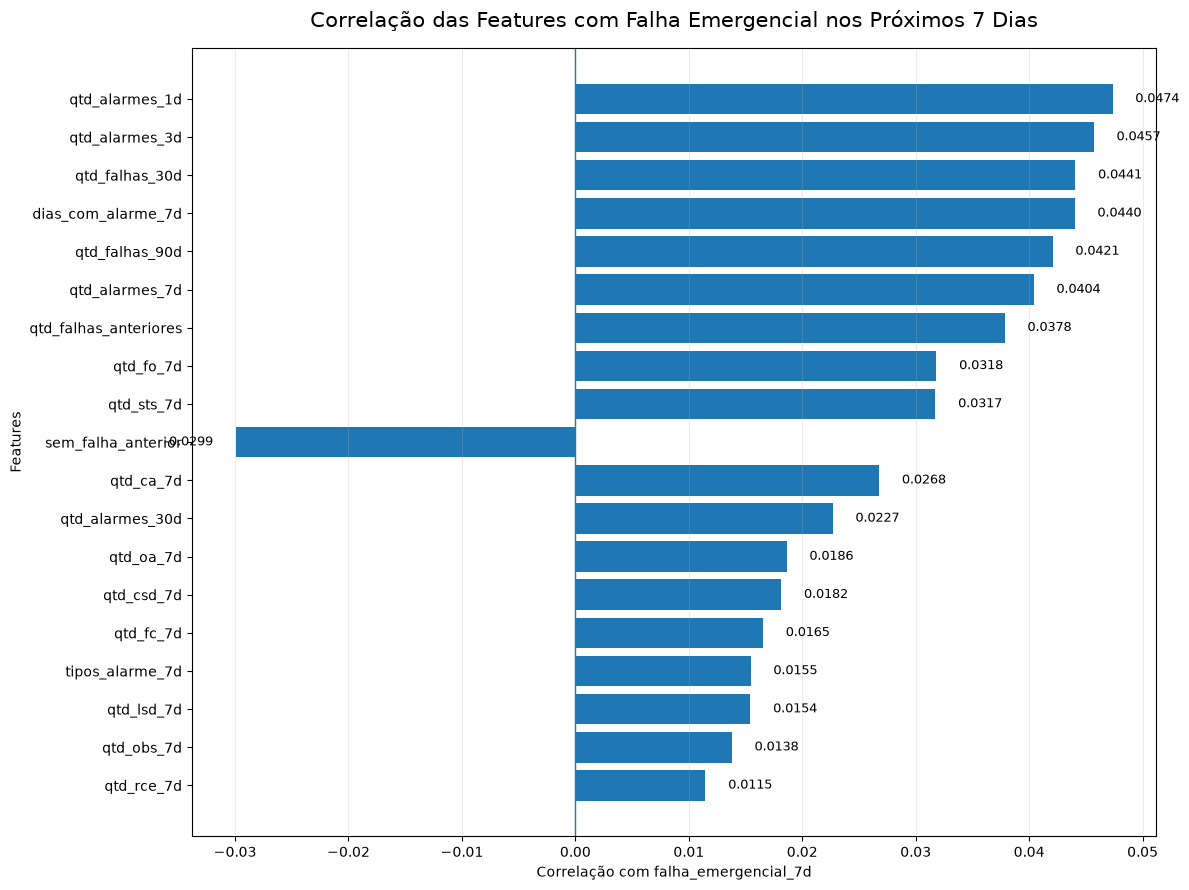

In [145]:
import matplotlib.pyplot as plt

# ==========================================
# CORRELAÇÃO DAS FEATURES COM O TARGET
# ==========================================

target = "falha_emergencial_7d"

# Selecionar apenas colunas numéricas
colunas_numericas = (
    dataset_modelo
    .select_dtypes(include="number")
    .columns
    .tolist()
)

# Calcular correlação com o target
correlacao_target = (
    dataset_modelo[colunas_numericas]
    .corr()[target]
    .drop(target)
    .sort_values(key=abs, ascending=True)
)

# ==========================================
# GRÁFICO
# ==========================================

fig, ax = plt.subplots(figsize=(12, 9))

barras = ax.barh(
    correlacao_target.index,
    correlacao_target.values
)

# Linha central em zero
ax.axvline(
    x=0,
    linewidth=1
)

# Mostrar o valor da correlação em cada barra
for barra, valor in zip(
    barras,
    correlacao_target.values
):
    largura = barra.get_width()
    y = barra.get_y() + barra.get_height() / 2

    deslocamento = 0.002 if valor >= 0 else -0.002

    ax.text(
        largura + deslocamento,
        y,
        f"{valor:.4f}",
        va="center",
        ha="left" if valor >= 0 else "right",
        fontsize=9
    )

ax.set_title(
    "Correlação das Features com Falha Emergencial nos Próximos 7 Dias",
    fontsize=15,
    pad=15
)

ax.set_xlabel(
    "Correlação com falha_emergencial_7d"
)

ax.set_ylabel(
    "Features"
)

ax.grid(
    axis="x",
    alpha=0.25
)

plt.tight_layout()
plt.show()

In [146]:
# ==========================================
# FEATURES CANDIDATAS - ZM02
# ==========================================

programadas_dia = (
    eventos_programada
    .groupby(
        ["chave_porta", "data_programada"]
    )
    .size()
    .reset_index(name="qtd_programadas_dia")
    .rename(columns={"data_programada": "data"})
)

historico_programadas = base_target[
    ["chave_porta", "data"]
].copy()

historico_programadas = historico_programadas.merge(
    programadas_dia,
    on=["chave_porta", "data"],
    how="left"
)

historico_programadas["qtd_programadas_dia"] = (
    historico_programadas["qtd_programadas_dia"]
    .fillna(0)
)

historico_programadas = historico_programadas.sort_values(
    ["chave_porta", "data"]
).reset_index(drop=True)

In [147]:
for janela in [30, 90]:

    historico_programadas[
        f"qtd_programadas_{janela}d"
    ] = (
        historico_programadas
        .groupby("chave_porta")[
            "qtd_programadas_dia"
        ]
        .transform(
            lambda x: x.shift(1)
            .rolling(
                janela,
                min_periods=1
            )
            .sum()
        )
    )
    

In [148]:
historico_programadas["data_com_programada"] = (
    historico_programadas["data"]
    .where(
        historico_programadas[
            "qtd_programadas_dia"
        ] > 0
    )
)

historico_programadas["data_ultima_programada"] = (
    historico_programadas
    .groupby("chave_porta")[
        "data_com_programada"
    ]
    .transform(
        lambda x: x.shift(1).ffill()
    )
)

historico_programadas[
    "dias_desde_ultima_programada"
] = (
    historico_programadas["data"]
    - historico_programadas[
        "data_ultima_programada"
    ]
).dt.days

historico_programadas[
    "sem_programada_anterior"
] = (
    historico_programadas[
        "data_ultima_programada"
    ]
    .isna()
    .astype(int)
)

In [149]:
historico_programadas = historico_programadas[
    historico_programadas["data"]
    >= data_inicio_modelo_efetivo
][
    [
        "chave_porta",
        "data",
        "qtd_programadas_30d",
        "qtd_programadas_90d",
        "dias_desde_ultima_programada",
        "sem_programada_anterior"
    ]
].copy()

In [150]:
base_correlacao = base_features.merge(
    historico_programadas,
    on=["chave_porta", "data"],
    how="left"
)

In [151]:
features_extras_alarme = [
    "qtd_ca_30d",
    "qtd_csd_30d",
    "qtd_fc_30d",
    "qtd_fo_30d",
    "qtd_lsd_30d",
    "qtd_oa_30d",
    "qtd_obs_30d",
    "qtd_rce_30d",
    "qtd_sts_30d",
    "tipos_alarme_30d",
    "dias_com_alarme_30d"
]

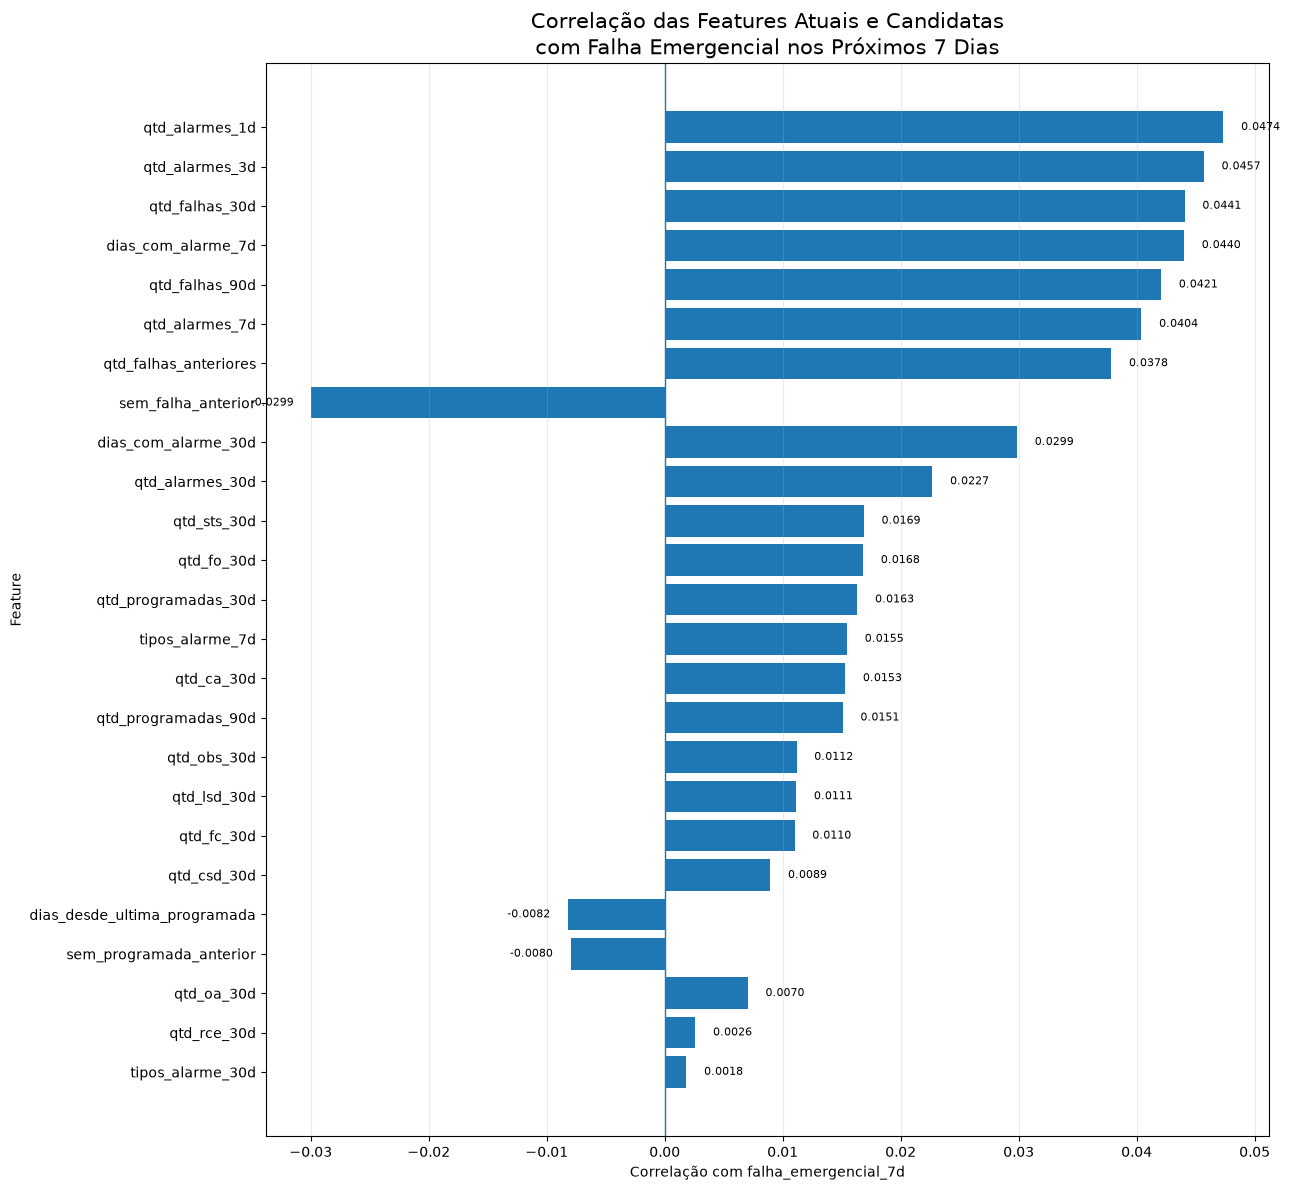

In [152]:
import matplotlib.pyplot as plt

target = "falha_emergencial_7d"

features_candidatas = [
    # Features atuais
    "qtd_alarmes_1d",
    "qtd_alarmes_3d",
    "qtd_alarmes_7d",
    "qtd_alarmes_30d",

    "qtd_falhas_30d",
    "qtd_falhas_90d",
    "qtd_falhas_anteriores",
    "sem_falha_anterior",

    "dias_com_alarme_7d",
    "tipos_alarme_7d",

    # Alarmes - contexto de 30 dias
    *features_extras_alarme,

    # ZM02
    "qtd_programadas_30d",
    "qtd_programadas_90d",
    "dias_desde_ultima_programada",
    "sem_programada_anterior"
]

dados_corr = base_correlacao[
    features_candidatas + [target]
].copy()

correlacoes = (
    dados_corr
    .corr(numeric_only=True)[target]
    .drop(target)
    .sort_values(
        key=abs,
        ascending=True
    )
)

fig, ax = plt.subplots(
    figsize=(13, 12)
)

barras = ax.barh(
    correlacoes.index,
    correlacoes.values
)

ax.axvline(
    0,
    linewidth=1
)

for barra, valor in zip(
    barras,
    correlacoes.values
):
    ax.text(
        valor + (
            0.0015
            if valor >= 0
            else -0.0015
        ),
        barra.get_y()
        + barra.get_height() / 2,
        f"{valor:.4f}",
        va="center",
        ha=(
            "left"
            if valor >= 0
            else "right"
        ),
        fontsize=8
    )

ax.set_title(
    "Correlação das Features Atuais e Candidatas\n"
    "com Falha Emergencial nos Próximos 7 Dias",
    fontsize=15
)

ax.set_xlabel(
    "Correlação com falha_emergencial_7d"
)

ax.set_ylabel(
    "Feature"
)

ax.grid(
    axis="x",
    alpha=0.25
)

plt.tight_layout()
plt.show()

In [153]:

from sklearn.feature_selection import mutual_info_classif

target = "falha_emergencial_7d"

# Features que queremos investigar
features_mi = features_candidatas.copy()

dados_mi = base_correlacao[
    features_mi + [target]
].copy()

# Garantir apenas features numéricas
X_mi = dados_mi[features_mi].copy()
y_mi = dados_mi[target].copy()

# Para a análise exploratória:
# ausência de histórico de recência recebe -1
X_mi = X_mi.fillna(-1)

# Informação mútua
mi = mutual_info_classif(
    X_mi,
    y_mi,
    random_state=42
)

resultado_mi = (
    pd.Series(
        mi,
        index=X_mi.columns,
        name="informacao_mutua"
    )
    .sort_values(ascending=True)
)

/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

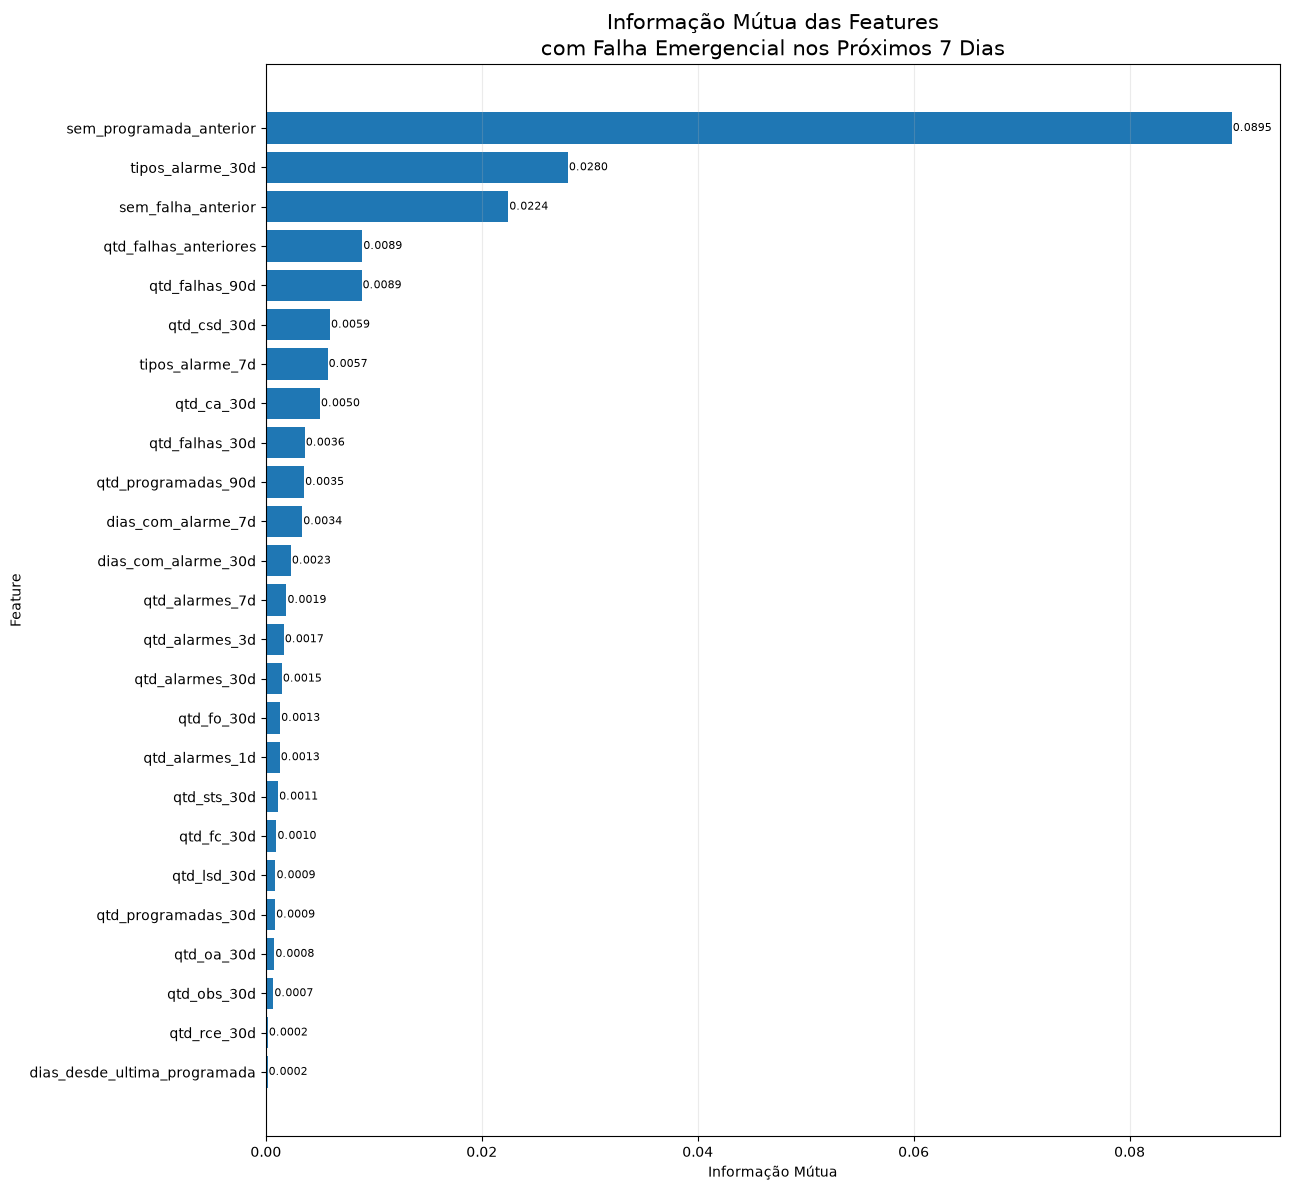

In [154]:
fig, ax = plt.subplots(
    figsize=(13, 12)
)

barras = ax.barh(
    resultado_mi.index,
    resultado_mi.values
)

for barra, valor in zip(
    barras,
    resultado_mi.values
):
    ax.text(
        barra.get_width() + 0.0001,
        barra.get_y() + barra.get_height() / 2,
        f"{valor:.4f}",
        va="center",
        fontsize=8
    )

ax.set_title(
    "Informação Mútua das Features\n"
    "com Falha Emergencial nos Próximos 7 Dias",
    fontsize=15
)

ax.set_xlabel(
    "Informação Mútua"
)

ax.set_ylabel(
    "Feature"
)

ax.grid(
    axis="x",
    alpha=0.25
)

plt.tight_layout()
plt.show()

In [155]:
analise_programada = (
    base_correlacao
    .groupby("sem_programada_anterior")
    ["falha_emergencial_7d"]
    .agg(
        observacoes="count",
        falhas="sum",
        taxa_falha="mean"
    )
)

analise_programada["taxa_falha_pct"] = (
    analise_programada["taxa_falha"] * 100
)

display(analise_programada)

,observacoes,falhas,taxa_falha,taxa_falha_pct
sem_programada_anterior,,,,
0,231868,6908,0.029793,2.979281
1,290794,7889,0.027129,2.712917


In [156]:
base_correlacao["periodo"] = pd.cut(
    base_correlacao["data"],
    bins=[
        pd.Timestamp("2023-01-01"),
        pd.Timestamp("2024-01-01"),
        pd.Timestamp("2025-01-01"),
        pd.Timestamp("2026-01-01")
    ],
    labels=[
        "2023",
        "2024",
        "2025"
    ],
    right=False
)

analise_periodo = (
    base_correlacao
    .groupby(
        [
            "periodo",
            "sem_programada_anterior"
        ],
        observed=True
    )
    ["falha_emergencial_7d"]
    .agg(
        observacoes="count",
        falhas="sum",
        taxa_falha="mean"
    )
    .reset_index()
)

analise_periodo["taxa_falha_pct"] = (
    analise_periodo["taxa_falha"] * 100
)

display(analise_periodo)


,periodo,sem_programada_anterior,observacoes,falhas,taxa_falha,taxa_falha_pct
0,2023,0,28751,1345,0.046781,4.678098
1,2023,1,115253,4212,0.036546,3.654569
2,2024,0,82915,1902,0.022939,2.293915
3,2024,1,106673,1985,0.018608,1.860827
4,2025,0,120202,3661,0.030457,3.045706
5,2025,1,68868,1692,0.024569,2.456874


In [157]:
features_novas = [
    # ZM02
    "sem_programada_anterior",
    "qtd_programadas_30d",
    "qtd_programadas_90d",

    # Alarmes em horizonte maior
    "tipos_alarme_30d",
    "dias_com_alarme_30d",

    "qtd_ca_30d",
    "qtd_csd_30d",
    "qtd_fc_30d",
    "qtd_fo_30d",
    "qtd_lsd_30d",
    "qtd_oa_30d",
    "qtd_obs_30d",
    "qtd_rce_30d",
    "qtd_sts_30d"
]

In [158]:
colunas_modelo_v2 = [
    # originais
    "estacao",
    "plataforma",

    "qtd_alarmes_1d",
    "qtd_alarmes_3d",
    "qtd_alarmes_7d",
    "qtd_alarmes_30d",

    "qtd_ca_7d",
    "qtd_csd_7d",
    "qtd_fc_7d",
    "qtd_fo_7d",
    "qtd_lsd_7d",
    "qtd_oa_7d",
    "qtd_obs_7d",
    "qtd_rce_7d",
    "qtd_sts_7d",

    "dias_com_alarme_7d",
    "tipos_alarme_7d",

    "qtd_falhas_30d",
    "qtd_falhas_90d",
    "qtd_falhas_anteriores",
    "sem_falha_anterior",

    # novas
    *features_novas,

    "data",
    "falha_emergencial_7d"
]

dataset_modelo_v2 = base_correlacao[
    colunas_modelo_v2
].copy()

In [159]:
print("Shape:", dataset_modelo_v2.shape)

print("\nAusentes:")
print(
    dataset_modelo_v2
    .isna()
    .sum()
    .sort_values(ascending=False)
    .head(20)
)

Shape: (522662, 37)

Ausentes:
estacao                  0
plataforma               0
qtd_alarmes_1d           0
qtd_alarmes_3d           0
qtd_alarmes_7d           0
qtd_alarmes_30d          0
qtd_ca_7d                0
qtd_csd_7d               0
qtd_fc_7d                0
qtd_fo_7d                0
qtd_lsd_7d               0
qtd_oa_7d                0
qtd_obs_7d               0
qtd_rce_7d               0
qtd_sts_7d               0
dias_com_alarme_7d       0
tipos_alarme_7d          0
qtd_falhas_30d           0
qtd_falhas_90d           0
qtd_falhas_anteriores    0
dtype: int64


In [160]:
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)
import pandas as pd

# ==========================================
# SPLIT TEMPORAL - DATASET V2
# ==========================================

treino_v2 = dataset_modelo_v2[
    dataset_modelo_v2["data"] <= pd.Timestamp("2025-03-25")
].copy()

validacao_v2 = dataset_modelo_v2[
    (dataset_modelo_v2["data"] >= pd.Timestamp("2025-04-01"))
    & (dataset_modelo_v2["data"] <= pd.Timestamp("2025-06-24"))
].copy()

target = "falha_emergencial_7d"

X_treino_v2 = treino_v2.drop(
    columns=["data", target]
)

y_treino_v2 = treino_v2[target]

X_validacao_v2 = validacao_v2.drop(
    columns=["data", target]
)

y_validacao_v2 = validacao_v2[target]


# ==========================================
# ONE-HOT ENCODING
# ==========================================

X_treino_v2 = pd.get_dummies(
    X_treino_v2,
    columns=["estacao", "plataforma"],
    dtype=int
)

X_validacao_v2 = pd.get_dummies(
    X_validacao_v2,
    columns=["estacao", "plataforma"],
    dtype=int
)

X_validacao_v2 = X_validacao_v2.reindex(
    columns=X_treino_v2.columns,
    fill_value=0
)


# ==========================================
# MESMO EXTRA TREES DA V1
# ==========================================

modelo_extra_tree_v2 = ExtraTreesClassifier(
    n_estimators=300,
    criterion="entropy",
    max_features=0.15,
    max_leaf_nodes=8,
    class_weight={
        0: 1,
        1: 34
    },
    random_state=42,
    n_jobs=-1
)

modelo_extra_tree_v2.fit(
    X_treino_v2,
    y_treino_v2
)


# ==========================================
# AVALIAÇÃO NA VALIDAÇÃO
# ==========================================

y_prob_v2 = modelo_extra_tree_v2.predict_proba(
    X_validacao_v2
)[:, 1]

threshold = 0.50

y_pred_v2 = (
    y_prob_v2 >= threshold
).astype(int)

accuracy_v2 = accuracy_score(
    y_validacao_v2,
    y_pred_v2
)

precision_v2 = precision_score(
    y_validacao_v2,
    y_pred_v2,
    zero_division=0
)

recall_v2 = recall_score(
    y_validacao_v2,
    y_pred_v2,
    zero_division=0
)

f1_v2 = f1_score(
    y_validacao_v2,
    y_pred_v2,
    zero_division=0
)

print("Accuracy:", round(accuracy_v2, 4))
print("Precision:", round(precision_v2, 4))
print("Recall:", round(recall_v2, 4))
print("F1:", round(f1_v2, 4))

print("\nMatriz de confusão:")
print(
    confusion_matrix(
        y_validacao_v2,
        y_pred_v2
    )
)

/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

Accuracy: 0.6231
Precision: 0.0304
Recall: 0.4941
F1: 0.0573

Matriz de confusão:
[[26929 16081]
 [  516   504]]


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

In [161]:
colunas_modelo_v3 = [
    # Contexto
    "estacao",
    "plataforma",

    # Alarmes
    "qtd_alarmes_1d",
    "qtd_alarmes_3d",
    "qtd_alarmes_7d",
    "qtd_alarmes_30d",

    "qtd_ca_7d",
    "qtd_csd_7d",
    "qtd_fc_7d",
    "qtd_fo_7d",
    "qtd_lsd_7d",
    "qtd_oa_7d",
    "qtd_obs_7d",
    "qtd_rce_7d",
    "qtd_sts_7d",

    "dias_com_alarme_7d",
    "tipos_alarme_7d",

    # Histórico de falhas
    "qtd_falhas_30d",
    "qtd_falhas_90d",
    "qtd_falhas_anteriores",
    "sem_falha_anterior",

    # Apenas as duas candidatas
    "sem_programada_anterior",
    "tipos_alarme_30d",

    "data",
    "falha_emergencial_7d"
]

dataset_modelo_v3 = base_correlacao[
    colunas_modelo_v3
].copy()

In [162]:
treino_v3 = dataset_modelo_v3[
    dataset_modelo_v3["data"] <= pd.Timestamp("2025-03-25")
].copy()

validacao_v3 = dataset_modelo_v3[
    (dataset_modelo_v3["data"] >= pd.Timestamp("2025-04-01"))
    & (dataset_modelo_v3["data"] <= pd.Timestamp("2025-06-24"))
].copy()

target = "falha_emergencial_7d"

X_treino_v3 = treino_v3.drop(
    columns=["data", target]
)

y_treino_v3 = treino_v3[target]

X_validacao_v3 = validacao_v3.drop(
    columns=["data", target]
)

y_validacao_v3 = validacao_v3[target]

In [163]:
X_treino_v3 = pd.get_dummies(
    X_treino_v3,
    columns=["estacao", "plataforma"],
    dtype=int
)

X_validacao_v3 = pd.get_dummies(
    X_validacao_v3,
    columns=["estacao", "plataforma"],
    dtype=int
)

X_validacao_v3 = X_validacao_v3.reindex(
    columns=X_treino_v3.columns,
    fill_value=0
)

In [164]:
modelo_extra_tree_v3 = ExtraTreesClassifier(
    n_estimators=300,
    criterion="entropy",
    max_features=0.15,
    max_leaf_nodes=8,
    class_weight={
        0: 1,
        1: 34
    },
    random_state=42,
    n_jobs=-1
)

modelo_extra_tree_v3.fit(
    X_treino_v3,
    y_treino_v3
)

y_pred_v3 = modelo_extra_tree_v3.predict(
    X_validacao_v3
)

print("Accuracy:", round(
    accuracy_score(y_validacao_v3, y_pred_v3), 4
))

print("Precision:", round(
    precision_score(
        y_validacao_v3,
        y_pred_v3,
        zero_division=0
    ), 4
))

print("Recall:", round(
    recall_score(
        y_validacao_v3,
        y_pred_v3,
        zero_division=0
    ), 4
))

print("F1:", round(
    f1_score(
        y_validacao_v3,
        y_pred_v3,
        zero_division=0
    ), 4
))

print("\nMatriz de confusão:")
print(
    confusion_matrix(
        y_validacao_v3,
        y_pred_v3
    )
)

/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

Accuracy: 0.5904
Precision: 0.0326
Recall: 0.5824
F1: 0.0618

Matriz de confusão:
[[25401 17609]
 [  426   594]]


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(


In [ ]:
import matplotlib.pyplot as plt

from sklearn.metrics import (
    roc_auc_score,
    roc_curve,
    average_precision_score,
    precision_recall_curve,
    auc
)

# ==========================================
# PROBABILIDADES - MODELO 4 / V3
# ==========================================

y_prob_v3 = modelo_extra_tree_v3.predict_proba(
    X_validacao_v3
)[:, 1]


# ==========================================
# ROC-AUC
# ==========================================

roc_auc_v3 = roc_auc_score(
    y_validacao_v3,
    y_prob_v3
)

fpr_v3, tpr_v3, _ = roc_curve(
    y_validacao_v3,
    y_prob_v3
)


# ==========================================
# PR-AUC
# ==========================================

precision_curve_v3, recall_curve_v3, _ = (
    precision_recall_curve(
        y_validacao_v3,
        y_prob_v3
    )
)

# Average Precision
pr_auc_v3 = average_precision_score(
    y_validacao_v3,
    y_prob_v3
)

# Area trapezoidal da curva PR
pr_auc_trap_v3 = auc(
    recall_curve_v3,
    precision_curve_v3
)


# ==========================================
# RESULTADOS
# ==========================================

print("Modelo 4 - Extra Trees V3")
print("---------------------------")
print(f"ROC-AUC: {roc_auc_v3:.4f}")
print(f"PR-AUC (Average Precision): {pr_auc_v3:.4f}")
print(f"PR-AUC (trapezoidal):       {pr_auc_trap_v3:.4f}")

/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa

Modelo 4 - Extra Trees V3
---------------------------
ROC-AUC: 0.6075
PR-AUC (Average Precision): 0.0407
PR-AUC (trapezoidal):       0.0403


/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bebaran/Área de trabalho/Projetos Inteli/Motiva - Subway Surfer/g04/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propa